# Исследование подготовки сейсмического датасета #

## Глава 1.5. Геометрия, частота источника и слоистость ##

По решению научной группы рассматриваются 30 односекундных тестов: пять размеров основной области, три варианта материала и две частоты Рикера. Цель — увидеть распространение Vx/Vy и характер поверхностной записи при изменении масштаба и состава среды. Этот дневник читает готовые свидетельства и изображения; он не запускает решатель и не подключается к Saturn.

In [1]:
from IPython.display import Image, display
from scripts.project_paths import PROJECT_ROOT
from scripts.reporting import read_json, mapping, number, sequence

chapter15_root = PROJECT_ROOT / "data/dev_1_5_geometry_frequency/series_v1"
chapter15_images = PROJECT_ROOT / "img/dev_1_5_geometry_frequency/series_v1"
chapter15_plan = read_json(chapter15_root / "plan.json")
chapter15_cpu = read_json(chapter15_root / "cpu_validation.json")
assert chapter15_cpu["status"] == "passed"
print("Число опытов:", len(sequence(chapter15_plan["runs"])))
print("Оценка сырых записей, ГБ:", number(chapter15_plan["estimated_raw_bytes"]) / 1e9)

Число опытов: 30
Оценка сырых записей, ГБ: 9.63137296


## 1. Постановка и геометрии ##

Размеры основной области W×H: 350×350, 700×350, 700×700, 1400×700, 1000×500 м. Координаты x=0…W, y=−H…0; дополнительно по бокам и снизу слой175 м, полный прямоугольник (W+350)×(H+175). Верх, включая боковые продолжения, свободный. Источник — точная узловая сила вниз в (W/2,0), пиковая амплитуда 1 Н/м. Рикер15/30 Гц с t0=1,5/f, то есть 0,1/0,05 с, сохраняет один и тот же малый начальный хвост в безразмерном времени. Входная таблица силы задана через 1 мкс независимо от dt.

Материалы исходят из EFVB00000 при плотности1000 кг/м³. Полная модель имеет пять последовательных слоёв с исходными границами35/70,57/70,59/70,66/70 глубины. Однородная модель использует Vp=4087 м/с, Vs=2431,62036 м/с. Двухслойная использует этот верхний материал и второй Vp=3963 м/с, Vs=2357,84473 м/с; интерфейс расположен на H/2. Полная модель масштабируется x=W·xисх/700, глубина=H·глубинаисх/700. Области2:1 получаются горизонтальным растяжением соответствующего квадратного материала, затем перестраивается сетка около5 м. Материал в слое продлевается плоскопараллельно.

Используется p5, горизонтальный шаг элемента ровно5 м. Вертикальные ряды согласованы с точными интерфейсами, их шаг не превосходит5 м. Для H=500 м исходные относительные глубины не кратны5 м, поэтому некоторые вертикальные размеры немного меньше5 м. Прямоугольные Q2-карты имеют положительный постоянный якобиан каждого элемента; центральный источник и все интерфейсы совпадают с узлами/гранями.

In [2]:
for chapter15_mesh, chapter15_geometry in mapping(chapter15_plan["geometry"]).items():
    chapter15_record = mapping(chapter15_geometry)
    print(chapter15_mesh, "Элементы:", chapter15_record["elements"],
          "Узлы:", chapter15_record["sem_nodes"], "Приёмники:", chapter15_record["surface_nodes"],
          "dy:", chapter15_record["dy_min_m"], chapter15_record["dy_max_m"])

350x350_efvb Элементы: 14700 Узлы: 368726 Приёмники: 701 dy: 5.0 5.0
350x350_homogeneous Элементы: 14700 Узлы: 368726 Приёмники: 701 dy: 5.0 5.0
350x350_two_layer Элементы: 14700 Узлы: 368726 Приёмники: 701 dy: 5.0 5.0
700x350_efvb Элементы: 22050 Узлы: 552826 Приёмники: 1051 dy: 5.0 5.0
700x350_homogeneous Элементы: 22050 Узлы: 552826 Приёмники: 1051 dy: 5.0 5.0
700x350_two_layer Элементы: 22050 Узлы: 552826 Приёмники: 1051 dy: 5.0 5.0
700x700_efvb Элементы: 36750 Узлы: 920676 Приёмники: 1051 dy: 5.0 5.0
700x700_homogeneous Элементы: 36750 Узлы: 920676 Приёмники: 1051 dy: 5.0 5.0
700x700_two_layer Элементы: 36750 Узлы: 920676 Приёмники: 1051 dy: 5.0 5.0
1400x700_efvb Элементы: 61250 Узлы: 1533876 Приёмники: 1751 dy: 5.0 5.0
1400x700_homogeneous Элементы: 61250 Узлы: 1533876 Приёмники: 1751 dy: 5.0 5.0
1400x700_two_layer Элементы: 61250 Узлы: 1533876 Приёмники: 1751 dy: 5.0 5.0
1000x500_efvb Элементы: 36720 Узлы: 920031 Приёмники: 1351 dy: 4.761904761904759 5.0
1000x500_homogeneous Эле

## 2. Демпфирование, интегрирование и регистрация ##

Во всех опытах одна и та же квадратичная функция массового демпфирования C=αM. Множитель k=0,5 относится к прежнему исходному максимуму, который не пересчитывается отдельно под каждый материал или размер:

$$
\alpha_{\max}=0{,}5\frac{-3\cdot4385\ln(0{,}01)}{175}\approx173{,}0886\;\mathrm{с}^{-1}.
$$

$$
\alpha(x,y)=\alpha_{\max}\left[\left(\frac{\max(-x,x-W,0)}{175}\right)^2+\left(\frac{\max(-y-H,0)}{175}\right)^2\right].
$$

В нижних углах вклады складываются, достигая 2αmax. ABC с локальным импедансом материала установлен на внешних боках и дне. Встроенный выбор dt решателя semgpu2 использует cfl_safety=0,8 и tact_dt=0,001 с, параметры Кима beta=1/27, gamma=0,5. Для каждой задачи фактические dt, спектральные оценки, число шагов и SHA native-библиотеки сохраняются отдельно; внешняя оценка шага не используется.

Записываются 21 кадр полного поля Vx/Vy через0,05 с, включая t=0 и1 с, и1001 поверхностный отсчёт через0,001 с. Приёмники — все GLL-узлы верхней грани, включая слой; расстояния между ними неравномерны внутри5-метрового элемента. Поля float64 сохраняются во всех узлах, без пространственного прореживания. На общих временах поверхность побитово сверяется с полными полями. Автоматически проверяются число кадров, времена, конечность и нулевое начальное состояние. Эти проверки не являются независимой валидацией решателя.

In [3]:
chapter15_audit = read_json(chapter15_root / "results_validation.json")
assert chapter15_audit["status"] == "passed" and chapter15_audit["count"] == 30
print("Общий максимум α:", chapter15_plan["alpha_max_s_inv"])
print("Регистрация:", chapter15_plan["receiver_policy"])

Общий максимум α: 173.0886108476381
Регистрация: all GLL nodes on entire free top, including padding


## 3. Результаты и артефакты ##

Каждый опыт считается завершённым только при result.json со status=completed. Анимации используют общие фиксированные физические SymLog-шкалы для всех30 опытов, отдельно для Vx/Vy; линейная окрестность нуля равна10⁻⁴ общего пика. Для сейсмограмм вычисляется собственная общая шкала. Изображение поля получено билинейной интерполяцией сохранённых узлов на экранный растр; это только визуализация, исходные поля не меняются. Анимация содержит все21 сохранённый кадр, воспроизводится с5 кадр/с: движение замедлено в4 раза. Пунктир показывает внутреннее начало демпфирующего слоя, тонкие линии — интерфейсы материалов.

350x350_efvb_15Hz dt: 1.785714285714286e-05 Время с подготовкой: 14.905890620313585
350x350_efvb_30Hz dt: 1.785714285714286e-05 Время с подготовкой: 14.889390581287444
350x350_homogeneous_15Hz dt: 1.8867924528301888e-05 Время с подготовкой: 14.403137899003923
350x350_homogeneous_30Hz dt: 1.8867924528301888e-05 Время с подготовкой: 14.281035599298775
350x350_two_layer_15Hz dt: 1.923076923076923e-05 Время с подготовкой: 14.168666529469192
350x350_two_layer_30Hz dt: 1.923076923076923e-05 Время с подготовкой: 14.006448229774833
700x350_efvb_15Hz dt: 1.785714285714286e-05 Время с подготовкой: 21.489050390198827
700x350_efvb_30Hz dt: 1.785714285714286e-05 Время с подготовкой: 21.50200645532459
700x350_homogeneous_15Hz dt: 1.8867924528301888e-05 Время с подготовкой: 20.72914063744247
700x350_homogeneous_30Hz dt: 1.8867924528301888e-05 Время с подготовкой: 20.918055538088083
700x350_two_layer_15Hz dt: 1.923076923076923e-05 Время с подготовкой: 20.24198183696717
700x350_two_layer_30Hz dt: 1.923

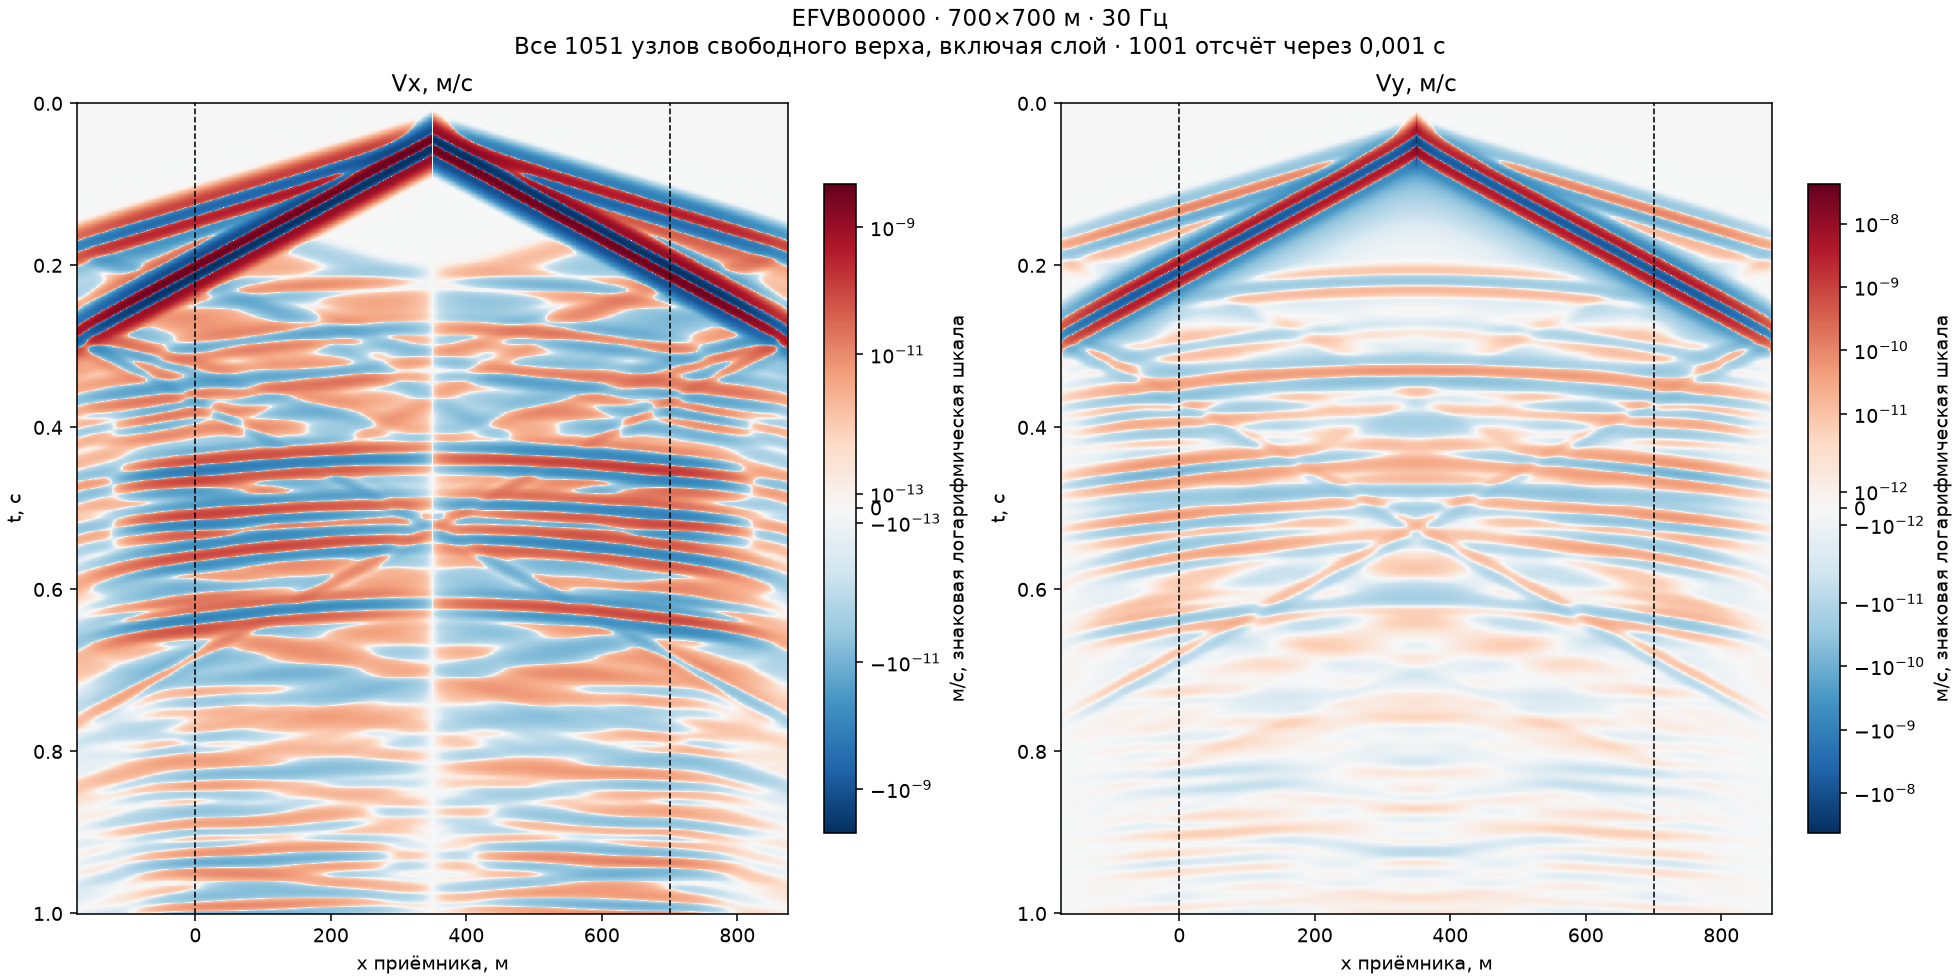

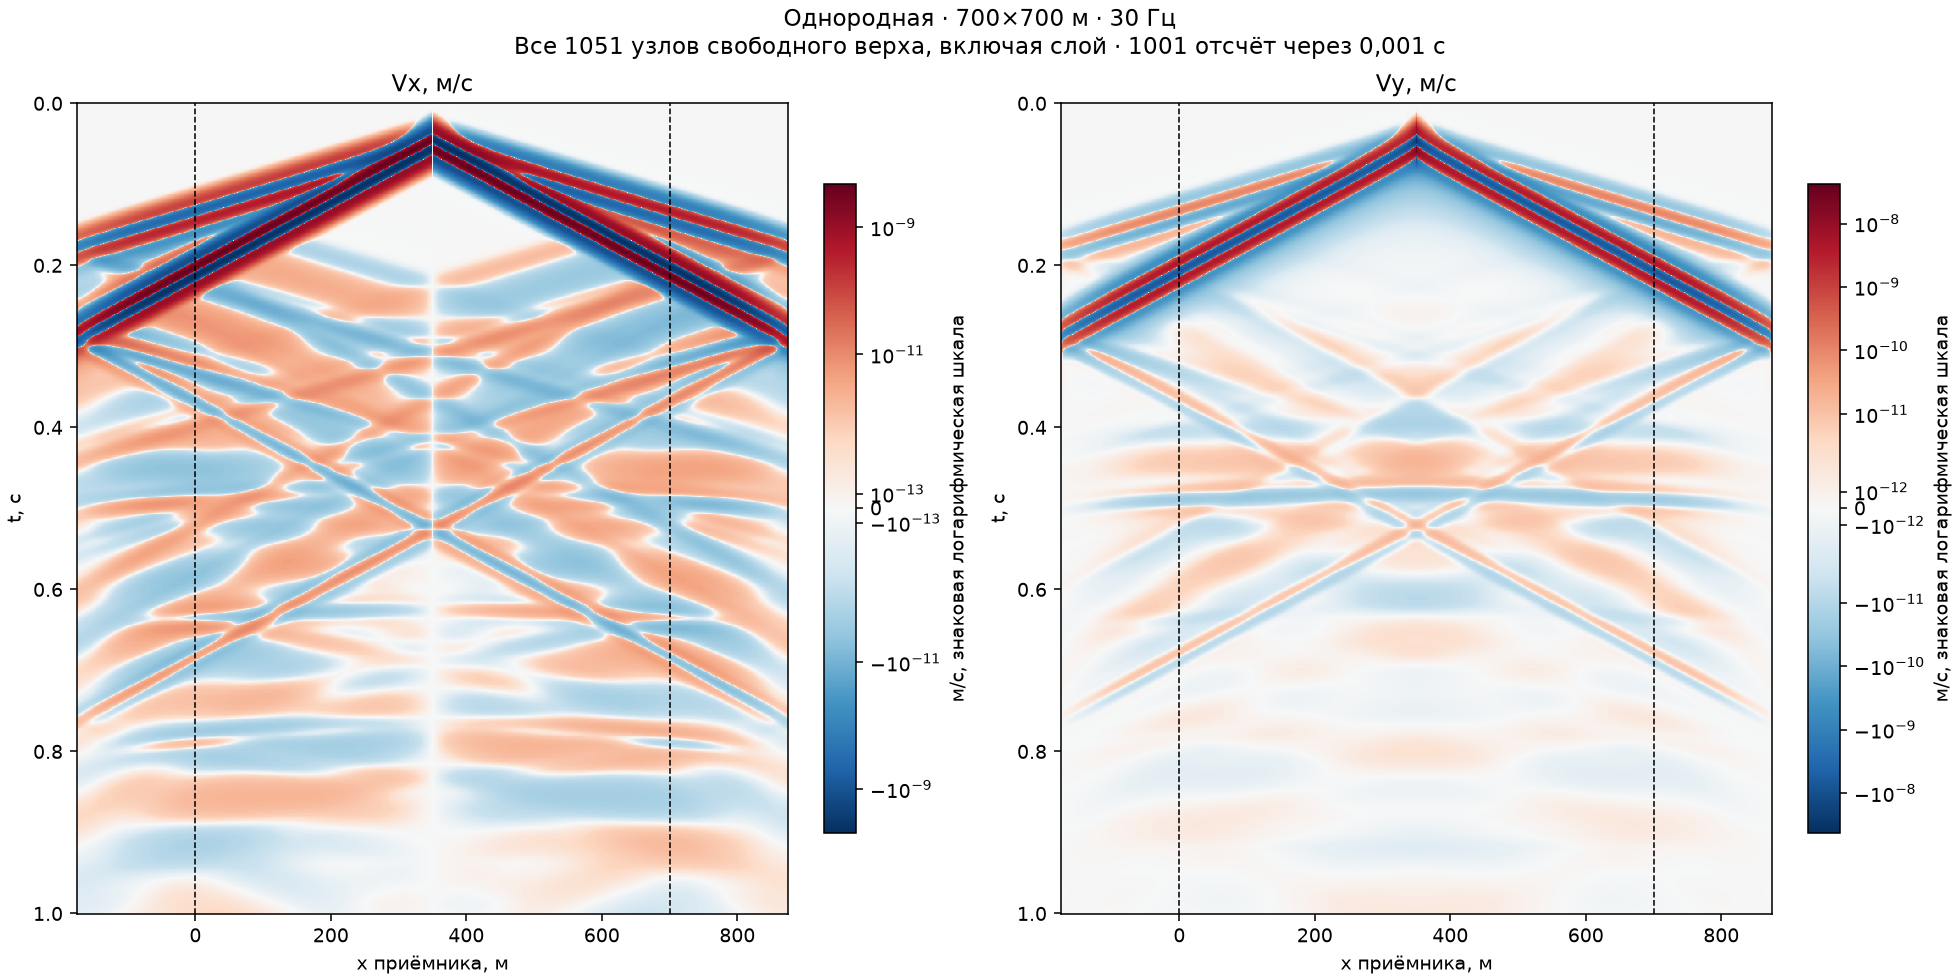

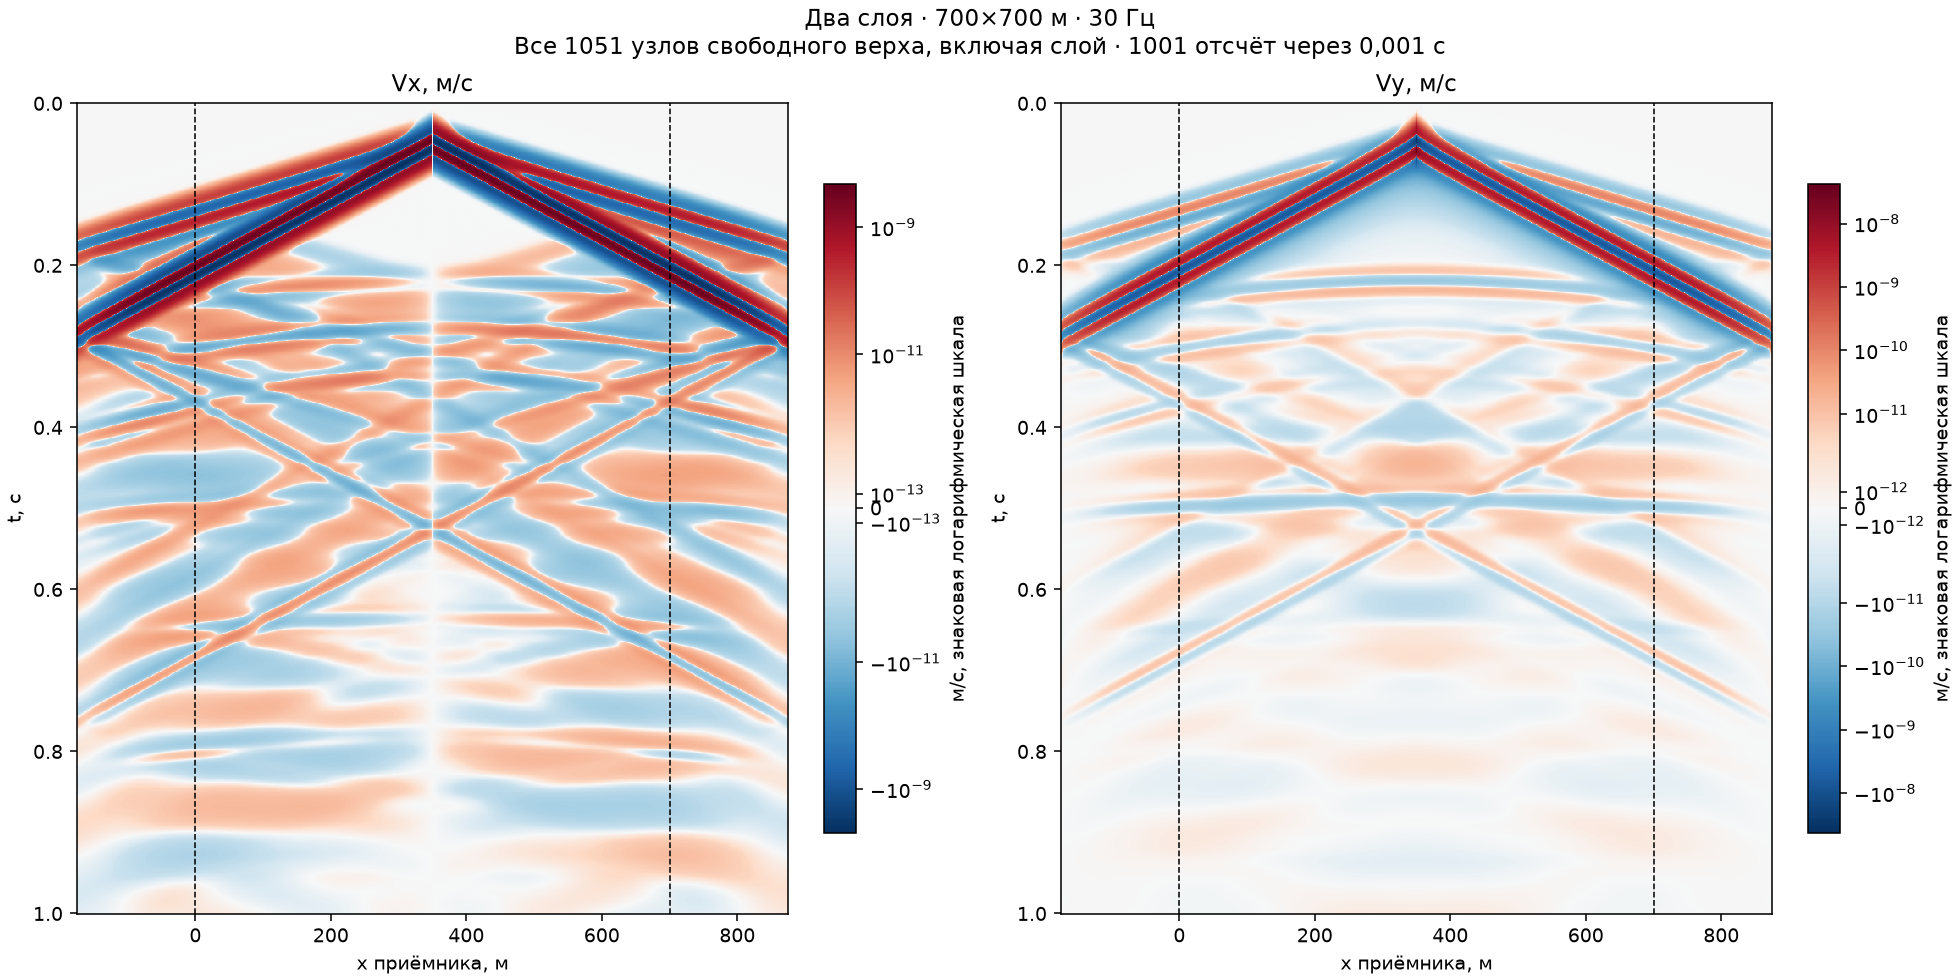

Галерея: /home/antonov/Work/Areas/Seismic/SeismicDataset/img/dev_1_5_geometry_frequency/series_v1/index.html


In [4]:
chapter15_artifact_check = read_json(chapter15_root / "artifact_validation.json")
assert chapter15_artifact_check["status"] == "passed"
assert chapter15_artifact_check["animations"] == chapter15_artifact_check["seismograms"] == 30
chapter15_summary_path = chapter15_root / "summary.json"
if chapter15_summary_path.exists():
    chapter15_summary = read_json(chapter15_summary_path)
    chapter15_runs = mapping(chapter15_summary["runs"])
    assert len(chapter15_runs) == 30
    for chapter15_id, chapter15_run in chapter15_runs.items():
        chapter15_result = mapping(chapter15_run)
        assert chapter15_result["status"] == "completed"
        print(chapter15_id, "dt:", chapter15_result["dt_s"], "Время с подготовкой:", chapter15_result["total_seconds"])
    for chapter15_material in ("efvb", "homogeneous", "two_layer"):
        chapter15_picture = chapter15_images / f"700x700_{chapter15_material}_30Hz/seismogram.png"
        if chapter15_picture.exists():
            display(Image(filename=str(chapter15_picture), width=1100))
    print("Галерея:", chapter15_images / "index.html")
else:
    print("Подготовка завершена; сводка 30 завершённых опытов пока отсутствует.")

## 4. Линейная шкала скорости ##

По дополнительному поручению те же сохранённые Vx/Vy показаны на линейной шкале в физических единицах м/с. Цвет прямо пропорционален знаковой компоненте скорости. Пределы фиксированы на всю серию и на все кадры, совпадают с пределами исходной SymLog-версии; отдельного усиления каждого кадра, каждой модели или каждого приёмника нет. Для полей пределы Vx/Vy равны ±4,3337681·10⁻⁹ / ±1,4072205·10⁻⁸ м/с; для сейсмограмм ±4,8412082·10⁻⁹ / ±4,1914490·10⁻⁸ м/с. Диапазоны вычислены отдельно по полям и поверхности; в частности, эти записи имеют разную временную дискретизацию. Слабые поздние сигналы на линейном изображении заметно бледнее, чем на логарифмическом.

Новые артефакты хранятся в img/dev_1_5_geometry_frequency/linear_v1, прежние в series_v1 сохранены. Созданы и перенесены локально все30 линейных анимаций,30 сейсмограмм и60 статических кадров. Используются исходные21 кадр и1001 поверхностный отсчёт; повторных численных запусков нет. Проверены количество видеокадров, PNG, SHA локальных копий, совпадение входных полей и физических пределов с прежними версиями. SHA исходных логарифмических видео и сейсмограмм остались неизменными. Исходные файлы полей, координат и поверхности проверяются по SHA перед визуализацией. Режим запуска: render.py render --scale linear --index N, затем gallery --scale linear.

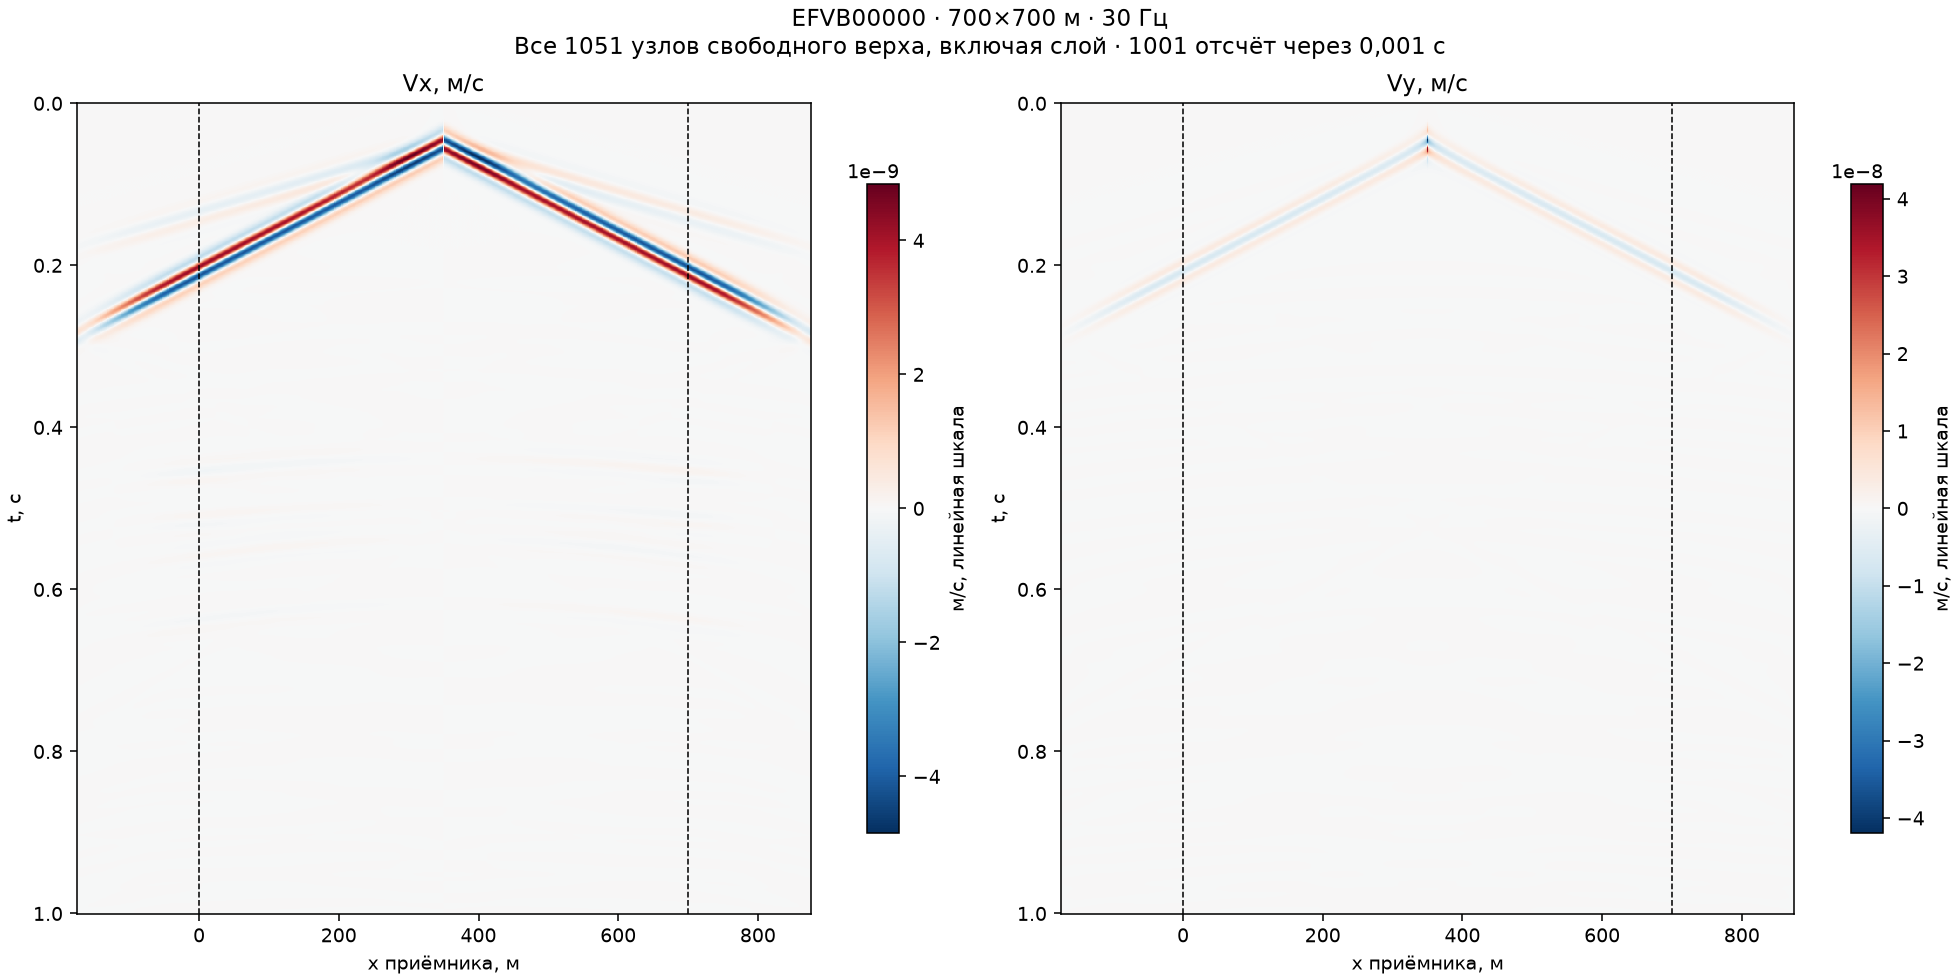

Линейная галерея: /home/antonov/Work/Areas/Seismic/SeismicDataset/img/dev_1_5_geometry_frequency/linear_v1/index.html


In [5]:
chapter15_linear_images = PROJECT_ROOT / "img/dev_1_5_geometry_frequency/linear_v1"
chapter15_linear_check_path = chapter15_root / "linear_artifact_validation.json"
if chapter15_linear_check_path.exists():
    chapter15_linear_check = read_json(chapter15_linear_check_path)
    assert chapter15_linear_check["status"] == "passed"
    assert chapter15_linear_check["animations"] == chapter15_linear_check["seismograms"] == 30
    display(Image(filename=str(chapter15_linear_images / "700x700_efvb_30Hz/seismogram.png"), width=1100))
    print("Линейная галерея:", chapter15_linear_images / "index.html")
else:
    print("Линейная визуализация ещё не прошла итоговую проверку всех30 комплектов.")

## 5. Общий диапазон ±1e−10 м/с ##

Следующее поручение задаёт одинаковый линейный диапазон от−1e−10 до+1e−10 м/с для обеих компонент, всех полей, сейсмограмм, моделей и времён. Значения внутри диапазона отображаются линейно; при превышении используются крайние цвета. Треугольные окончания цветовых шкал отмечают насыщение. Исходные значения скорости не обрезаются и не меняются. Пределы заданы явно, без автоматического выбора по кадру или модели.

Артефакты находятся отдельно в img/dev_1_5_geometry_frequency/linear_limit_1e-10_v1. Источники данных — прежние серии30 расчётов; новые расчёты волн не выполняются. В render.json отдельно сохранены исходные максимумы и фактические диапазоны отображения display_field_limits_m_s/display_surface_limits_m_s. Обе прежние галереи сохранены.

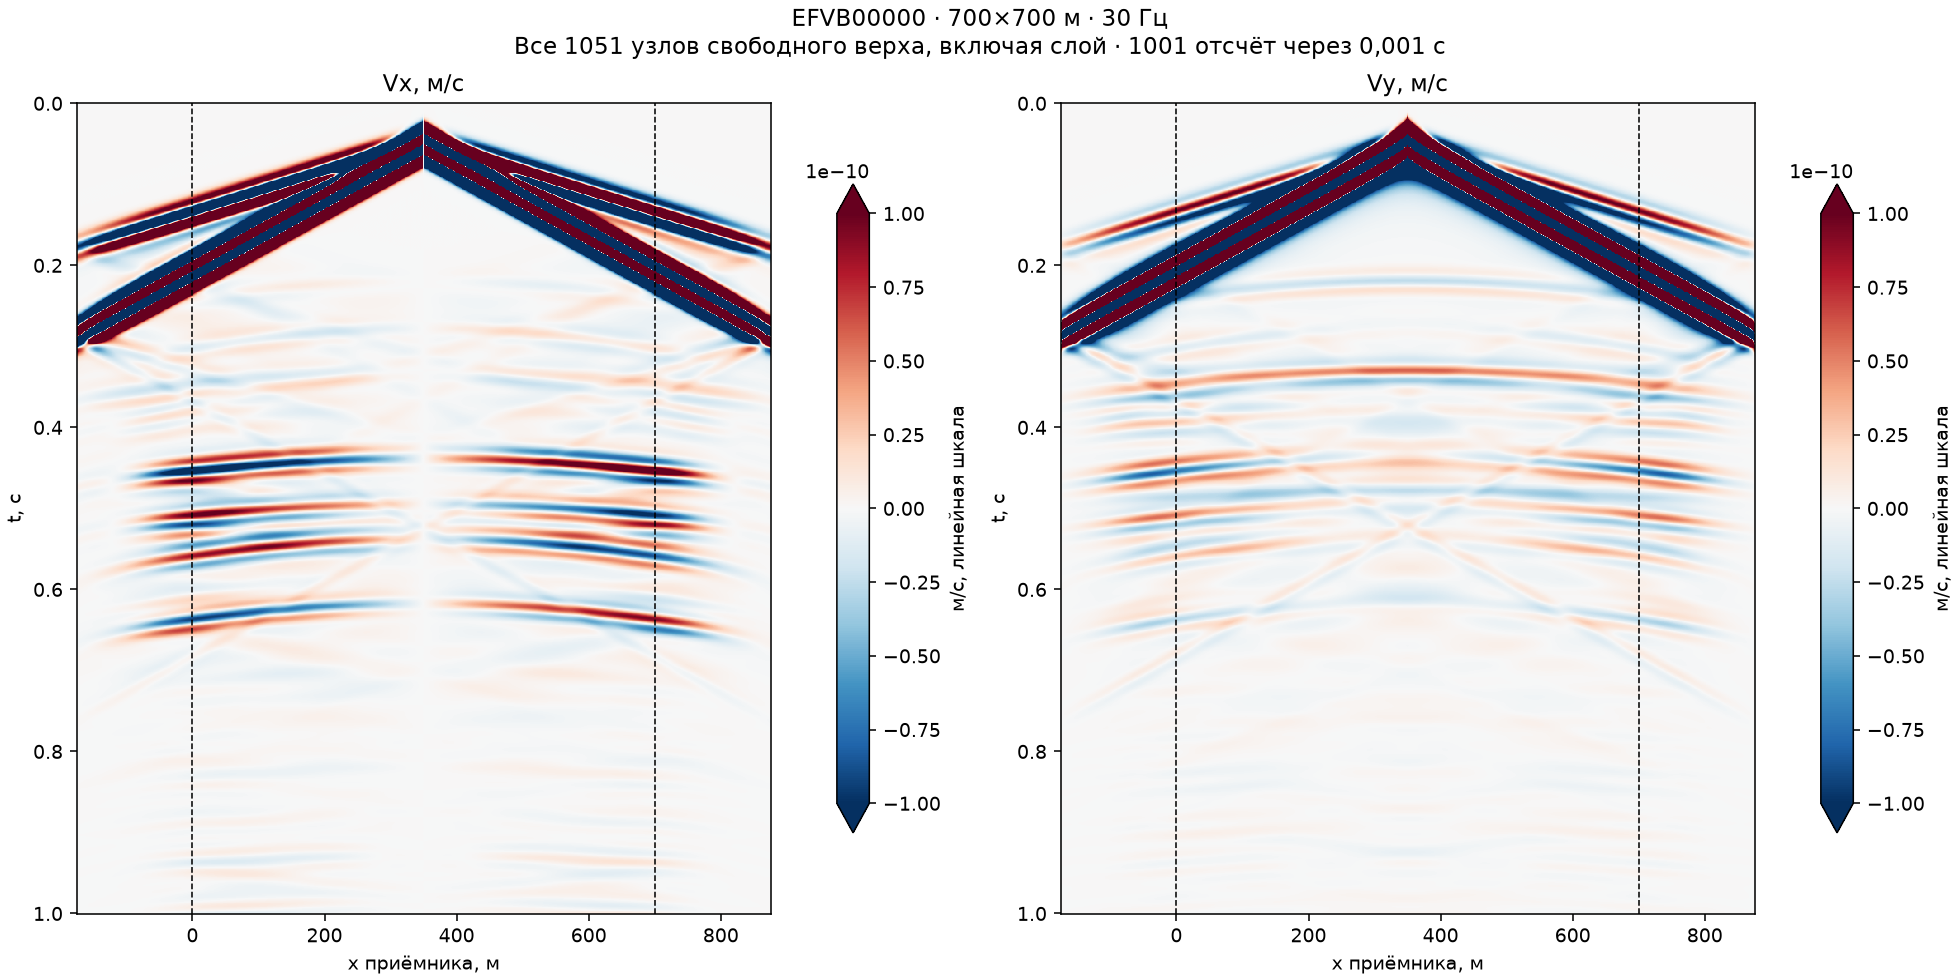

Галерея с диапазоном ±1e−10 м/с: /home/antonov/Work/Areas/Seismic/SeismicDataset/img/dev_1_5_geometry_frequency/linear_limit_1e-10_v1/index.html


In [6]:
chapter15_limit_images = PROJECT_ROOT / "img/dev_1_5_geometry_frequency/linear_limit_1e-10_v1"
chapter15_limit_check_path = chapter15_root / "linear_limit_1e-10_validation.json"
if chapter15_limit_check_path.exists():
    chapter15_limit_check = read_json(chapter15_limit_check_path)
    assert chapter15_limit_check["passed"] is True
    assert chapter15_limit_check["animations"] == chapter15_limit_check["seismograms"] == 30
    display(Image(filename=str(chapter15_limit_images / "700x700_efvb_30Hz/seismogram.png"), width=1100))
    print("Галерея с диапазоном ±1e−10 м/с:", chapter15_limit_images / "index.html")
else:
    print("Комплект с диапазоном ±1e−10 м/с ещё не прошёл итоговую проверку.")

## 6. Старый tenzor и новый seismic на A100 ##

Для двухслойной модели1400×700 м проведено отдельное сравнение lin_elast_2d_tenzor_newmark_kim_cu и lin_elast_2d_seismic_newmark_kim_cu. Используются p5/5 м, источник15/30 Гц, прежние слой/ABC/Ким и1 с. Область со слоем1750×875 м. После двух полных прогревов выполняются по три опыта каждой пары решатель/частота, последовательно на одной A100, с чередованием порядка. Основная очередь не возобновляется. Измеряемое run включает интегрирование, передачу и регистрацию21 поля и1001 поверхностного отсчёта; это практическое время данного теста, не чистое время CUDA-ядер.

Контроль — старый решатель на той же сетке и шаге. Сравниваются все сохранённые узлы/времена отдельно по Vx и Vy. Норма разности определяется так:

$$
\varepsilon_c=\sqrt{\frac{\sum_{t,i}(v^{new}_{c,t,i}-v^{old}_{c,t,i})^2}{\sum_{t,i}(v^{old}_{c,t,i})^2}}.
$$

Суммирование невзвешенное по сохранённым узлам и временам; это норма массива скоростей, а не механическая энергия. Дополнительно сохраняются max|Δv| в м/с и max|Δv|/max|vold|. Критерий согласования до запуска: εc<1e−8 и нормированный максимум<1e−7 для каждой компоненты поля и поверхности. Это проверка согласования двух реализаций на одном тесте; старый решатель не является точным аналитическим решением. Разные результаты округления не трактуются как побитовое равенство.

Согласование всех повторов: True
15 Гц tenzor run, с: [45.300446316599846, 45.31607872620225, 45.34002765920013]
15 Гц seismic run, с: [35.320712237618864, 35.33179143629968, 35.398837024345994]
30 Гц tenzor run, с: [45.35719092749059, 45.348540507256985, 45.320935163646936]
30 Гц seismic run, с: [35.380033493973315, 35.32050196547061, 35.32123879157007]


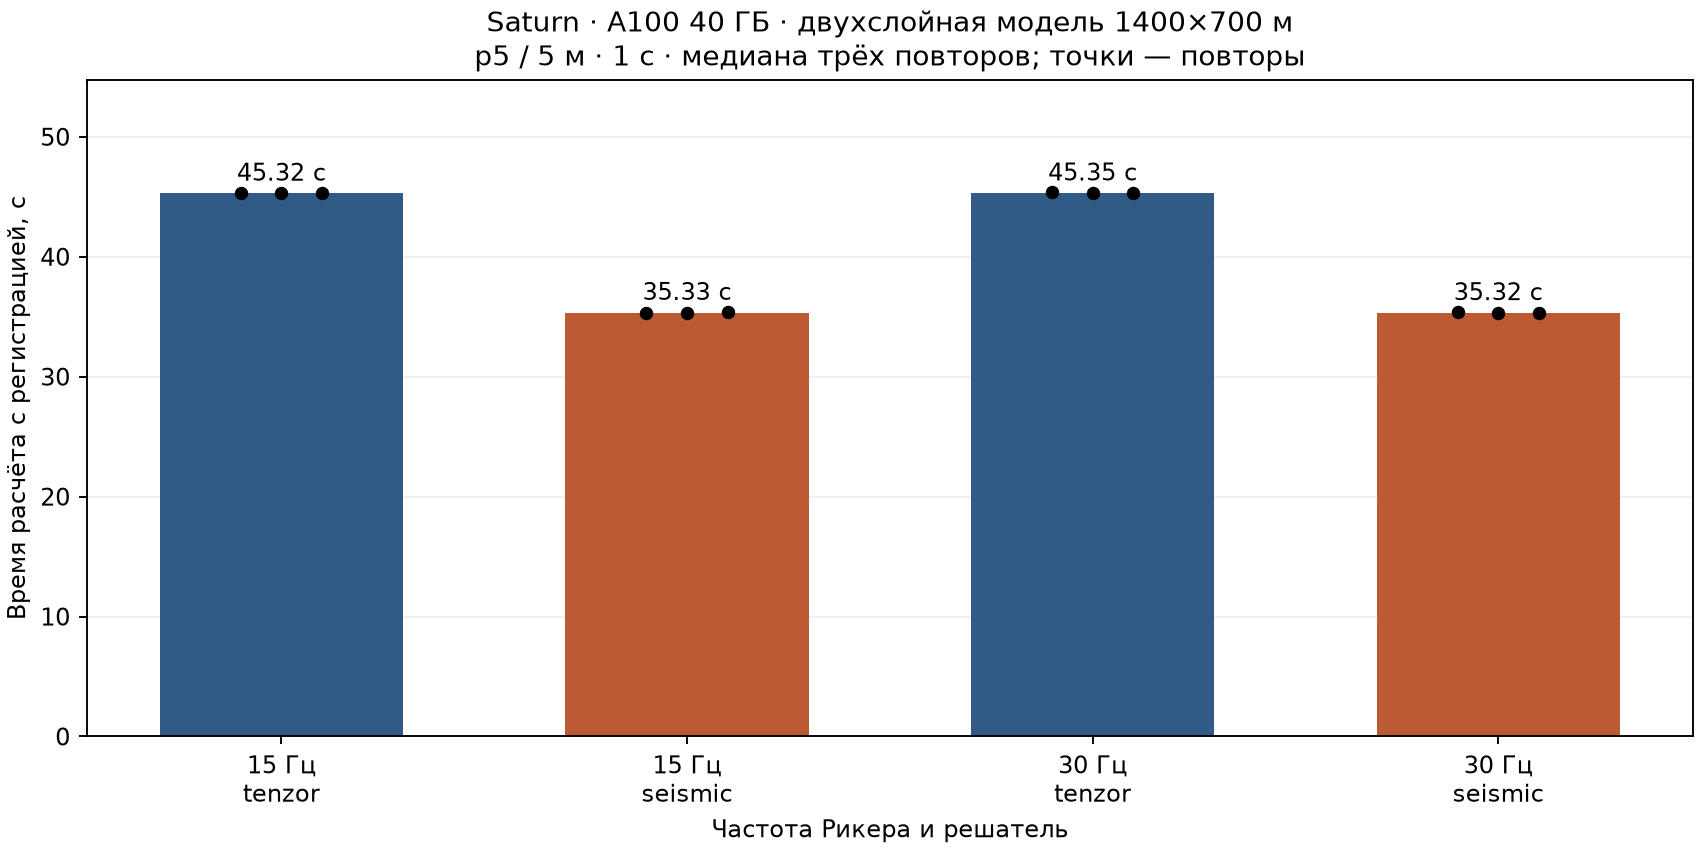

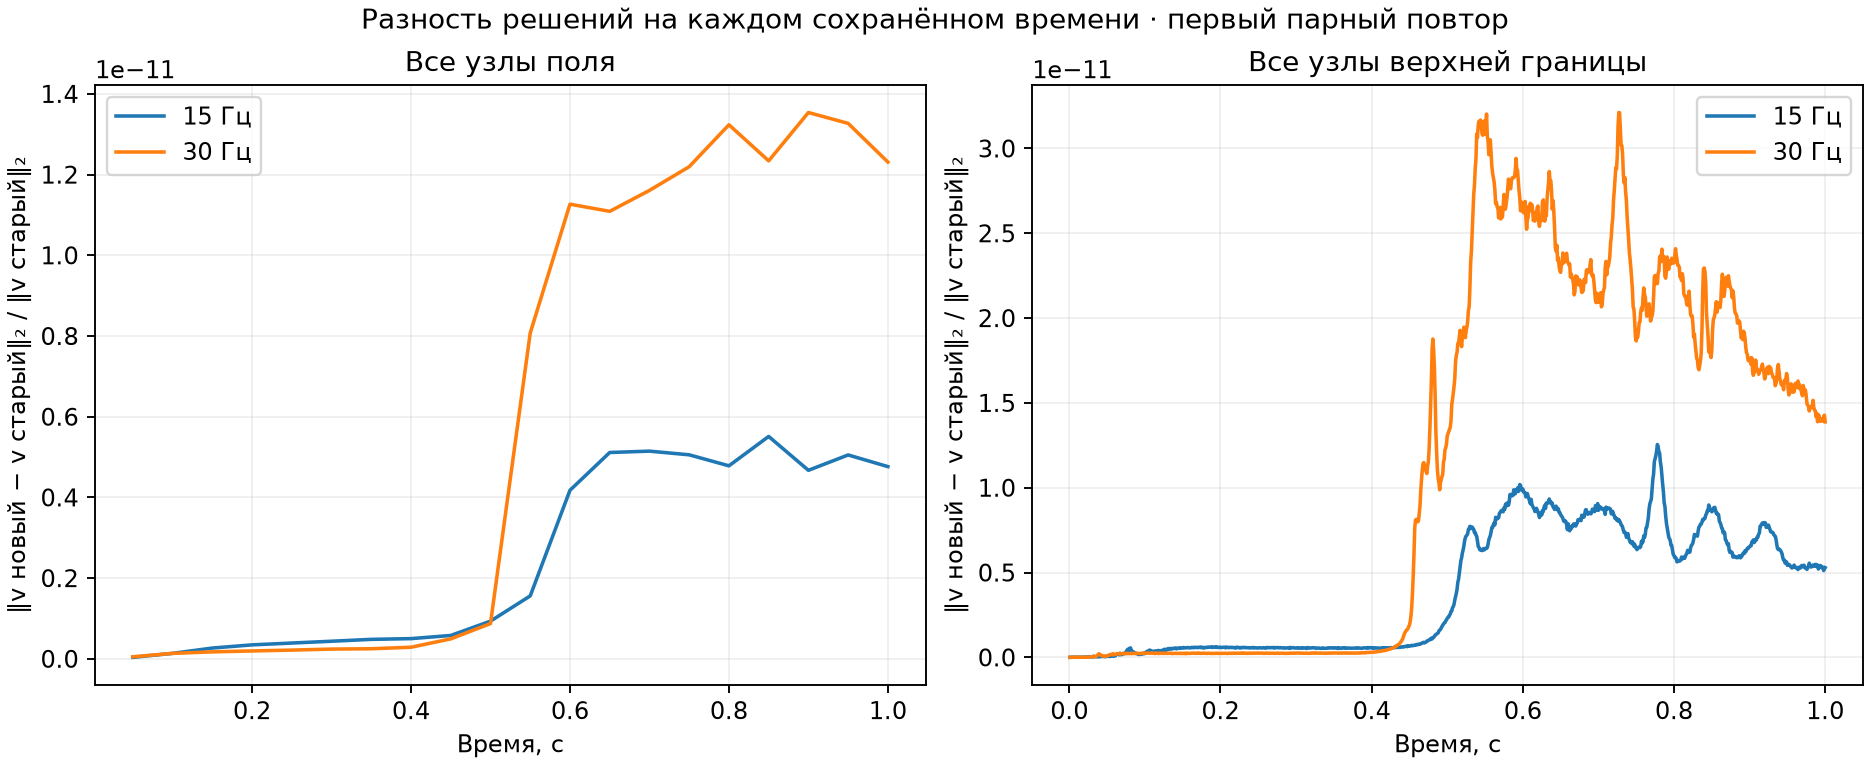

In [7]:
chapter15_compare_path = chapter15_root.parent / "solver_comparison_v1/analysis.json"
if chapter15_compare_path.exists():
    chapter15_compare = read_json(chapter15_compare_path)
    assert chapter15_compare["status"] == "completed"
    print("Согласование всех повторов:", chapter15_compare["all_agree"])
    for chapter15_timing in sequence(chapter15_compare["timings"]):
        chapter15_timing_row = mapping(chapter15_timing)
        print(chapter15_timing_row["frequency_hz"], "Гц", chapter15_timing_row["backend"], "run, с:", chapter15_timing_row["run_seconds"])
    chapter15_compare_image = PROJECT_ROOT / "img/dev_1_5_geometry_frequency/solver_comparison_v1/performance.png"
    if chapter15_compare_image.exists():
        display(Image(filename=str(chapter15_compare_image), width=1100))
        display(Image(filename=str(chapter15_compare_image.with_name("agreement.png")), width=1100))
else:
    print("Сравнение решателей пока не завершено; подготовка не является результатом измерения.")

Все14 опытов завершены:2 прогрева и12 измеряемых запусков. Обе встроенные оценки дали K52, dt=1/52000 с≈19,230769 мкс, принудительное выравнивание шага не потребовалось. Медианы run старый→новый:15 Гц45,316079→35,331791 с;30 Гц45,348541→35,321239 с. Ускорение1,2826/1,2839 раза, сокращение времени22,03/22,11%. Медианы полного времени до контрольного хеширования50,770959→40,354155 с и50,715374→40,134359 с. Подготовка занимает примерно0,58→0,48 с. Время включает запись21 полного поля и1001 отсчёта1751 приёмника; отдельного измерения только CUDA-ядер не выполнялось.

Согласование прошло во всех6 парных сравнениях. Максимальная relative L2 отдельной компоненты среди полей и сейсмограмм6,844654e−13; максимальная абсолютная разность1,134892e−20 м/с. Общая двухкомпонентная L2 полей≤4,990707e−13, поверхности≤5,905805e−13. Максимальная разность, нормированная на пик соответствующей компоненты старого решения,≤2,031766e−12. Побитового равенства нет. Разности сопоставимы с повтором старого решателя относительно исторического опыта: relative L2 компоненты до6,807757e−13. Это согласование реализаций на данном тесте, а не независимая проверка решателя или доказательство эквивалентности для всех геометрий/порядков. Производственный решатель не переключался, очередь остаётся остановленной.

## 7. Профилирование CUDA-ядер на Saturn и RTX 3060 ##

По отдельному поручению повторён только двухслойный тест1400×700 м,30 Гц,1 с на новом lin_elast_2d_seismic_newmark_kim_cu. Сетка, сила, материал, демпфирование, ABC, β=1/27 и регистрация сохраняются. Nsight Systems записывает CUDA- и NVTX-события; CPU sampling и переключения контекста выключены. Метки semgpu_prepare и semgpu_run ограничивают подготовку и основной цикл. Суммируются фактические интервалы ядер всех потоков процесса внутри соответствующей метки; проценты считаются относительно суммы времени ядер. Отдельно учтены memcpy, memset, CPU-вызовы CUDA и объединение интервалов активности GPU без двойного счёта перекрытий.

Время CPU-вызова cudaStreamSynchronize включает ожидание GPU и не прибавляется к длительности ядер. Разность между длительностью этапа и объединением GPU-интервалов содержит работу и ожидания CPU, передачу результатов обработчикам, запись и прочие промежутки; она не означает простой всей видеокарты. Аппаратные счётчики Nsight Compute не собирались, поэтому ограничение пропускной способностью памяти, FP64 или атомарными операциями этим опытом не устанавливается.

Новый native на Saturn сохранён от предыдущего сравнения (CUDA12.0, SM80), локально собран в отдельной среде из того же пофайлового снимка (CUDA12.8, SM86). На Saturn используется Nsight2024.6.2. Первичная локальная запись profile_local_v1 этой версией дала предупреждение о драйвере13.0; она сохранена исторически. Итоговый локальный повтор profile_local_v2 выполнен установленным Nsight2026.5.2. Различия компиляторов и профилировщиков учитываются как ограничение сравнения двух окружений.

saturn этап, с: 35.641855531 ядра, с: 32.603777592
local этап, с: 180.844662025 ядра, с: 175.850486363


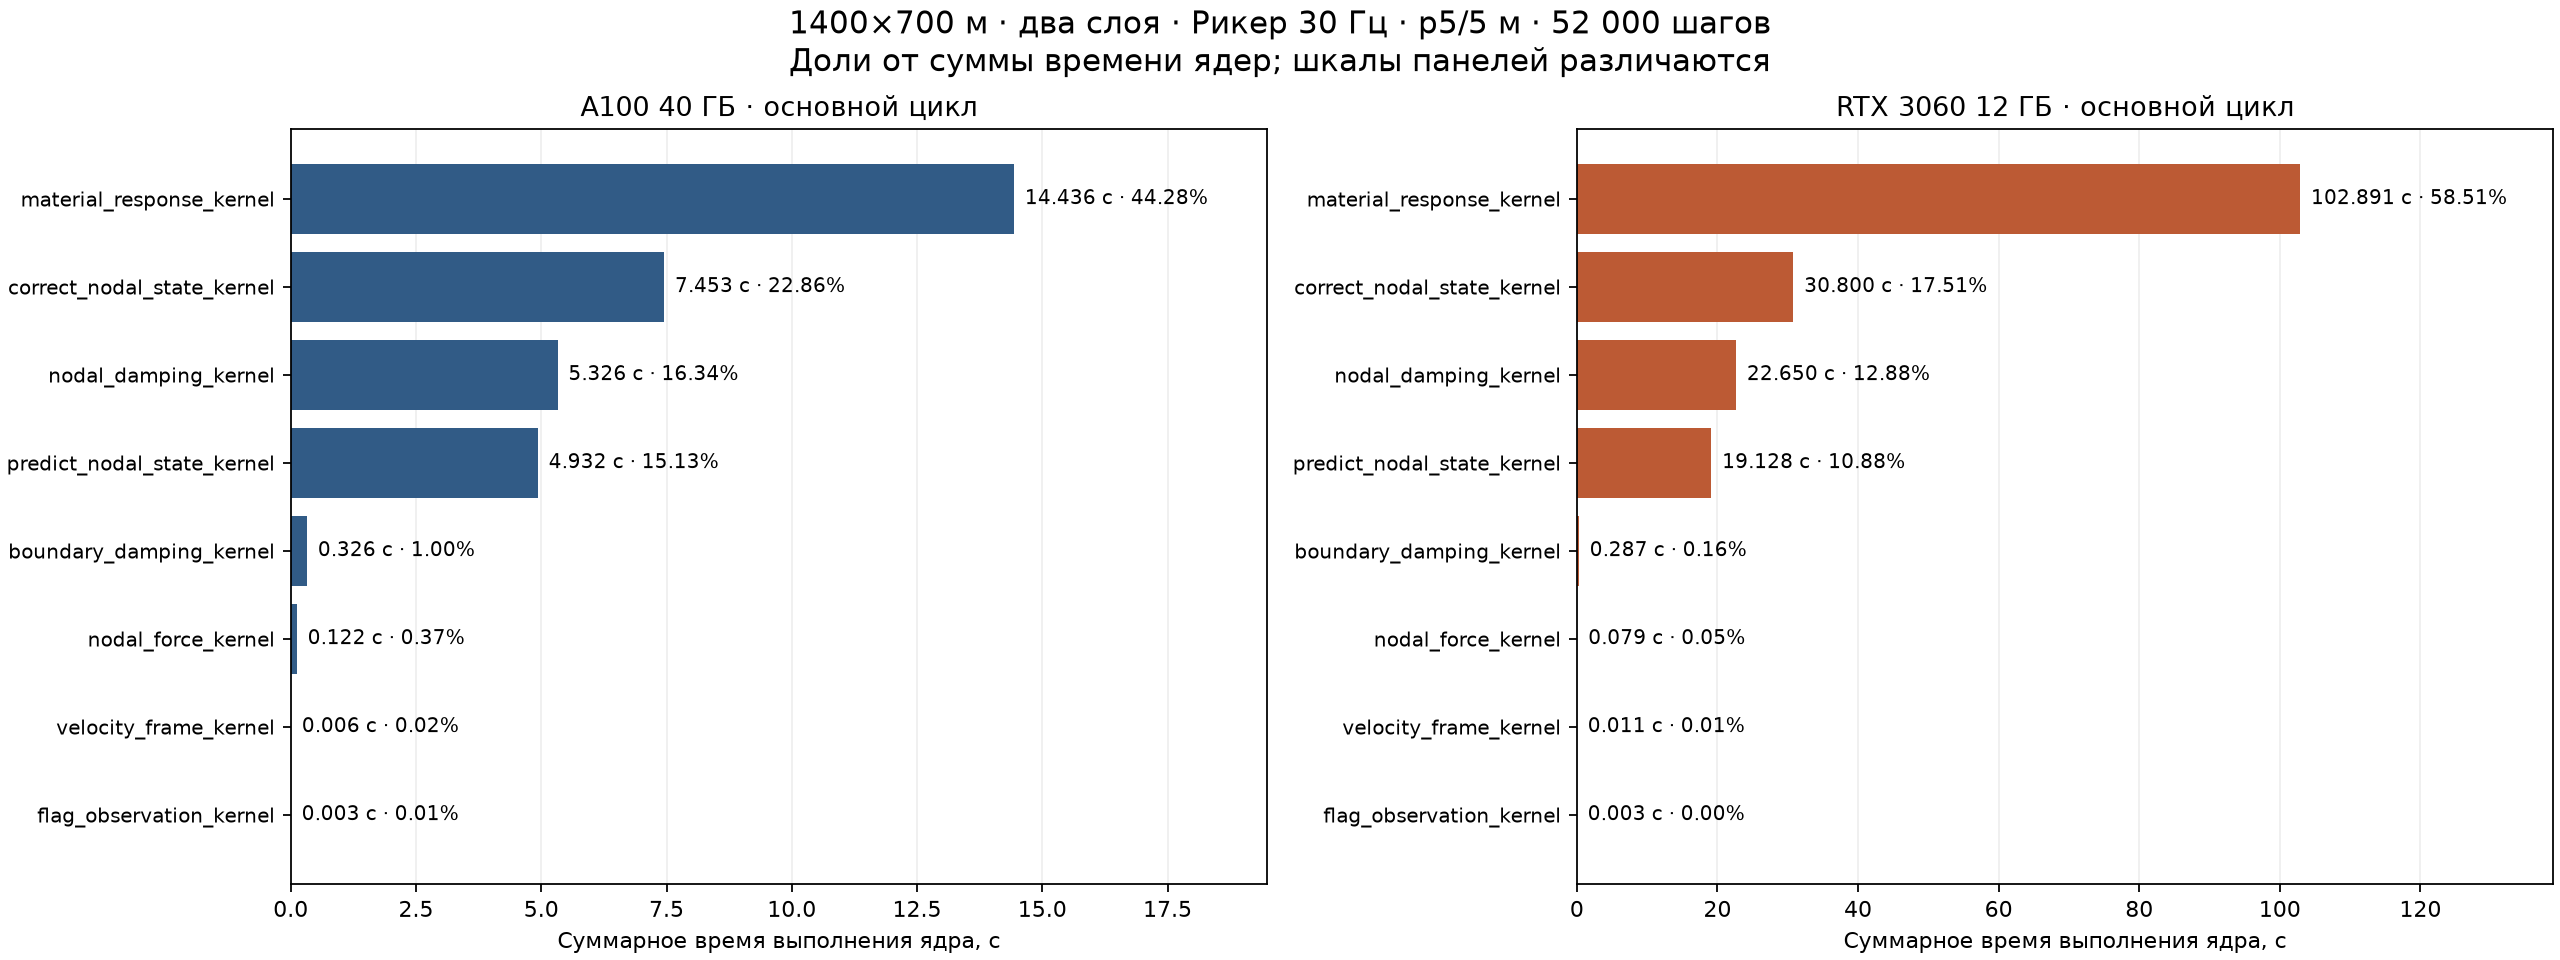

Полный профиль: /home/antonov/Work/Areas/Seismic/SeismicDataset/img/dev_1_5_geometry_frequency/profile_v1/index.html


In [8]:
chapter15_profile_path = chapter15_root.parent / "profile_analysis_v1/comparison.json"
if chapter15_profile_path.exists():
    chapter15_profile = read_json(chapter15_profile_path)
    assert chapter15_profile["status"] == "completed"
    for chapter15_host, chapter15_profile_row in mapping(chapter15_profile["profiles"]).items():
        chapter15_profile_run = mapping(mapping(chapter15_profile_row)["run"])
        print(chapter15_host, "этап, с:", chapter15_profile_run["wall_seconds"], "ядра, с:", chapter15_profile_run["kernel_total_seconds"])
    display(Image(filename=str(PROJECT_ROOT / "img/dev_1_5_geometry_frequency/profile_v1/kernels.png"), width=1300))
    print("Полный профиль:", PROJECT_ROOT / "img/dev_1_5_geometry_frequency/profile_v1/index.html")
else:
    print("Итоговая сводка профилирования пока не готова.")

Профилирование завершено: основной цикл занимает35,641856 с на A100 и180,844662 с на RTX3060. Суммы времени ядер32,603778/175,850486 с; зарегистрировано314044 вызова, в том числе по52000 для шести основных ядер и по1022 для сборки/проверки кадров. Лидирует material_response_kernel:14,436115 с (44,277%) /102,891325 с (58,511%). Далее correct_nodal_state_kernel7,453163/30,799685 с, nodal_damping_kernel5,325869/22,650259 с, predict_nodal_state_kernel4,932355/19,128476 с. ABC занимает0,325639/0,287455 с, источник0,122244/0,079254 с. Доли относятся к суммарному времени ядер, не ко всему этапу.

Суммарные CUDA memcpy занимают0,214878/0,099250 с, memset0,930541/3,763369 с. Объединение зарегистрированных GPU-интервалов33,749196/179,713106 с, остаток внутри этапа1,892659/1,131556 с. На A100 профилированный run примерно на0,9% длиннее прежней медианы35,321239 с; отдельный локальный запуск без профилировщика в этой задаче не выполнялся. Подготовка0,484193/0,336085 с, GPU-ядра подготовки0,019616/0,103829 с. Прямое GPU-время кадров/источника/ABC мало; приоритет дальнейшего исследования — упругий отклик и узловые проходы. Носитель демпфирования в текущем запускателе включает все1533876 узлов, хотя982101 узел основной области имеет α=0; сужение носителя является кандидатом для будущей проверки, а не уже измеренным ускорением.

Первичная локальная запись Nsight2024.6.2 сохранена в profile_local_v1, но исключена из итогового сравнения из-за предупреждения о драйвере. В принятой profile_local_v2 Nsight2026.5.2 предупредил о возможной неполноте NVTX; обе заданные метки присутствуют с началом и концом, их длительности согласуются с таймером запускателя, все ожидаемые314044 вызова основных ядер учтены. Это предупреждение сохранено в validation.json и отчёте. Сейсмограммы A100/RTX3060 согласуются: относительная L2=8,016153e−13, max|Δv|=1,193053e−20 м/с, сетка и шаг одинаковы. Это контроль сохранённой поверхности, не новое полное межплатформенное сравнение всех полей. Nsight-трассы не доказывают конкретную причину ограничения ядра (FP64/память/атомики); аппаратные счётчики не собирались.

## 8. Экспериментальная специализация ALine p5 ##

Завершённое серверное сравнение p5_saturn_v1 использует полную двухслойную задачу1400×700 м,30 Гц,1 с и прежнюю регистрацию21 полного поля/1001 отсчёта поверхности. Сравниваются tenzor, текущий общий seismic и экспериментальный seismic_p5. Общий seismic изменился после §6–7, поэтому оба новых варианта собраны из одного снимка seismic_p5_v1; прежний снимок seismic_cu_v1 сохранён. Библиотека tenzor копируется из среды прежнего сравнения. На A1000 — один полный прогрев каждого решателя, затем три повтора с циклическим чередованием порядка. Локальная серия p5_local_v1 остановлена по уточнению пользователя, незавершённые результаты сохранены и исключены из итога. Это время практического расчёта с регистрацией, без профилировщика; подготовка выделена отдельно.

Встроенные78 FP64-коэффициентов W/V/G экспериментального решателя побитово сопоставлены со штатным ALine(order=5). build_sem использует первый фактор с быстрым индексом j=j0+6j1 и ID0 в обоих пространствах; грани содержат6 позиций. Шаг выбирается native CFL0,8; при разных шагах прогревов запускатель использует минимальный общий dt для измеряемых повторов. Порог согласования прежний: относительная L2 каждой компоненты<1e−8 и max|Δv|/max|vref|<1e−7 для всех сохранённых полей и сейсмограмм. Контроль — tenzor на той же сетке и шаге, не аналитическое решение.

saturn согласование: True
tenzor run, с: [45.328337233513594, 45.34044583886862, 45.26527692936361]
seismic run, с: [33.414625943638384, 33.42377908248454, 33.494886324740946]
seismic_p5 run, с: [31.56117276661098, 31.455316920764744, 31.414833429269493]


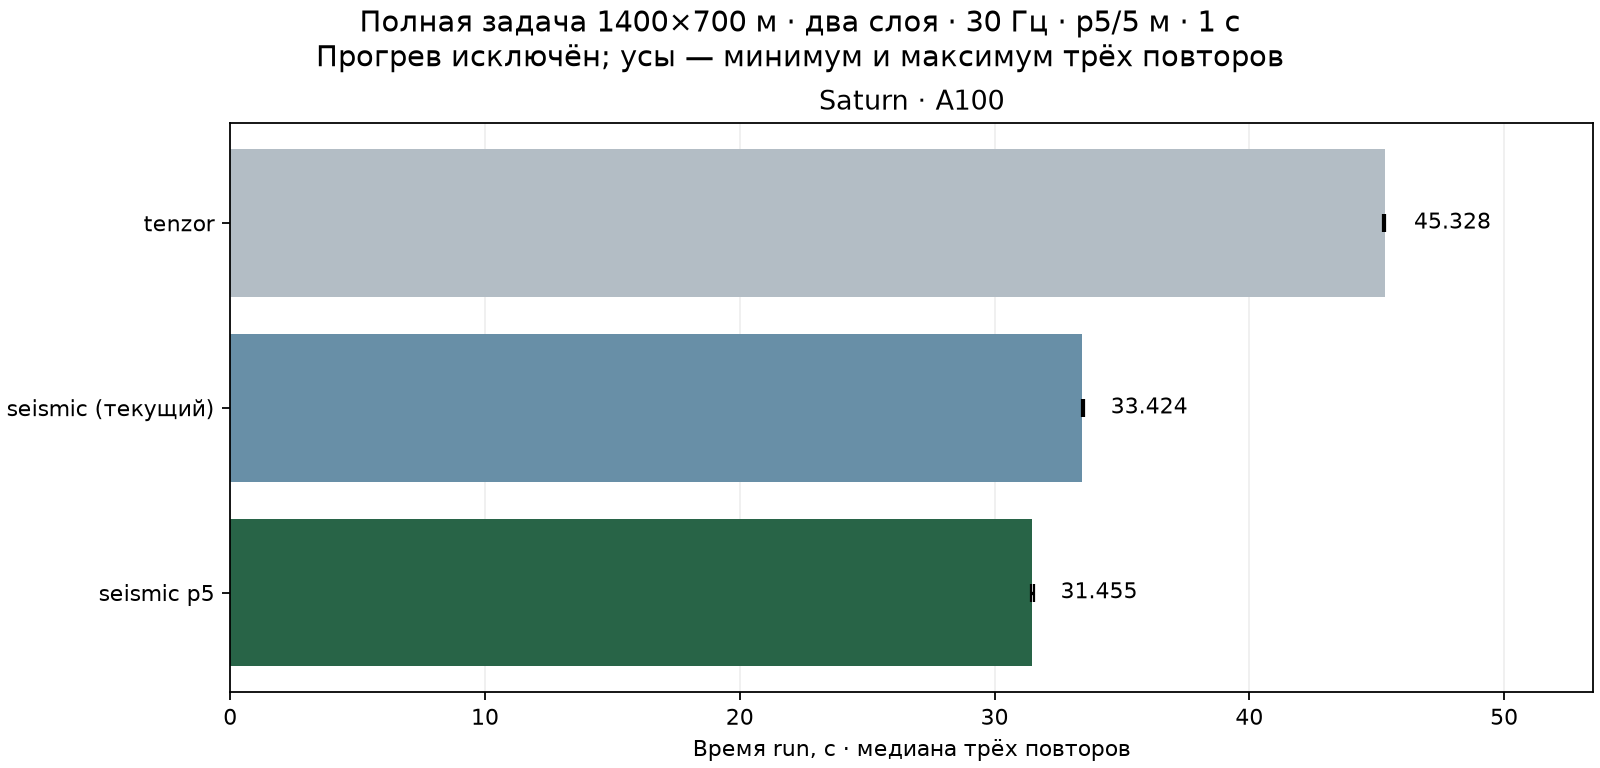

Сравнение p5: /home/antonov/Work/Areas/Seismic/SeismicDataset/img/dev_1_5_geometry_frequency/p5_comparison_v1/index.html


In [9]:
for chapter15_p5_host in ("saturn",):
    chapter15_p5_path = chapter15_root.parent / f"p5_{chapter15_p5_host}_v1/analysis.json"
    if chapter15_p5_path.exists():
        chapter15_p5_record = read_json(chapter15_p5_path)
        assert chapter15_p5_record["status"] == "completed"
        print(chapter15_p5_host, "согласование:", chapter15_p5_record["all_agree"])
        for chapter15_p5_timing in sequence(chapter15_p5_record["timings"]):
            chapter15_p5_row = mapping(chapter15_p5_timing)
            print(chapter15_p5_row["backend"], "run, с:", chapter15_p5_row["run_seconds"])
    else:
        print(chapter15_p5_host, "серия сравнения p5 ещё не завершена")

chapter15_p5_image = PROJECT_ROOT / "img/dev_1_5_geometry_frequency/p5_comparison_v1/performance.png"
if chapter15_p5_image.exists():
    display(Image(filename=str(chapter15_p5_image), width=1100))
    print("Сравнение p5:", chapter15_p5_image.with_name("index.html"))

На Saturn завершены все12 запусков:3 прогрева и9 измеряемых опытов. У всех вариантов native CFL0,8 дал одинаковый dt=1/52000 с (K52), общий шаг вручную не задавался. Медиана run для tenzor/current seismic/seismic_p5 составляет45,328337/33,423779/31,455317 с. p5 быстрее tenzor в1,441039 раза (−30,606% времени), текущего seismic — в1,062580 раза (−5,889%). Диапазоны трёх повторов:45,265277–45,340446 /33,414626–33,494886 /31,414833–31,561173 с; выигрыш специализации существенно больше наблюдаемого разброса. Медианы полного времени, включая сборку/подготовку/сохранение до SHA-хеширования:50,748070/38,441262/36,184602 с. Подготовка около0,56/0,45/0,46 с. run включает интегрирование и обработчики записи21 поля/1001 поверхности; это не чистое время ядер.

Проверены6 пар×2 набора, то есть12 сравнений полей/поверхностей по трём повторам двух новых решателей против tenzor. Максимальная компонентная относительная L2 у общего seismic3,375552e−13, у p5 —8,288864e−13; max|Δv| у p51,175341e−20 м/с. Проверены все21 кадр1533876 узлов и1001 отсчёт1751 приёмника; результат численно согласуется, не побитово равен. SHA всех36 массивных файлов12 запусков проверены на Saturn. Сырые результаты6,816 ГБ остаются на сервере, локально скопированы компактные JSON и журналы. После завершения обе A100 свободны, доступно175,51 ГиБ. Основная очередь остаётся остановленной.

Результат относится к полной задаче одного размера, одному источнику30 Гц и фиксированному p5. Текущий общий seismic отличается от исторического в §6–7, поэтому его ускорение и добавочный выигрыш p5 разделены. Из этих измерений нельзя заключить, какое ядро ускорилось или как изменится производительность при других порядках/геометриях. Локальный прогрев и два измеряемых завершённых запуска сохранены исторически; прерванный seismic_p5_0 не имеет result.json и не считается завершённым.

## 9. p4/p5 с демпфированием только в поглощающих слоях ##

По новому поручению обе серии выполнены для полной двухслойной задачи1400×700 м, одного центрального источника30 Гц и1 с, с элементами5 м. Постановка изменена в setup.build_damping: носитель массового демпфирования — объединение узлов элементов трёх слоёв, общие узлы учитываются один раз. Поле коэффициентов при продолжении нулём внутрь основной области побитово совпадает с прежним. ABC, квадратичный k=0,5, толщина175 м, свободный верх, β=1/27 и γ=0,5 сохраняются. Это исправление носителя поля сокращает объём вычислений с нулевыми коэффициентами; изменение физических коэффициентов не вводилось.

Используется одна A1000 на Saturn. Для каждого порядка сопоставлены tenzor, общий seismic и специализация соответствующего порядка. Один полный прогрев каждого решателя исключён из статистики, затем три повтора с циклическим порядком запусков. Шаг определяется native CFL0,8 с tact_dt0,001; между порядками шаг индивидуальный. Регистрация:21 полный кадр Vx/Vy и1001 отсчёт всех узлов верха. У p4:982101 узел,1401 приёмник,355461 узел демпфирования; у p5:1533876/1751/554576 соответственно. Число элементов61250 одинаково.

Сборка из отдельного снимка seismic_p45_damping_v1, среда .runtime_ch15_p45_damping_v1. Общий seismic имеет те же исходники, что и в §8; специализированное семейство получило общие фасады и компиляцию с фиксированным порядком. Native tenzor скопирован из прежней среды без изменения SHA. Первичная CPU-проверка на Saturn остановилась до GPU-запусков: встроенные таблицы ALine совпали локально побитово, но серверное построение стандартных таблиц отличается в последних битах. Измеренные max|Δ|:1,776357e−15 при p4 и1,110223e−15 при p5. Проверка теперь отдельно сохраняет побитовое равенство и требует rtol=atol=1e−14; критерии согласования полных решений из §6 не менялись. Первичный отказ и повторная проверка сохранены. Локальные GPU-расчёты не выполняются.

p 4 tenzor run, с: [20.543357481248677, 20.560991710051894, 20.654491413384676]
p 4 seismic run, с: [13.430228885263205, 13.458236958831549, 13.461195875890553]
p 4 seismic_p4 run, с: [12.402416189201176, 12.414333024993539, 12.425641719251871]
p 5 tenzor run, с: [45.29603816661984, 45.42450562398881, 45.48706078995019]
p 5 seismic run, с: [29.4120750175789, 29.400207142345607, 29.371239590458572]
p 5 seismic_p5 run, с: [27.736217574216425, 27.482110967859626, 27.5231999931857]


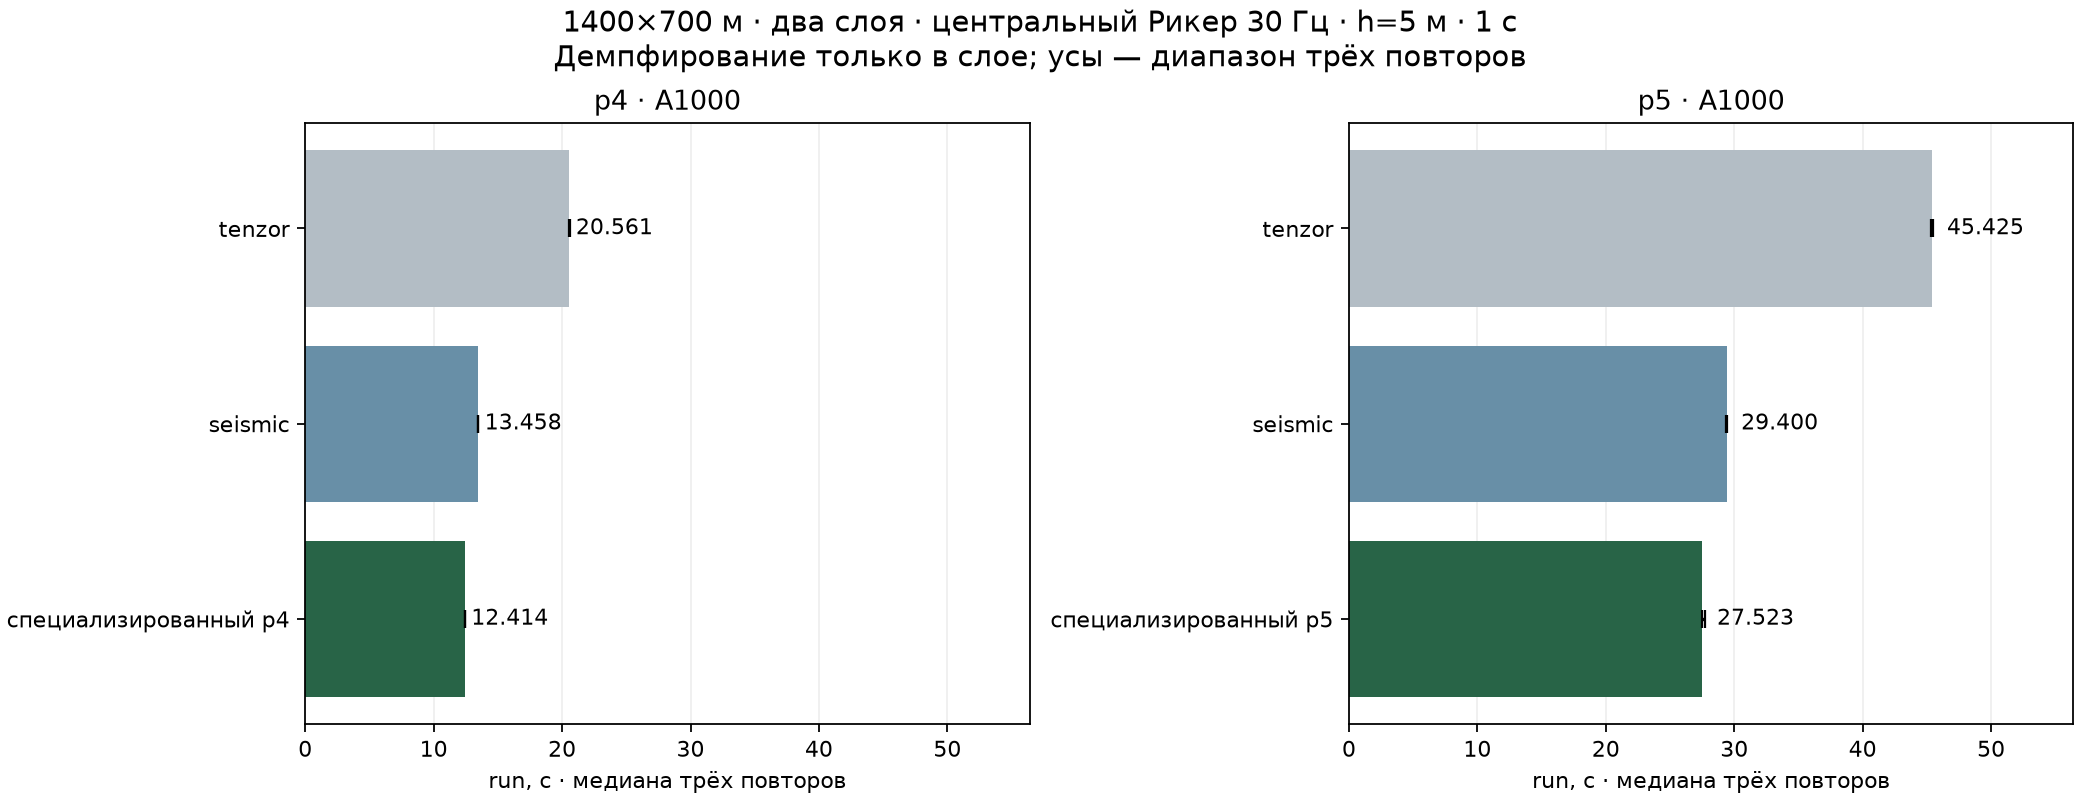

Отчёт p4/p5: /home/antonov/Work/Areas/Seismic/SeismicDataset/img/dev_1_5_geometry_frequency/p45_damping_v1/index.html


In [10]:
chapter15_orders_root = chapter15_root.parent / "p45_damping_saturn_v1"
for chapter15_order in (4, 5):
    chapter15_order_path = chapter15_orders_root / f"p{chapter15_order}/analysis.json"
    if chapter15_order_path.exists():
        chapter15_order_record = read_json(chapter15_order_path)
        assert chapter15_order_record["status"] == "completed"
        assert chapter15_order_record["all_agree"] is True
        for chapter15_order_item in sequence(chapter15_order_record["timings"]):
            chapter15_order_timing = mapping(chapter15_order_item)
            print("p", chapter15_order, chapter15_order_timing["backend"], "run, с:", chapter15_order_timing["run_seconds"])
    else:
        print("Серия p", chapter15_order, "пока не завершена")
chapter15_orders_image = PROJECT_ROOT / "img/dev_1_5_geometry_frequency/p45_damping_v1/performance.png"
if chapter15_orders_image.exists():
    display(Image(filename=str(chapter15_orders_image), width=1200))
    print("Отчёт p4/p5:", chapter15_orders_image.with_name("index.html"))

При p4 все варианты самостоятельно выбрали 35000 шагов за1 с: dt=2.85714285714e-05 с. Медианы run tenzor/seismic/специализации: 20.560992/13.458237/12.414333 с; полное время до конечного SHA-хеширования: 25.535041/18.276112/17.090417 с. Специализация быстрее tenzor в1.656230 раза, общего seismic — в1.084089 раза; сокращение времени 39.622% /7.757%. Максимальная компонентная относительная L2 разности с tenzor по полным полям и поверхности 1.747255e-12, max|Δv|=2.552348e-20 м/с.

При p5 все варианты самостоятельно выбрали 52000 шагов за1 с: dt=1.92307692308e-05 с. Медианы run tenzor/seismic/специализации: 45.424506/29.400207/27.523200 с; полное время до конечного SHA-хеширования: 50.613377/34.441819/32.247216 с. Специализация быстрее tenzor в1.650408 раза, общего seismic — в1.068197 раза; сокращение времени 39.409% /6.384%. Максимальная компонентная относительная L2 разности с tenzor по полным полям и поверхности 8.286052e-13, max|Δv|=1.162975e-20 м/с.

У p5 прежняя/новая медиана общего seismic составляет33.423779/29.400207 с (−12.038% времени), специализации —31.455317/27.523200 с (−12.501%). tenzor изменился с45.328337 до45.424506 с (+0.212%); столь малое изменение не трактуется как доказанный эффект по трём повторам. При неизменной библиотеке tenzor контроль всех полей/поверхностей до и после изменения носителя дал максимум L2=3.379254e-13. Коэффициенты демпфирования и физический отклик сохранены в пределах округления. Специализированное семейство обновлено, поэтому всё изменение его времени нельзя приписывать только носителю поля.

Всего завершены24 запуска,18 измеряемых. Проверены12 пар полей и12 пар поверхностей между решателями, дополнительно3 пары полей/поверхностей tenzor до/после изменения носителя, SHA72 массивных файлов. Все критерии согласования пройдены. Полные поля/сейсмограммы11,235 ГБ остаются на Saturn; компактные JSON и журналы перенесены локально. Обе A100 освобождены, свободно164,95 ГиБ. Локальных GPU-расчётов в новой серии нет; производственная очередь остаётся остановленной.

Сравнение скорости p4/p5 использует разные dt, количества узлов и приёмников, поэтому характеризует стоимость полного опыта с native CFL. Оно не доказывает одинаковую точность порядков и не заменяет отдельную проверку сходимости. Времена run включают интегрирование и обработчики записи; полное время дополнительно включает сборку/подготовку/сохранение до контрольного хеширования. Контроль tenzor — другая реализация на той же сетке и шаге, а не аналитический эталон.

## Выводы ##

Все30 односекундных расчётов на двух A100 завершены. В каждом опыте сохранён21 кадр Vx/Vy всех узлов и1001 отсчёт каждого верхнего GLL-узла, включая демпфирующие боковые продолжения. Число приёмников зависит от ширины:701,1051,1351 или1751. На максимальной области записано1533876 узлов в каждом кадре. На общих временах поверхность побитово совпадает с полями. Относительная норма нарушения зеркальной симметрии Vx/Vy не превосходит5,68·10⁻¹³; все30 опытов используют одну native-библиотеку. Эти согласования не заменяют независимой валидации физического решения.

Встроенный выбор шага дал K56 для EFVB00000, K53 для однородного материала и K52 для двухслойного варианта, то есть dt≈17,8571/18,8679/19,2308 мкс. Внутри каждой пары15/30 Гц совпадают сетка и dt. Время одного опыта с подготовкой и записью до этапа контрольного хеширования составляет14,01–53,94 с; сумма этих индивидуальных времён919,41 с не равна настенному времени двух параллельных работников. Сырые записи полей, координат и сейсмограмм занимают около9,63 ГБ; весь расчётный каталог с сетками и метаданными —9,64 ГБ.

Новая серия изолирована от остановленной производственной очереди и предыдущих сравнений сходимости. Полные поля остаются на Saturn внутри проекта; компактные свидетельства и все готовые артефакты просмотра перенесены локально. Созданы30 MP4 по21 кадру,30 сейсмограмм и60 статических кадров. Проверены локальные контрольные суммы видео/сейсмограмм, декодирование всех видео и PNG, а также все ссылки HTML-галереи. Артефакты занимают73,37 МБ. После завершения GPU свободны, на диске Saturn осталось около189,91 ГиБ. Общие физические шкалы позволяют сопоставлять сохранённые кадры между геометриями, материалами и частотами. Это серия визуального исследования; количественная оптимизация размера или выбор нового производственного сценария здесь не выполнялись. Полный перечень входов/выходов приведён в summary главы.

## 10. PML вместо массового поглощающего слоя ##

В отдельной серии pml_homogeneous_saturn_v1 проверяется новый PML общего seismic CUDA на однородной основной области1400×700 м. Материал верхнего слоя EFVB00000: Vp=4087 м/с, Vs=2431,62036 м/с, ρ=1000 кг/м³. Центральная точечная сила вниз1 Н/м, Рикер30 Гц с t0=0,05 с, длительность1 с. Используются p4/p5 и прямоугольные элементы5 м; β=1/27, γ=0,5. Полная область1750×875 м включает175 м слева, справа и снизу, верх свободный. Все варианты рассчитаны одним новым общим решателем из снимка seismic_pml_v1; специализированные p4/p5 здесь не используются.

Старый способ — квадратичное массовое демпфирование k=0,5 с αmax=173,0886108476381 с⁻¹ и ABC на трёх внешних гранях. Вместо него PML31100 задаётся на22050 элементах полосы, с локальными направленными профилями d_x(x) и d_y(y); массового демпфирования в PML-вариантах нет. Профили квадратично возрастают от нуля на стыке до того же173,0886108476381 с⁻¹ на внешней границе. В углах одновременно активны оба направления. Проверены PML со свободной внешней границей и PML с дополнительным ABC. Равенство максимальных коэффициентов задаёт воспроизводимый опыт, но не означает одинаковую интегральную эффективность двух механизмов; амплитуда PML не оптимизировалась.

Активный PML в текущем API не поддерживает встроенную оценку CFL. Поэтому старый контроль получает native CFL0,8/tact_dt0,001, а полученный dt явно передаётся PML и расширенной контрольной области. Для p5 дополнительно повторены старый слой и PML с dt/2. Отдельный контроль без поглощения занимает6400×3200 м, x=−2500…3900,y=−3200…0, при тех же h/p/dt. Сохраняется только общий вырез1750×875 м. Минимальное геометрическое время возврата от его внешних границ в вырез равно5525/4087≈1,352 с, больше1 с; это численный контроль на расширенной сетке, а не аналитическое точное решение.

Главная метрика отделяет отражённую волну от физического хвоста двумерного решения: это разность с расширенной областью на физическом верхе x=0…1400 м в окне0,5–1 с. Пространственные веса GLL учитывают неравномерное положение узлов; обе компоненты входят совместно. Общий множитель временного шага регистрации0,001 с опущен и сокращается в отношениях:

$$
J=\left[\sum_{t_j=0.5}^{1.0}\sum_i w_i\left((V_{x,ij}-V^{\rm ref}_{x,ij})^2+(V_{y,ij}-V^{\rm ref}_{y,ij})^2\right)\right]^{1/2}.
$$

Дополнительно рассчитана кинетическая энергия только основной области с согласованными квадратурными массами; это не полная упругая энергия. Для каждого опыта сохранены21 кадр Vx/Vy через0,05 с и1001 отсчёт всех верхних GLL-узлов через0,001 с, включая боковые полосы. Порядки выполняются на разных A100 параллельно, без локальных GPU-расчётов. Времена ниже справочные, без прогревов и статистических повторов.

Проверено PML-опытов: 10
p4 old J: 3.6419860714524128e-09 run, с: 13.674829718656838
p4 pml J: 4.356796631906619e-10 run, с: 17.243130742572248
p4 pml_abc J: 2.935696456465589e-11 run, с: 17.304886273108423


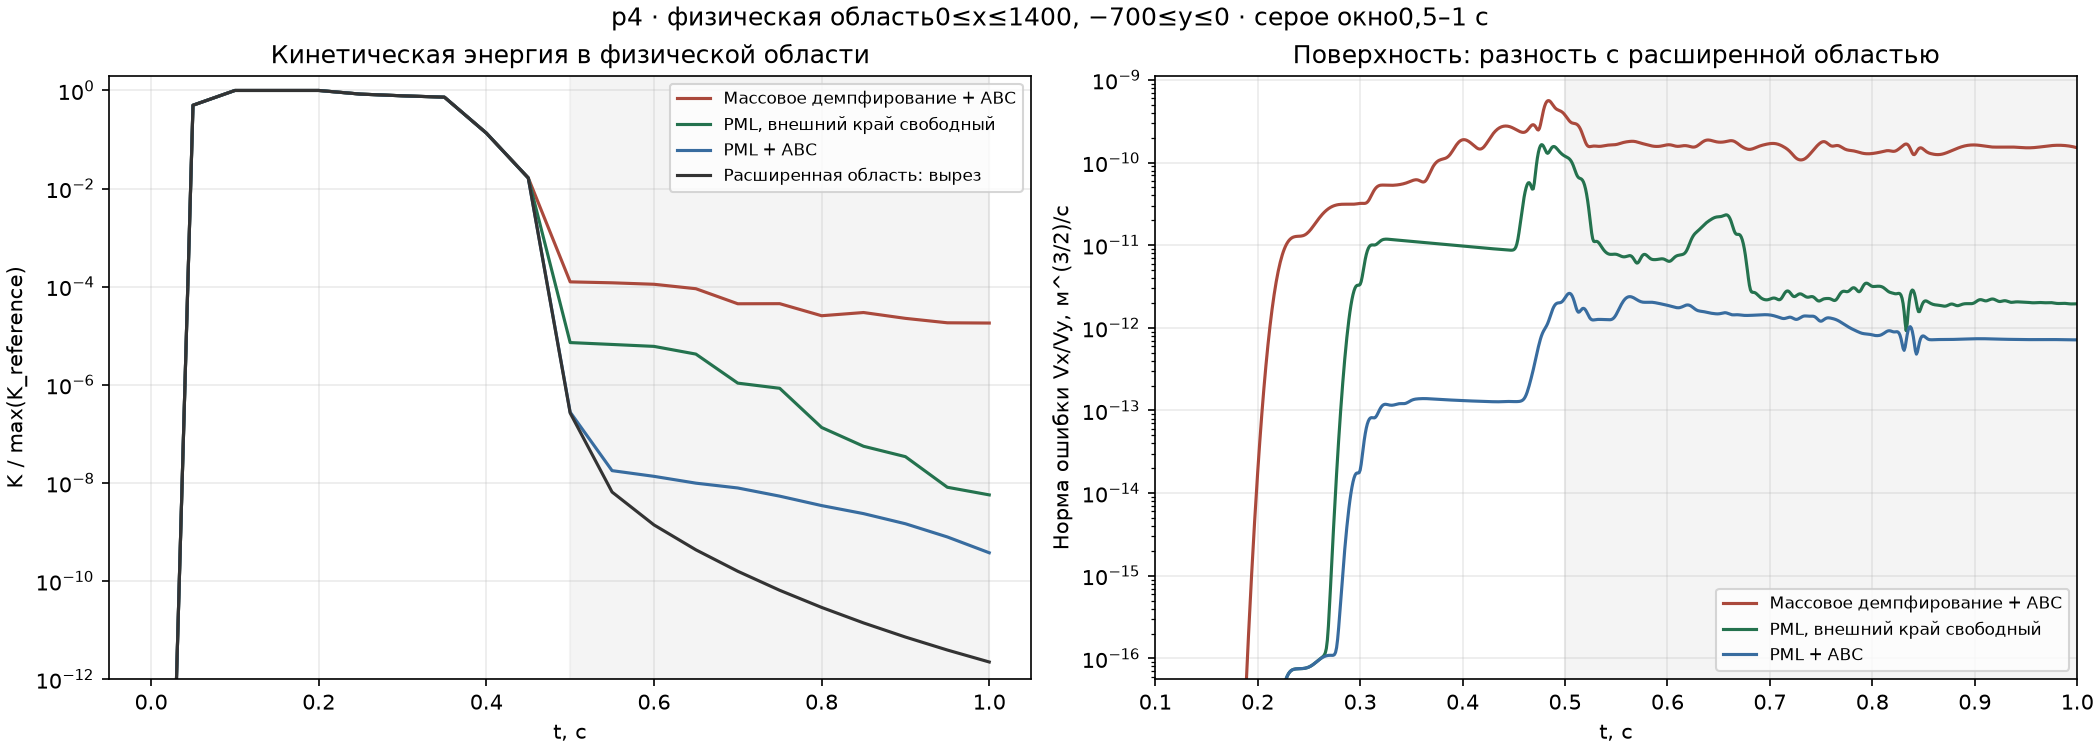

p5 old J: 3.6419281760034605e-09 run, с: 29.602391513995826
p5 pml J: 4.3569909897226627e-10 run, с: 36.74996741767973
p5 pml_abc J: 2.93557276280394e-11 run, с: 37.175556912086904


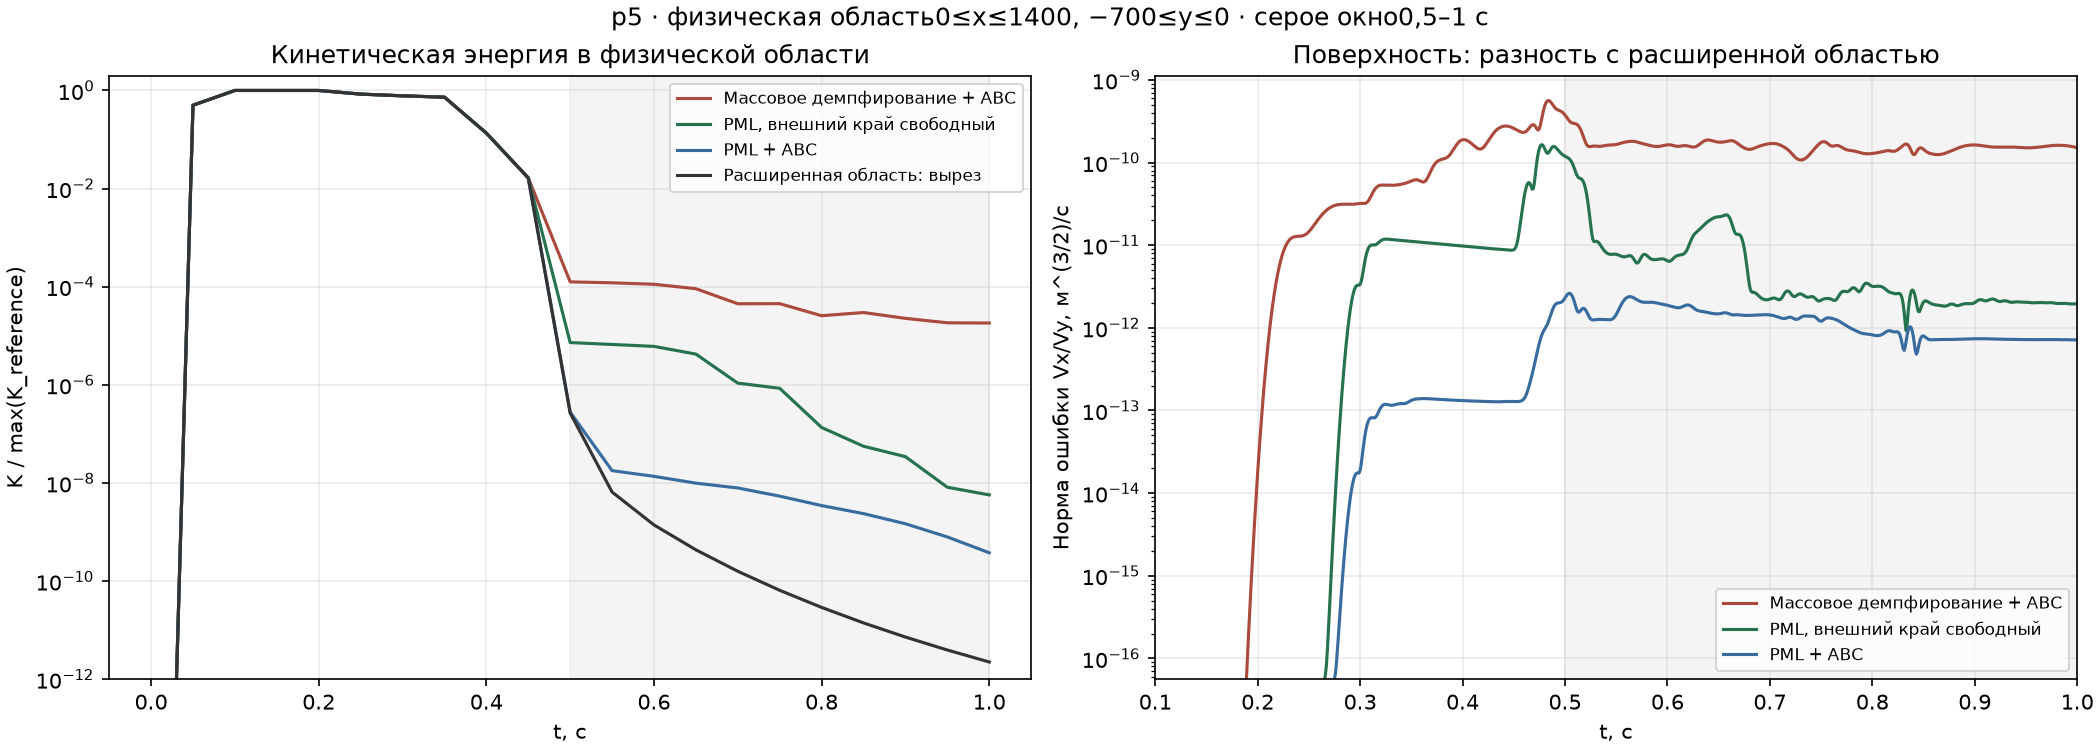

Анимации и сейсмограммы: /home/antonov/Work/Areas/Seismic/SeismicDataset/img/dev_1_5_geometry_frequency/pml_homogeneous_v1/index.html


In [11]:
chapter15_pml_root = PROJECT_ROOT / "data/dev_1_5_geometry_frequency/pml_homogeneous_saturn_v1"
chapter15_pml_metrics_path = chapter15_pml_root / "analysis/metrics.json"
if chapter15_pml_metrics_path.exists():
    chapter15_pml_metrics = read_json(chapter15_pml_metrics_path)
    assert chapter15_pml_metrics["status"] == "completed"
    print("Проверено PML-опытов:", len(sequence(chapter15_pml_metrics["verified_runs"])))
    for chapter15_pml_order, chapter15_pml_entry in mapping(chapter15_pml_metrics["orders"]).items():
        chapter15_pml_modes = mapping(mapping(chapter15_pml_entry)["modes"])
        for chapter15_pml_mode in ("old", "pml", "pml_abc"):
            chapter15_pml_row = mapping(chapter15_pml_modes[chapter15_pml_mode])
            print(chapter15_pml_order, chapter15_pml_mode, "J:", mapping(chapter15_pml_row["late_surface"])["error_weighted_l2"], "run, с:", chapter15_pml_row["run_seconds"])
        display(Image(filename=str(PROJECT_ROOT / f"img/dev_1_5_geometry_frequency/pml_homogeneous_v1/{chapter15_pml_order}_decay.png"), width=1300))
    print("Анимации и сейсмограммы:", PROJECT_ROOT / "img/dev_1_5_geometry_frequency/pml_homogeneous_v1/index.html")
else:
    print("Итоговый анализ PML пока не сохранён локально.")

Все10 опытов завершены на Saturn:4 при p4 и6 при p5. Общие шаги dt=1/36000 и1/53000 с соответственно; p5 при dt/2 использует106000 шагов. Ранняя поверхность0–0,1 с согласуется с расширенным контролем до7,98e−14 по норме, отнесённой к полной контрольной записи. Проверены SHA40 файлов полей/координат/масс/сейсмограмм, конечность всех сохранённых полей и памяти PML; поле и поверхность в совпадающие моменты побитово равны. Это подтверждает воспроизводимость данного опыта, но не является независимой полной валидацией реализации PML.

Для p4 нормы J старого слоя/PML/PML+ABC равны3,641986e−9/4,356797e−10/2,935696e−11; для p5 —3,641928e−9/4,356991e−10/2,935573e−11. Относительно старого k0,5+ABC новый PML уменьшает J в8,3593/8,3588 раза при p4/p5, а PML+ABC — в124,0587/124,0619 раза. Само добавление ABC снаружи PML улучшает результат ещё в14,8408/14,8420 раза. Близость двух порядков поддерживает устойчивость этого вывода для h5 м, но не заменяет отдельного исследования сходимости поля.

Пиковая поздняя ошибка Vy на физическом верхе при p5 уменьшается с2,05404e−11 м/с у старого слоя до6,59974e−12 у PML и1,97411e−13 у PML+ABC. Для Vx соответствующие пики1,44590e−11/3,32045e−12/1,97951e−13 м/с. Это максимумы разности с контрольной областью в окне0,5–1 с, а не отношение максимумов исходной и отражённой волны в одной точке. Разность p5 между dt и dt/2 составляет0,00342% нормы ошибки старого слоя и0,00589% нормы ошибки PML. Отдельные PML+ABC и расширенный контроль на dt/2 не считались; проверка не даёт строгой оценки их временной ошибки.

Кинетическая энергия основной области при t=1 с для p5: старый слой1,188303e−15 Дж/м, PML3,733794e−19 Дж/м, PML+ABC2,467441e−20 Дж/м, расширенный контроль1,465437e−22 Дж/м. Относительно старого слоя это уменьшение в3182,56 и48159,33 раза соответственно. Энергия и амплитудная норма — разные показатели, их коэффициенты гашения нельзя смешивать. В PML+ABC остаток ещё примерно в168 раз больше физического контрольного хвоста по кинетической энергии, поэтому полного исчезновения волны не заявляем. Конечная максимальная ошибка поля в основной области около9,20e−14 м/с.

Справочные времена run старый/PML/PML+ABC при p4:13,675/17,243/17,305 с; при p5:29,602/36,750/37,176 с. PML+ABC в этих одиночных опытах дороже на26,5%/25,6%; расширенные контроли159,452/356,735 с не относятся к стоимости рабочего варианта. run включает запись полей и поверхности; прогревов/статистических повторов здесь нет.

При данном квадратичном профиле175 м PML с ABC существенно эффективнее прежнего массового слоя и предпочтительнее PML со свободным внешним краем. Сильная реакция на внешнее ABC указывает на существенный вклад возврата от внешней границы конечного PML; это не доказывает нулевое отражение на его внутреннем стыке. Коэффициент173,088611 с⁻¹ не подбирался специально для PML. Вывод ограничен однородной прямоугольной задачей30 Гц и интервалом1 с; неоднородные среды, другие частоты, длительная устойчивость и производственный датасет этим опытом не проверены. Основная очередь остаётся остановленной.

## 11. Толщина PML при постоянном интеграле профиля ##

Продолжение предыдущего опыта сравнивает PML+ABC толщиной175,100,50,25,15 и10 м, то есть35,20,10,5,3 и2 ряда элементов. Основная однородная область1400×700 м остаётся неизменной; уменьшается только внешняя полоса. Источник, материал, h5 м, p4/p5, β1/27, длительность1 с и частота регистрации совпадают с §10. Для p4 используется прежний dt=1/36000 с, для p5 —1/53000 с; у p5/10 м выполнен дополнительный контроль dt/2. Native-библиотека совпадает по SHA со старым опытом. Существующие175 м, массовый слой и расширенные контроли используются повторно, без новых GPU-прогонов.

С уменьшением толщины сила поглощения увеличивается так, чтобы интеграл квадратичного профиля оставался прежним:

$$
d_L(s)=173.0886108476381\frac{175}{L}\left(\frac{s}{L}\right)^2,\qquad \int_0^L d_L(s)\,ds=\frac{173.0886108476381\cdot175}{3}.
$$

Это совместное изменение толщины и максимума, а не обрезание слоя при неизменном коэффициенте. Максимумы для100/50/25/15/10 м составляют302,905/605,810/1211,620/2019,367/3029,051 с⁻¹. На всех трёх внешних гранях остаётся ABC, верх свободный. Оптимизация силы отдельно для каждой толщины не выполнялась.

Нормы сравниваются только в общей физической области; координаты её GLL-узлов и массы сопоставлены с расширенным контролем. Основная поверхностная метрика — GLL-норма разности Vx/Vy за весь интервал0–1 с, поскольку тонкий слой возвращает отражение раньше. Дополнительно сохранены окна0,2–1 и0,5–1 с и раннее согласование0–0,1 с. Анимации показывают всю расчётную область вместе с PML; внешние границы разных вариантов различаются. Общая физическая область отмечена пунктиром. Сейсмограммы отчёта ограничены верхом0…1400 м, исходная запись включает весь верх каждой сетки.

Первоначальная серия pml_thickness_saturn_v1 содержит11 новых опытов, по одному порядку на A100. После обнаружения сильного роста внутри тонких PML добавлены ещё5 контролей p5 с неизменным максимумом173,0886108476381 с⁻¹ для100/50/25/15/10 м; всего16 новых запусков. Метки L означают постоянный интеграл, F — постоянный максимум. Рост контролируется по всему полю, включая PML, а не только по физической области и поверхности. Признак сильного роста: поздний максимум полного поля за0,5–1 с превышает в10 раз максимум контрольного поля за весь опыт; отсутствие этого признака не доказывает длительную устойчивость. Расчётные времена включают регистрацию: при уменьшении области снижается также объём вывода. Это одиночные прогоны; значения старого слоя и175 м взяты из прошлого опыта. Сравнение не является статистическим измерением производительности ядер. Первичные скрипты pml_setup/run/analyze/render.py расширены в ранее разрешённом PML-scope и переданы коммитамиa27ff92/3d874d1/1240516/d13928e.

p4 L175 J0–1/J175: 1.0 run, с: 17.304886273108423
p4 L100 J0–1/J175: 2.0896236336426415 run, с: 13.589006500318646
p4 L50 J0–1/J175: 4.46939316247947 run, с: 11.191039390861988
p4 L25 J0–1/J175: 6.599097461366485 run, с: 9.817867094650865
p4 L15 J0–1/J175: 38619219898856.59 run, с: 9.400420371443033
p4 L10 J0–1/J175: 3454687148051.4434 run, с: 9.225218519568443
p5 L175 J0–1/J175: 1.0 run, с: 37.175556912086904
p5 L100 J0–1/J175: 2.0898561261045656 run, с: 28.725121839903295
p5 L50 J0–1/J175: 4.469148995152596 run, с: 23.630275283940136
p5 L25 J0–1/J175: 1377805.0855117547 run, с: 20.997056037187576
p5 L15 J0–1/J175: 14403301160053.535 run, с: 20.50012743100524
p5 L10 J0–1/J175: 2.8712027625968087e+21 run, с: 20.178411240689456
p5 F100 J0–1/J175: 29.512324970994484 run, с: 29.539097082801163
p5 F50 J0–1/J175: 381.74972086793895 run, с: 24.07266162056476
p5 F25 J0–1/J175: 1402.1248388565086 run, с: 22.884508120827377
p5 F15 J0–1/J175: 2370.061664860011 run, с: 21.261271678842604
p5 F10 J

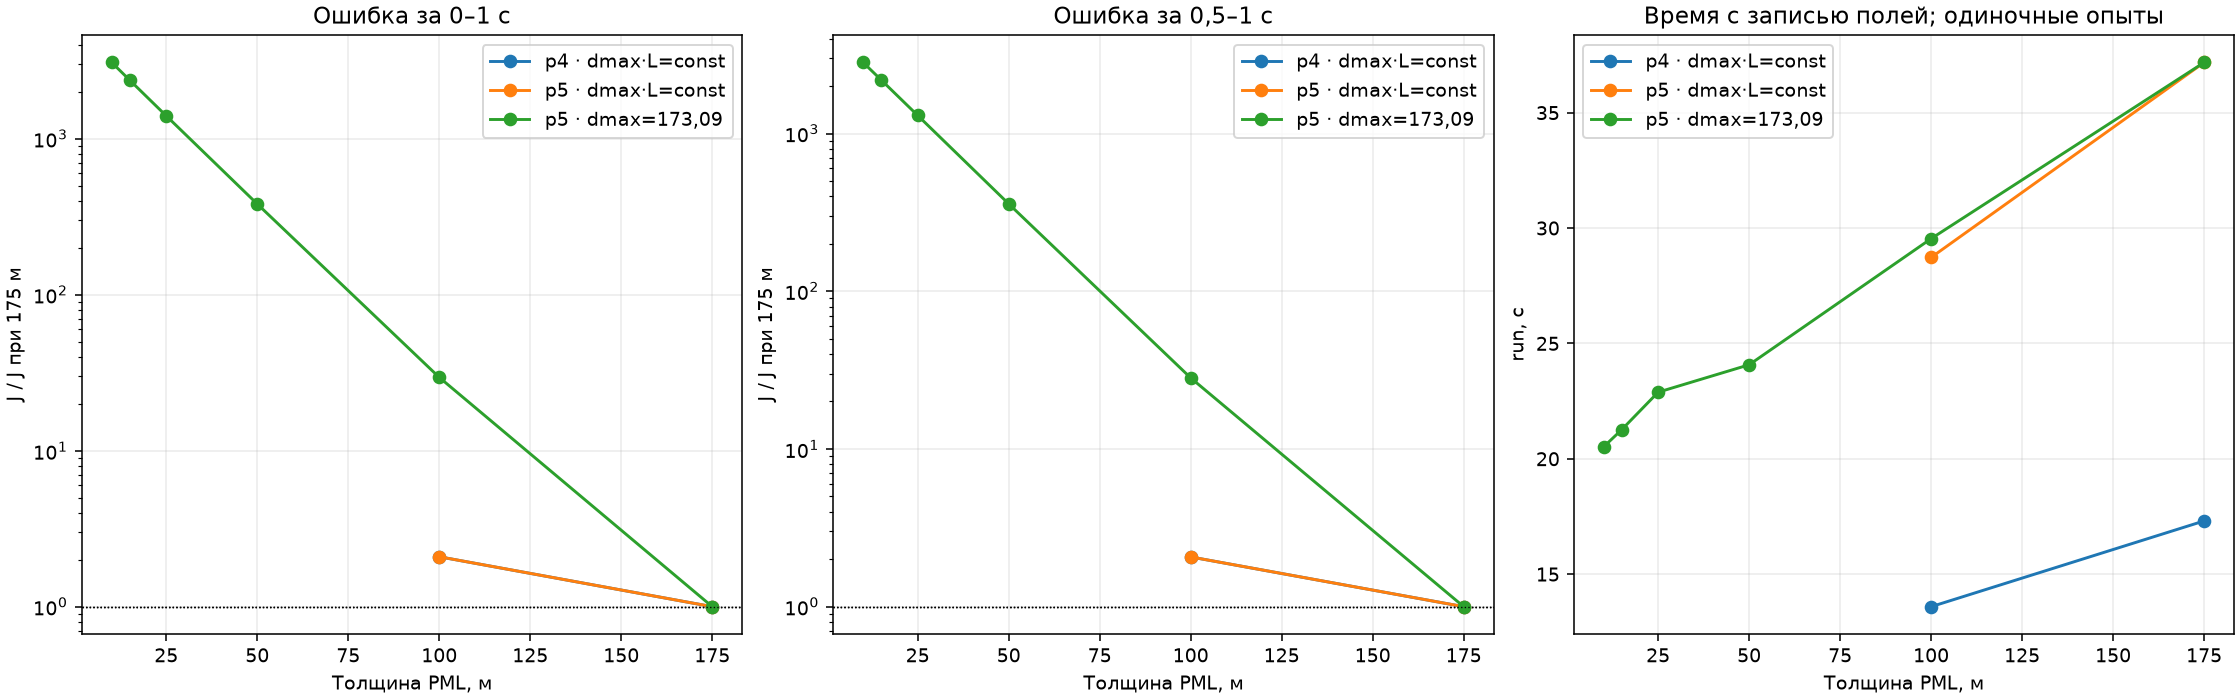

Толщины PML: /home/antonov/Work/Areas/Seismic/SeismicDataset/img/dev_1_5_geometry_frequency/pml_thickness_v1/reviewed.html


In [12]:
chapter15_thickness_root = PROJECT_ROOT / "data/dev_1_5_geometry_frequency/pml_thickness_saturn_v1"
chapter15_thickness_path = chapter15_thickness_root / "analysis/metrics.json"
if chapter15_thickness_path.exists():
    chapter15_thickness_record = read_json(chapter15_thickness_path)
    assert chapter15_thickness_record["status"] == "completed"
    for chapter15_thickness_order, chapter15_thickness_data in mapping(chapter15_thickness_record["orders"]).items():
        for chapter15_thickness_label, chapter15_thickness_value in mapping(mapping(chapter15_thickness_data)["cases"]).items():
            if chapter15_thickness_label.startswith(("L", "F")):
                chapter15_thickness_row = mapping(chapter15_thickness_value)
                print(chapter15_thickness_order, chapter15_thickness_label, "J0–1/J175:", chapter15_thickness_row["full_error_ratio_to_L175"], "run, с:", chapter15_thickness_row["run_seconds"])
    display(Image(filename=str(PROJECT_ROOT / "img/dev_1_5_geometry_frequency/pml_thickness_v1/tradeoff.png"), width=1300))
    print("Толщины PML:", PROJECT_ROOT / "img/dev_1_5_geometry_frequency/pml_thickness_v1/reviewed.html")
else:
    print("Итоговые метрики толщин PML пока не сохранены локально.")

Все16 новых запусков завершились с конечными числами; анализ включает6 повторно использованных опытов и проверяет88 SHA массивов. Конечность чисел сама по себе не подтверждает устойчивость. При сохранении интеграла профиля100 м не показывает сильного роста за1 с, но50/25/15/10 м показывают рост полного поля при обоих порядках. При p5 поздние максимумы во всей области:50 м —1,201924e−5 м/с,25 м —793,535 м/с,15 м —8,828939e9 м/с,10 м —3,062163e13 м/с. У исходного175 м поздний пик4,315873e−10 м/с. Это численный рост, а не физическая отражённая волна данной нагрузки1 Н/м.

Рост может долго оставаться внутри PML. Например, при50 м поверхностная норма разности за0–1 с превышает175 м лишь в4,469 раза и почти совпадает у p4/p5, хотя полные поля уже имеют сильный рост. У p4/25 м поверхностное отношение6,599 также не обнаруживает масштаб проблемы в PML: полный поздний пик0,695 м/с. Поэтому оценивать пригодность только по сейсмограммам основной области недостаточно. На графике качества/времени эти случаи исключены; таблицы, графики полного пика и анимации их сохраняют и маркируют. Причина неустойчивости внутри реализации этим опытом не установлена.

Для100 м с пересчитанным максимумом302,905 с⁻¹ получено J0–1/J175=2,089624 при p4 и2,089856 при p5; поздние отношения J0,5–1/J175=2,067325/2,067492. Относительно старого массового слоя k0,5+ABC ошибка меньше в75,439/75,434 раза за0–1 с и60,009/60,006 раза за0,5–1 с. Время p4 уменьшилось17,305→13,589 с (−21,47%), p5 —37,176→28,725 с (−22,73%). Ранняя поверхность всех основных опытов согласуется с расширенным контролем до8,09e−14 относительно полной контрольной записи. Выигрыш по времени относится к полному запуску с регистрацией и одиночным измерениям.

Двукратное уменьшение dt у p5/10 м не устранило рост: максимум3,114229e13 м/с вместо3,062163e13 м/с. Относительная разность поверхностных ошибок coarse/fine2,456% здесь сравнивает два разошедшихся решения и не является подтверждением точности или временной сходимости. Одного такого контроля недостаточно для строгого установления причины роста, но простое уменьшение шага вдвое не решает проблему.

Контроль p5 при фиксированном dmax173,088611 с⁻¹ не показывает сильного роста за1 с ни при одной из пяти толщин. Однако ошибка за0–1 с относительно175 м возрастает в29,512/381,750/1402,125/2370,062/3086,830 раза для100/50/25/15/10 м. При100 м это всё ещё в5,342 раза меньше старого массового слоя, а при50/25/15/10 м уже хуже старого примерно в2,42/8,89/15,03/19,58 раза. Это второй край компромисса: прежняя сила сохраняет спокойное поведение за проверенное время, но тонкая полоса поглощает недостаточно. Отсутствие сильного роста за1 с не доказывает длительной устойчивости.

Поздний максимум полного поля100 м с усиленным профилем монотонно увеличивается и при p4, и при p5. У p5 с0,6 до1 с он возрастает6,443640e−13→6,252082e−11 м/с, примерно в97 раз. Грубый порог сильного роста ещё не превышен, но слабый рост уже заметен; первоначальная оценка только нормы поверхности не отражает этого ограничения. Поэтому100 м нельзя считать подтверждённой устойчивой заменой175 м.

Из проверенных уменьшенных вариантов100 м с пересчитанным коэффициентом представляет интерес для дальнейшего исследования: около23% экономии времени p5 при примерно двукратном росте ошибки относительно175 м. Минимальная допустимая толщина и оптимальная сила не установлены; диапазон50–100 м и промежуточные амплитуды не исследованы. Литературные примеры2–3 спектральных рядов нельзя автоматически переносить на текущую реализацию, источник и профиль. Производственные параметры не менялись, очередь остаётся остановленной. Все данные новой серии5,950 ГБ остаются внутри проекта на Saturn; обе GPU освобождены.

## 12. Толщина PML относительно отражений двухслойной модели

**Исправление постановки:** критерий сохранения слабых поздних кратных отражений ниже был добавлен агентом без поручения пользователя. Пользователь имел в виду первое яркое отражение. Рекомендации толщины по поздним окнам не применяются к его задаче; исправленное сравнение со старым слоем и ABC без слоя находится в §13. Численные результаты §12 сохранены как история эксперимента.

По новому поручению проверяется только p5/h5 м и текущий общий seismic с кэшированием коэффициентов рекуррентного PML. Снимок seismic_pml_cached_v1 включает незакоммиченные изменения исходного TrySEMGPU; исходный проект не изменялся. Коэффициенты exp(−d·dt) и вес рекурсии вычисляются при prepare, затем читаются CUDA-ядром. Это оптимизация вычисления прежнего PML, а не заявленное исправление обнаруженного численного роста. Активный PML по-прежнему требует явный шаг. Код передан через Git после ответа пользователя «Запускай», новая среда .runtime_ch15_pml_cached_v1 собрана отдельно на Saturn.

Основная двухслойная область1400×700 м, источник(700,0) — сила вниз1 Н/м, Рикер30 Гц, t0=0,05 с; β=1/27, γ=0,5, длительность1 с. Интерфейс y=−350 м, материалы верхнего/второго слоя EFVB00000: Vp4087/3963 и Vs2431,62036/2357,84473 м/с, плотность1000 кг/м³. Массовое демпфирование отсутствует в PML-опытах; внешний ABC использует свойства материала соответствующего участка боковой/нижней границы. Верх свободный, в том числе над боковыми PML. Записываются1001 отсчёт Vx/Vy всех GLL-узлов верха и21 полный кадр через0,05 с. Общий явный dt=1/53000 с; новая native-проверка CFL0,8 старого двухслойного контроля дала K52, поэтому K53 немного консервативнее. Это не оценка устойчивости активного PML.

Первоначально подготовлены PML10/25/50/75/100/125/150/175/250/350 м с квадратичным профилем dmax=173,0886108476381·175/L, то есть одинаковым интегралом; эти варианты обозначаются L. Старый контроль сохраняет массовый слой175 м/k0,5+ABC. Когда выяснилось, что сохранение интеграла оставляет заметную ошибку относительно слабых кратных волн, добавлены варианты F с постоянным максимумом173,0886108476381 с⁻¹:250/350/500/700 м, затем550/600/1000/1200 м для уточнения границы. Дополнительный L700 отделяет эффект увеличенной области от увеличения интегрального поглощения. Итого завершено22 опыта; исходный plan.json сохраняется, дополнения описаны extra_plan.json и case_plan_F*.json. Число рядов PML равно L/5.

Два больших контроля6400×3200 м: двухслойный и однородный верхним материалом. Интерфейс большого двухслойного контроля остаётся y=−350 м, а не половиной увеличенной высоты. Материалы продолжаются плоскопараллельно. В общей основной области возврат внешней границы по геометрической оценке приходит не раньше5700/4087≈1,395 с. Разность двухслойного и однородного контроля выделяет весь вклад интерфейса, включая конверсию и кратные волны; это не разложение по чистым фазам. Разность кандидата и большого двухслойного контроля содержит совокупную ошибку поглощающего оформления, включая вход PML, его внешний край и возможный численный рост. Называть всю эту разность исключительно отражением внешнего края нельзя.

Первый критерий «на порядки» означает минимум100× по общей взвешенной GLL-норме и максимальной амплитуде Vx/Vy за0–1 с на физической поверхности x0…1400. Он дополнен компонентами, пространственными полосами и временными окнами0,15–0,25/0,25–0,40/0,40–0,60/0,60–1 с. Но максимум первых отражений оказывается слишком сильным нормировщиком: он может скрыть ошибку, превышающую поздние кратные волны. Поэтому после получения контролей добавлено сравнение пяти отдельных окон около геометрических PP-приходов в центральной полосе |x−700|≤200 м. Центры окон учитывают смещение приёмника, полуширина20 мс; окна могут содержать другие фазы и не являются чистым модовым разложением.

$$
t_n(x)=0{,}05+\frac{\sqrt{(700n)^2+(x-700)^2}}{4087},\qquad n=1,\ldots,5.
$$

Для каждого окна сохраняются три отношения: пик ошибки Vy в том же окне/полосе; максимальная ошибка Vy центральной полосы за всю секунду; консервативный глобальный максимум ошибки обеих компонент по всей физической поверхности за всю секунду. Знаменатель каждого отношения — пик физического вклада Vy соответствующего окна. Самый строгий итоговый критерий требует, чтобы третье отношение было≤0,01 для каждого из пяти окон. Это достаточное, но не необходимое условие различимости волн; его нельзя подменять сравнением только с главным отражением. Глобальная норма и все более локальные отношения сохраняются отдельно.

Контролируется поле внутри PML: сильный рост определяется превышением поздним пиком полного поля десятикратного максимума контрольного поля за весь опыт. Дополнительный флаг отмечает монотонное увеличение PML-пика с0,6 до1 с более чем вдвое. Такие варианты не принимаются автоматически даже при хороших сейсмограммах. Это эмпирические диагностические признаки, а не доказательство устойчивости/неустойчивости на произвольных временах; в слоистой модели поздние физические приходы также требуют учитывать контекст кривой.

Данные серии — data/dev_1_5_geometry_frequency/pml_layered_cached_saturn_v1, отчёт — img/dev_1_5_geometry_frequency/pml_layered_cached_v1/reviewed.html. CPU/mypy пройдены; новый native SHA7de2a009645e541daaa373b3dcb1c3e4617d2f98dbe06847c9bf7389f6ac2ae0 зафиксирован в каждом результате. Производственная очередь остаётся остановленной.

In [13]:
layered_pml_metrics_path = PROJECT_ROOT / "data/dev_1_5_geometry_frequency/pml_layered_cached_saturn_v1/analysis/metrics.json"
if layered_pml_metrics_path.exists():
    layered_pml_metrics = read_json(layered_pml_metrics_path)
    print("Двухслойный PML:", layered_pml_metrics["status"])
    layered_pml_cases = mapping(layered_pml_metrics["cases"])
    for layered_pml_label in ("L175", "F350", "F500", "F550", "F700", "F1200"):
        layered_pml_row = mapping(layered_pml_cases[layered_pml_label])
        layered_pml_windows = mapping(layered_pml_row["central_pp_window_ratios"])
        print(layered_pml_label, "run, с:", number(layered_pml_row["run_seconds"]),
              "ошибка / окно4:", mapping(layered_pml_windows["4"])["full_surface_both_peak_ratio"],
              "ошибка / окно5:", mapping(layered_pml_windows["5"])["full_surface_both_peak_ratio"])
    print("Отчёт:", PROJECT_ROOT / "img/dev_1_5_geometry_frequency/pml_layered_cached_v1/reviewed.html")
else:
    print("Итоговый анализ двухслойного PML пока не сохранён локально.")

Двухслойный PML: completed
L175 run, с: 37.81492576561868 ошибка / окно4: 286.16977259835585 ошибка / окно5: 1948.4619619931725
F350 run, с: 60.85023953951895 ошибка / окно4: 1.189869876543348 ошибка / окно5: 8.101541169479708
F500 run, с: 84.12115905527025 ошибка / окно4: 0.012550432454321315 ошибка / окно5: 0.08545291147200008
F550 run, с: 92.20625625923276 ошибка / окно4: 0.00533858126876754 ошибка / окно5: 0.036349130932854384
F700 run, с: 119.638915929012 ошибка / окно4: 0.003883094746594095 ошибка / окно5: 0.02643906915764024
F1200 run, с: 231.8057155366987 ошибка / окно4: 0.002650717287775308 ошибка / окно5: 0.01804810396406476
Отчёт: /home/antonov/Work/Areas/Seismic/SeismicDataset/img/dev_1_5_geometry_frequency/pml_layered_cached_v1/reviewed.html


Все22 опыта завершены на двух A100; проверены88 SHA массивов, общий native и шаг, совпадение координат и ранних прямых волн, конечность полей. Поверхность во всех запусках точно совпадает с сохранёнными полями на общих временах. Большие двухслойный/однородный контроли заняли355,549/355,209 с. Публикация кода выполнялась только в разрешённых файлах и новом снимке; производство не возобновлялось.

При сохранении интеграла профиля критерий относительно всех физических отражений в совокупности уже проходит L150: L2 ошибки/вклад интерфейса0,0085297, отношение пиков0,0050156. У L175 эти отношения0,0072039/0,0041585. Однако это скрывает слабые кратные волны: максимальная ошибка L175 равна1,892693e−13 м/с, тогда как пик четвёртого окна6,613881e−16, пятого9,713778e−17 м/с. Утолщение до L700 при сохранении интеграла оставляет ошибку9,137324e−14 м/с, в941 раз больше пика пятого окна. Хорошей общей нормы недостаточно для поставленной задачи о слабых отражениях.

Варианты L10/L25/L50 имеют сильный численный рост полного поля; L75 имеет диагностический монотонный поздний рост PML. Отсутствие флага у других вариантов не доказывает длительной устойчивости. В слоистой модели поздние физические приходы могут нарушать монотонность кривой, поэтому данный флаг является диагностикой, а не математическим критерием. Причина роста в этой реализации не установлена; кэширование коэффициентов само по себе его не устранило.

С фиксированным максимумом173,088611 с⁻¹, квадратичным профилем и ABC наименьшая проверенная толщина, дающая≥100× относительно каждого из первых четырёх окон при глобальном критерии, —550 м,110 рядов по5 м. У F500 максимум ошибки8,300706e−18 м/с и запас к четвёртому окну79,68×; у F5503,530874e−18 м/с и187,32×. Поэтому порог заключён между500 и550 м; точный минимум не найден. Для пятого окна F550 даёт лишь27,51×. Эти отношения сравнивают глобальный максимум обеих компонент на всей поверхности за1 с с пиком Vy соответствующего центрального окна, а не одинаковые точки/моменты.

Условие100× для всех пяти окон не достигнуто ни в одном опыте. Даже F1200 имеет максимум ошибки1,753153e−18 м/с и запас55,41× относительно пятого окна. После500–700 м уменьшение ошибки заметно замедляется, тогда как стоимость продолжает расти: L17537,815 с, F50084,121 с, F55092,206 с, F700119,639 с, F1200231,806 с. Это одиночные полные запуски с записью полей разного размера; статистическим бенчмарком ядер они не являются. Утверждать, что1200 м гарантированно решают строгую задачу, нельзя; более широкий слой автоматически не назначен.

Дополнительная проверка сохранённых трасс показывает высокочастотный характер остатка толстого PML. Для окна0,5–1 с, Hann/rFFT, пространственных весов GLL и суммы компонент доля спектральной мощности выше100 Гц равна≈55,0% у F550 и93,15% у F1200; максимум обоих спектров около447,11 Гц в дискретной записи с шагом1 мс. У физического вклада максимум≈41,92 Гц, доля выше100 Гц≈1,00e−7; у ошибки L175 максимум≈13,97 Гц. Поэтому остаточную разность толстого PML нельзя без дополнительной проверки отождествлять с отражением исходного30-Гц импульса от внешней границы. Спектр не устанавливает причину численного остатка и не исключает алиасинг; отдельные проверки dt/профиля не выполнялись. Свидетельство — analysis/tail_spectrum.json; метод воспроизводится pml_analyze.py --layered-spectrum.

Вывод ограничен данной двухслойной геометрией, p5/h5 м, центральным30-Гц источником и1 с. Если нужны первые четыре выбранных окна с консервативным запасом100×, F550 проходит проведённую проверку. Если требование включает и пятое самое слабое окно, подходящая толщина в исследованном диапазоне не найдена; требуется исследовать источник остаточной ошибки, а не объявлять задачу решённой одним утолщением. Данные19,835 ГБ остаются на Saturn; обе GPU освобождены, доступно≈135,83 ГиБ диска. Производственные параметры не менялись.

Локальные выходы: data/dev_1_5_geometry_frequency/pml_layered_cached_saturn_v1/{analysis/metrics.json,analysis/tail_spectrum.json,completion_server.json,artifact_validation.json,runtime_logs/}, планы и метаданные всех22 запусков; img/dev_1_5_geometry_frequency/pml_layered_cached_v1/{reviewed.html,index.html,tradeoff.png,decay.png,seismograms.png,traces.png,echo_windows.png,selected_echo_windows.png,render.json,reviewed.json}. Проверены8 SHA файлов визуализации,6 PNG и13 ссылок двух HTML-страниц. Первоначальный index.html сохранён, reviewed.html добавляет итоговый вывод и отдельный график F550. Полные поля и curves.npz локально не копировались.

## 13. Первое отражение горизонта, старый слой и ABC без слоя

По уточнению пользователя сравниваем с первым ярким отражением горизонта, а не со слабыми поздними кратными приходами. Прежний более строгий критерий был самовольно добавлен агентом; рекомендации550/350 м на его основе не отвечали задаче. Исторические массивы и метрики не изменены. Новый контроль abc_only рассчитан на Saturn: основная область1400×700 м без добавленной полосы, свободный верх, ABC на боках и дне, нулевые массовое демпфирование и PML. Все остальные условия прежние: p5/h5 м, центральный Рикер30 Гц,1 с, β1/27, dt1/53000. Старый массовый слой175 м/k0,5+ABC и22 прежних опыта используются повторно.

Из расширенных двухслойного и однородного контролей берётся их разность в окне±0,03 с около первого PP-прихода t(x)=0,05+sqrt(700²+(x−700)²)/4087. Центральный приход0,221275 с, максимальная векторная скорость2,434743e−11 м/с. Все1399 GLL-приёмников строго внутри0<x<1400 м; PML и конечные точки исключены. Ошибка кандидата относительно расширенного двухслойного контроля учитывается за всю секунду. Энергетическая мера0,001·ΣwGLL(Vx²+Vy²) является энергией сигнала, не механическим потоком. Пиковая мера — максимум sqrt(Vx²+Vy²). В числителе все искусственные возвраты/численные ошибки; в знаменателе только первый PP-импульс. Это не выделение исключительно отражения внешнего края.

abc_only Eош/Eперв: 6786.403919850609 Aош/Aперв: 149.2251824048165
old Eош/Eперв: 5.474953146307872 Aош/Aперв: 0.9953439635345273
L100 Eош/Eперв: 0.000783913735151215 Aош/Aперв: 0.012935253412566692
L125 Eош/Eперв: 0.0004332762101013099 Aош/Aперв: 0.010315277345712052
L150 Eош/Eперв: 0.00027644401015211806 Aош/Aперв: 0.00974743048963348
L175 Eош/Eперв: 0.00019719092077510864 Aош/Aперв: 0.007998859659879466
F250 Eош/Eперв: 1.0381815367858137e-06 Aош/Aперв: 0.0006484855541995312


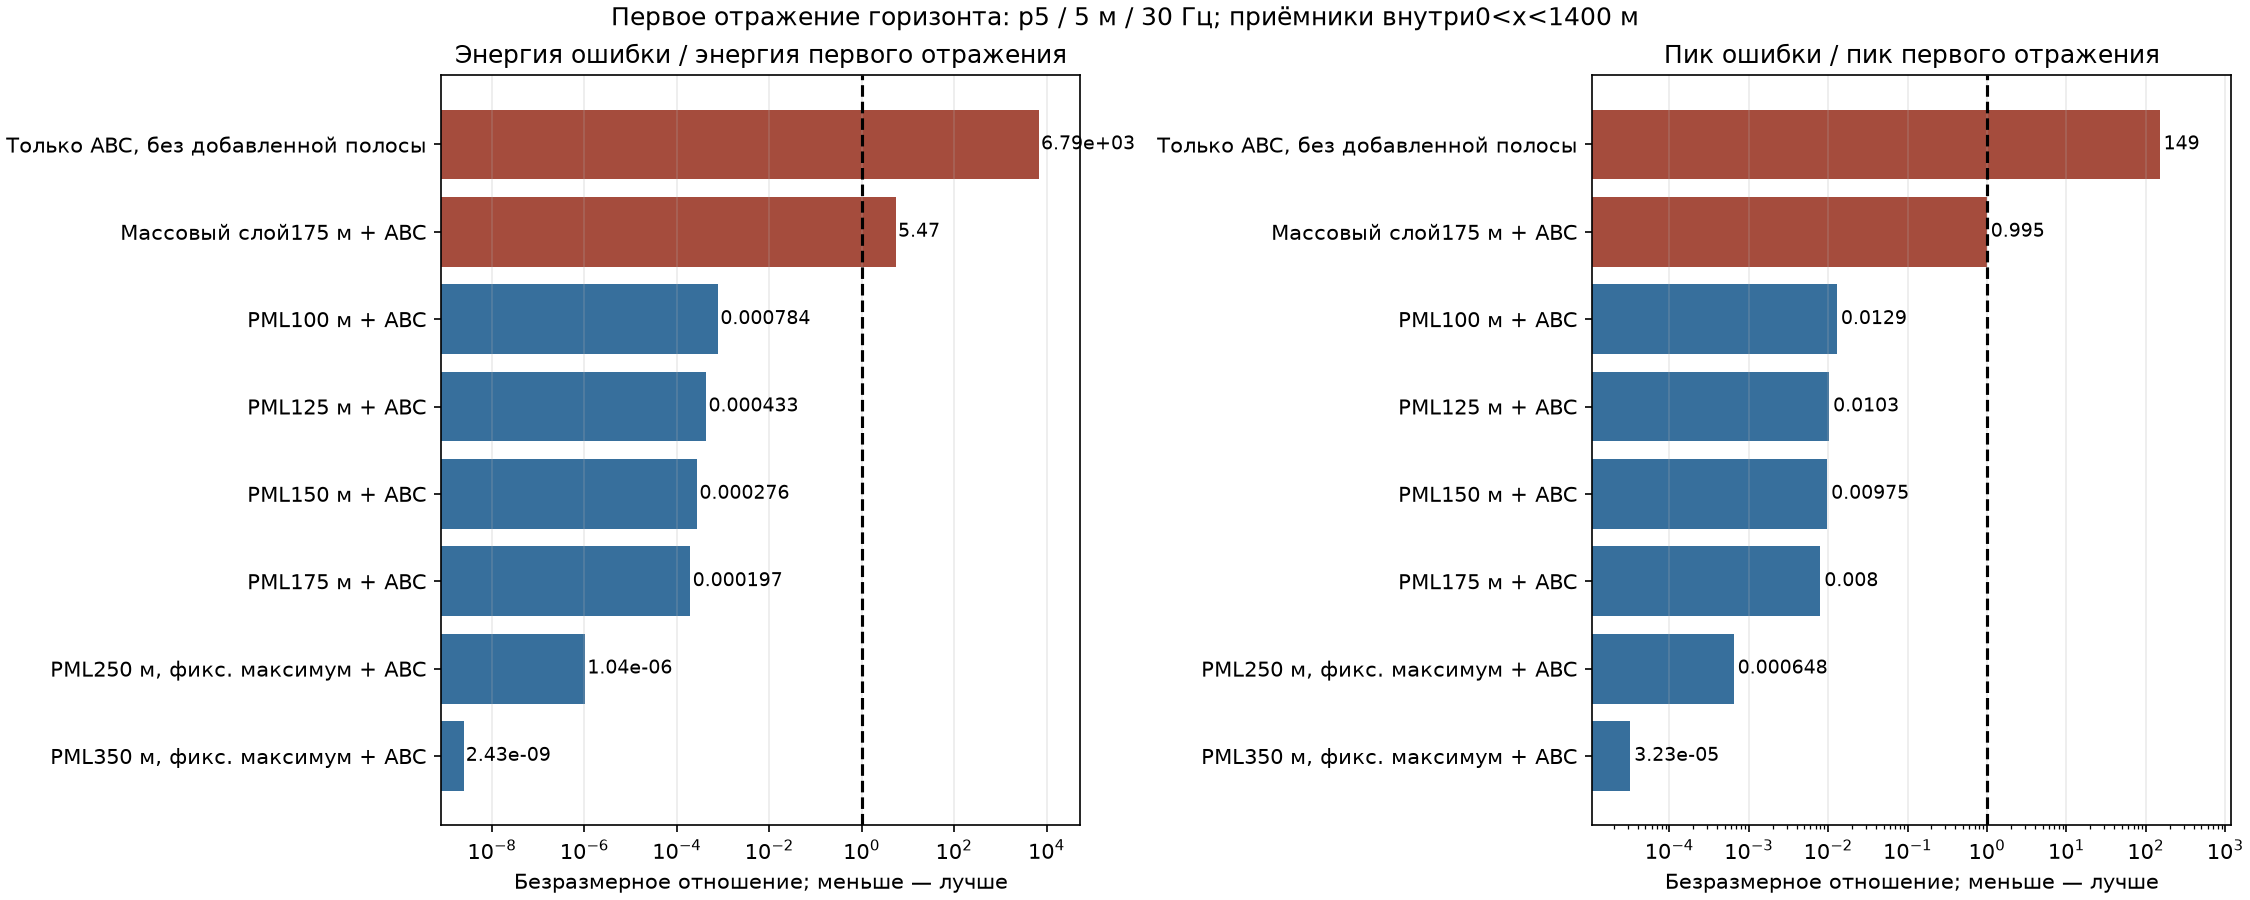

In [14]:
chapter15_first_root = PROJECT_ROOT / "data/dev_1_5_geometry_frequency/pml_layered_cached_saturn_v1/first_reflection_v1"
chapter15_first_record = read_json(chapter15_first_root / "metrics.json")
assert chapter15_first_record["status"] == "completed"
for chapter15_first_label in ("abc_only", "old", "L100", "L125", "L150", "L175", "F250"):
    chapter15_first_row = mapping(mapping(chapter15_first_record["cases"])[chapter15_first_label])
    print(chapter15_first_label, "Eош/Eперв:", chapter15_first_row["energy_error_to_first"], "Aош/Aперв:", chapter15_first_row["peak_vector_error_to_first"])
display(Image(filename=str(PROJECT_ROOT / "img/dev_1_5_geometry_frequency/pml_first_reflection_v1/comparison.png"), width=1300))

Старый массовый слой даёт практически равный первому отражению пик ошибки0,9953, подтверждая наблюдение пользователя; интегральная энергия всей ошибки за1 с в5,475 раза больше энергии первого импульса. PML175 м снижает пик до0,7999% первого отражения (125× слабее), энергию до0,01972% (5071× меньше). PML150 м даёт0,9747% и0,02764%;100 м —1,2935% и0,07839%. Для критерия относительно первого яркого отражения550 м не требуется. В этой серии150 м — наименьшая проверенная толщина без флага роста с глобальным пиком ошибки ниже1%;125 м даёт1,0315%. Это фактическое пересечение выбранного числового уровня, не универсальное требование пользователя и не доказательство долгосрочной устойчивости. На отдельных приёмниках собственный первый импульс слабее глобального максимума: для175 м максимум отношения локальных пиков2,604%,95-й процентиль2,307%. Не следует представлять глобальные125× как гарантию для каждой трассы.

При100/125/150/175 м dmax=173,088611·175/L, у F250 фиксирован173,088611 с⁻¹. У F250 пик0,06485% первого отражения, энергия0,0001038%; это дополнительный запас за46,953 с вместо37,815 с у175 м. ABC без полосы даёт пик149,225 и энергию6786,404 относительно первого отражения: сильная исходная поверхностная волна отражается от границы значительно ярче слабого отражения близких по свойствам слоёв. Его время18,214 с; старый слой29,930 с. Все тайминги одиночные, с регистрацией. Тонкие варианты с ростом поля остаются непригодными независимо от этой перенормировки; прежний слабый рост100 м в однородной серии не отменён.

Новый анализ: data/dev_1_5_geometry_frequency/pml_layered_cached_saturn_v1/first_reflection_v1/{metrics.json,curves.npz}; curves и полные массивы остаются на Saturn. Входы включают23 сейсмограммы с проверенными SHA и метаданные одной native-библиотеки. ABC-контроль дополнительно проверяет SHA полей/координат/масс, поверхность точно совпадает с полями. Первоначальный отказ строгого сравнения геометрических границ из-за округления≈2e−13 м сохранён отдельным журналом; проверка заменена абсолютным допуском1e−8 м, массивы не менялись. Код передан6ad1265/650a659/eb5d4cb в ранее разрешённых файлах. Выходные рисунки: img/dev_1_5_geometry_frequency/pml_first_reflection_v1/{comparison.png,seismograms.png,pml_errors_x100.png,central_traces.png,index.html,render.json}. Основные сейсмограммы используют одну линейную шкалу без усиления; отдельный рисунок деталей явно усиливает ошибку100×. Производственная очередь не возобновлялась.

## 14. Время p4/p5 и проверка шага CFL для PML

По поручению пользователя сравниваем время полного теста для p4 и p5, h5 м, двухслойная основная область1400×700 м, интерфейс−350 м, центральный Рикер30 Гц вниз1 Н/м,1 с, β1/27. Четыре оформления: ABC на границах основной области без дополнительной полосы; PML100/175/250 м с внешним ABC. Массового демпфирования нет. Профили сохранены из последнего сравнения: квадратичный dmax302,905069 с⁻¹ для100 м,173,088611 с⁻¹ для175 и250 м. Таким образом, у250 м используется F250, а не L250 с постоянным интегралом.

Последние исходники общего lin_elast_2d_seismic_newmark_kim_cu побайтово совпали со снимком seismic_pml_cached_v1:52 файла исходников/контрактов проверены. Изменения специализированного p5 в соседнем проекте не означают изменения общего seismic. Используется существующая отдельная сборка с native SHA7de2a009645e541daaa373b3dcb1c3e4617d2f98dbe06847c9bf7389f6ac2ae0; повторная сборка идентичных исходников не выполнялась.

Для активного PML автоматическая оценка CFL по-прежнему запрещена. Пользователь прямо разрешил получить dt средствами решателя с cfl_safety0,8 на каждой той же сетке с материалами и ABC, но без PML, затем явно применить шаг к полной модели. Отказ native prepare с активным PML воспроизводится и сохраняется при обоих порядках. Без слоя используется непосредственно native CFL0,8. Такт0,001 с,21 кадр полного поля через0,05 с,1001 поверхностный отсчёт всех верхних GLL-узлов. Это не оценка спектра связанной системы с памятью PML.

Первоначальный план40 полных запусков последовательно на одной A100 GPU0: по одному прогреву и три измеряемых повтора каждого из8 вариантов, затем по одному контролю dt/2. По дополнительному поручению пользователя добавлены ещё10 запусков PML175 м без ABC для обоих порядков: свободный внешний край, тот же профиль, отдельный native CFL-probe на сетке без PML и без ABC, прогрев/три повтора/dt2. Всего50 запусков; исходный plan.json сохраняется, дополнение фиксируется extra_plan_noabc.json. Порядок толщин циклически меняется между повторами. Основная метрика времени — медиана синхронного model.run, включая регистрацию, но без сборки/prepare и конечного хеширования. Сохраняются минимум/максимум, полное время до хеширования и время отдельного CFL-probe. Запись каждого повтора в отдельный каталог; прежние результаты не перезаписываются.

Проверка шага сравнивает поверхность на одинаковых узлах внутри каждого порядка, строго внутри основной области и вне20 м от точечного источника, с GLL-весами. Отдельные окна0–1,0,15–1 и0,5–1 с. Полные поля сравниваются на21 кадре с массой основной области. Диагностика включает конечность полей/памяти PML, точное совпадение поля и сейсмограммы на общих временах, повторяемость запусков, SHA файлов и эволюцию максимума внутри PML. Эти проверки оценивают конкретный секундный тест, не доказывают долгосрочную устойчивость.

p4_abc_only dt, с: 2.9411764705882354e-05 медиана run, с: 7.958423933014274 L2 полей dt/dt2: 5.7098225446227334e-05
p4_L100 dt, с: 2.9411764705882354e-05 медиана run, с: 13.140195393934846 L2 полей dt/dt2: 5.1227394999015216e-05
p4_L175 dt, с: 2.9411764705882354e-05 медиана run, с: 16.95397057943046 L2 полей dt/dt2: 5.12286156704643e-05
p4_F250 dt, с: 2.9411764705882354e-05 медиана run, с: 21.015185743570328 L2 полей dt/dt2: 5.122876520353749e-05
p4_P175_noabc dt, с: 0.00011111111111111112 медиана run, с: 4.914789807982743 L2 полей dt/dt2: 0.0007328892912180533
p5_abc_only dt, с: 1.9607843137254903e-05 медиана run, с: 17.716384102590382 L2 полей dt/dt2: 2.537397792126985e-05
p5_L100 dt, с: 1.9607843137254903e-05 медиана run, с: 28.090413765981793 L2 полей dt/dt2: 2.2763071226021665e-05
p5_L175 dt, с: 1.9607843137254903e-05 медиана run, с: 36.791017399169505 L2 полей dt/dt2: 2.2763613645880267e-05
p5_F250 dt, с: 1.9607843137254903e-05 медиана run, с: 45.67155236378312 L2 полей dt/dt2: 2

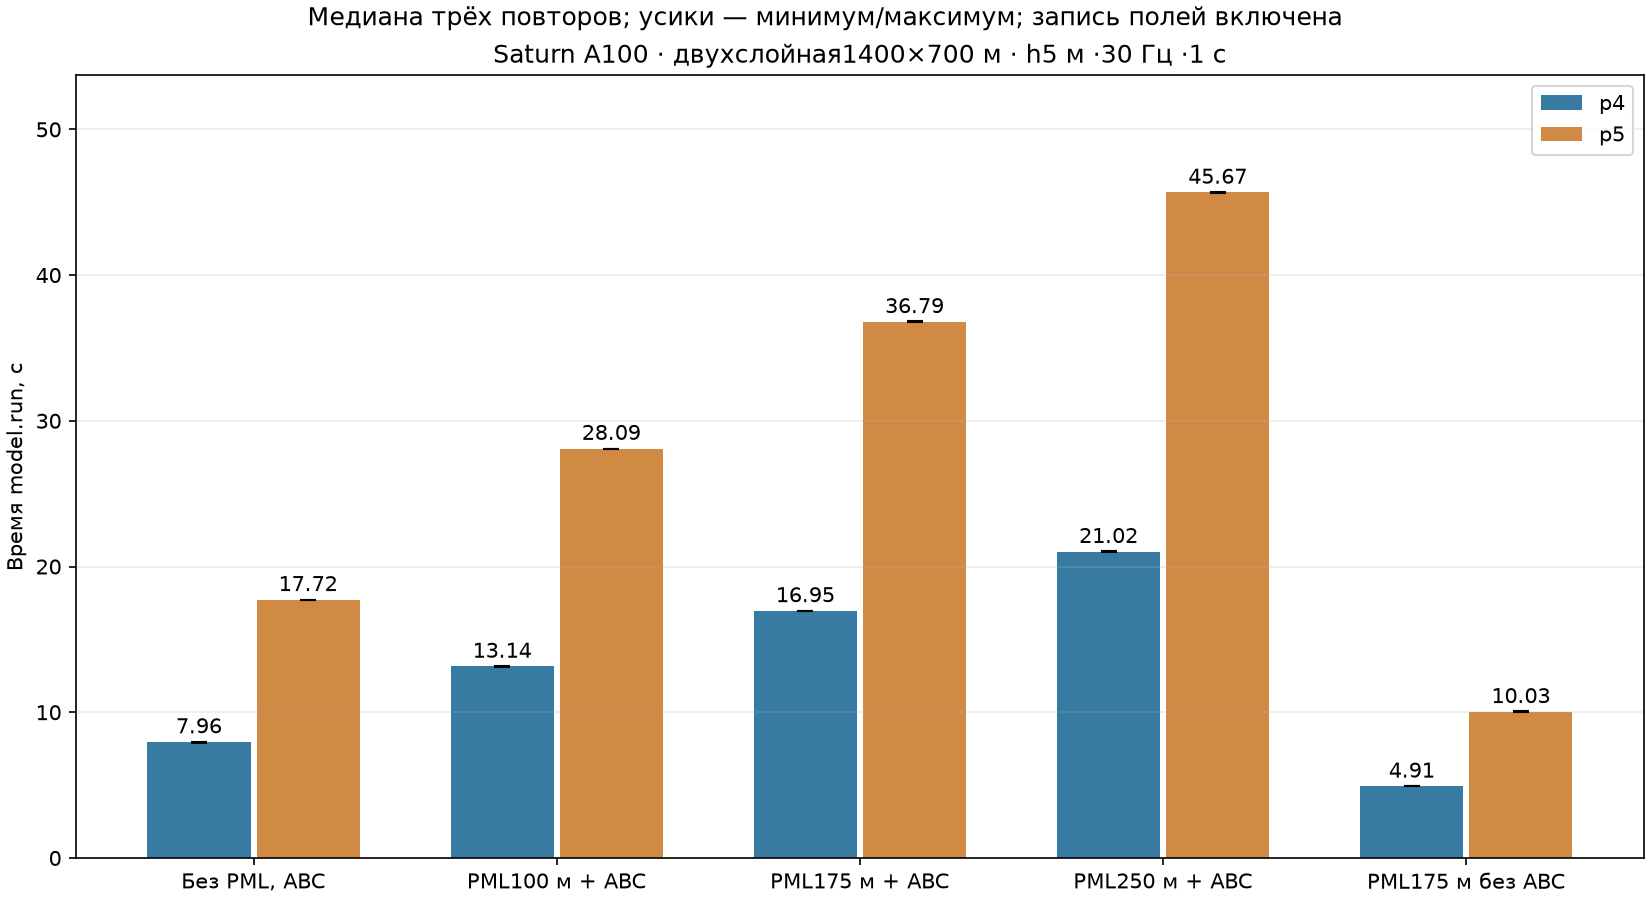

In [15]:
chapter15_timing_root = PROJECT_ROOT / "data/dev_1_5_geometry_frequency/pml_timing_native_cfl_v1"
chapter15_timing_path = chapter15_timing_root / "analysis/metrics.json"
if chapter15_timing_path.exists():
    chapter15_timing_record = read_json(chapter15_timing_path)
    assert chapter15_timing_record["status"] == "completed"
    for chapter15_timing_label, chapter15_timing_value in mapping(chapter15_timing_record["cases"]).items():
        chapter15_timing_row = mapping(chapter15_timing_value)
        print(chapter15_timing_label, "dt, с:", chapter15_timing_row["native_dt_s"], "медиана run, с:", chapter15_timing_row["median_run_seconds"], "L2 полей dt/dt2:", chapter15_timing_row["temporal_core_fields_relative_l2"])
    display(Image(filename=str(PROJECT_ROOT / "img/dev_1_5_geometry_frequency/pml_timing_native_cfl_v1/timings.png"), width=1300))
else:
    print("Серия p4/p5 с проверкой шага ещё выполняется; итоговые метрики не сохранены локально.")

Серия завершена23.11.2026:50 полных запусков, из них30 измеряемых повторов;200 SHA массивов проверены. Во всех случаях конечны полные поля и память PML, записаны21 поле и1001 сейсмограмма; на общих временах поверхность побитово совпадает с полями. CPU-проверки восьми основных сеток/порядков и двух дополнительных контролей, mypy и проверка командной строки прошли. Все измерения выполнены последовательно на GPU0 A100, прогревы и dt/2 исключены из медиан.

abc_only: p4 7.958424 с (K34), p5 17.716384 с (K51).

L100: p4 13.140195 с (K34), p5 28.090414 с (K51).

L175: p4 16.953971 с (K34), p5 36.791017 с (K51).

F250: p4 21.015186 с (K34), p5 45.671552 с (K51).

P175_noabc: p4 4.914790 с (K9), p5 10.028708 с (K13).

С ABC native CFL0,8 даёт одинаковый шаг для всех толщин внутри порядка: p4 dt1/34000 с=29,411765 мкс, p5 dt1/51000 с=19,607843 мкс. Без ABC при175 м шаг крупнее: p4 dt1/9000 с=111,111111 мкс, p5 dt1/13000 с=76,923077 мкс. Поэтому уменьшение времени без ABC в3,449/3,669 раза нельзя приписывать только исключению граничного ядра: основная причина — снижение числа шагов. Варианты100/175/250 м+ABC непосредственно сравнимы по числу шагов. Время включает регистрацию полей, а физическая запись на диск может использовать системный кэш; это не отдельный бенчмарк накопителя.

Разность с dt/2 по полным полям основной области составляет0,00512–0,00571% при p4+ABC и0,00228–0,00254% при p5+ABC. Без ABC —0,07329%/0,03509%. Поверхностная L2 вне20 м от источника за0,15–1 с:0,00717–0,00824%/0,00319–0,00366% с ABC и0,10263%/0,04914% без ABC. Это разность двух временных дискретизаций, не точная ошибка решения.

Большой максимум временной разности, нормированный на слабое первое отражение, возникает на сильной прямой поверхностной волне около0,365–0,368 с у краёв основной области. Он не является ошибкой самого первого отражения. Отдельное окно первого PP в центральной полосе |x−700|≤200 м,±0,03 с по гиперболе, даёт пиковую разность с dt/2 не выше0,005145%/0,003153% с ABC; без ABC —0,068692%/0,032875%. Нормировка здесь на пик окна решения dt/2, без вычитания однородного контроля; это диагностическое окно первого отражения, не строгое модовое разложение. Разность сохраняет первые приходы и не указывает на срыв расчёта выбранными шагами за1 с.

Однако PML100 м показывает слабый монотонный рост полного пика внутри слоя после0,7 с: в11,7597 раза при p4 и35,2069 раза при p5 к1 с; при dt/2 соответственно11,7603 и35,2083. Первоначальный флаг на интервале0,6–1 с его не отмечал из-за ещё убывающего участка0,6–0,7 с. Начальные метрики сохранены; дополнительная диагностика и reviewed.html явно указывают рост. Уменьшение шага вдвое его не устраняет, поэтому100 м не объявляется подтверждённо устойчивым на длительных интервалах. У175/250 м и175 м без ABC такого монотонного роста за проверенное время нет; кинетическая энергия основной области убывает. Устойчивость временного интегрирования не равна качеству поглощения: удаление ABC меняет возврат волн, и выигрыш времени не означает сохранения поглощающей эффективности.

Входы: четыре регулярные Q2-сетки, материалы верхних двух слоёв EFVB00000, общий seismic_pml_cached_v1 с подтверждённым совпадением текущих исходников, исходные профили L100/L175/F250. Код расширен в ранее разрешённых pml_layered/analyze/render.py и передан c4cfb60/3520ddb/f5b91b0/99e7c30/fc3e7ee/b3e5b8b. Выходы: data/dev_1_5_geometry_frequency/pml_timing_native_cfl_v1/{plan.json,extra_plan_noabc.json,environment.json,extra_environment.json,runs_completed.json,extra_runs_completed.json}, p4/p5 с probe/warmup/repeat0–2/half_dt и сохранёнными отказами native PML CFL, analysis/{metrics.json,first_pulse_temporal.json}, artifact_validation.json и runtime_logs. Локальные CPU-свидетельства — pml_timing_cpu_v1/{plan.json,latest_source_check.json,extra_noabc_check.json}. Поля и сейсмограммы остаются на Saturn; локально метаданные и рисунки. Отчёт: img/dev_1_5_geometry_frequency/pml_timing_native_cfl_v1/reviewed.html, исходный index.html сохранён, рисунки timings.png и field_diagnostics.png, манифесты render.json/review.json. Обе GPU свободны, доступно114,07 ГиБ, производство остаётся остановленным.

## 15. Толстый PML без ABC против100 м+ABC: p4

Проверяем гипотезу пользователя только для p4: можно ли заменить100 м PML+ABC более толстым PML без ABC, получив меньшее время при не худшей точности. Основная двухслойная модель1400×700 м, h5 м, интерфейс−350 м, центральная сила Рикера30 Гц вниз1 Н/м,1 с, β1/27. Базовый вариант L100 имеет квадратичный максимум302,905069 с⁻¹; кандидаты175/250/350 м без ABC — постоянный максимум173,088611 с⁻¹. Верх свободный; без ABC внешний край PML тоже свободный. Исторические результаты сохраняются.

После предыдущей серии изменились исходники общего seismic: удалён запрет cfl_safety при активном PML. Пользователь явно разрешил новый снимок docs/runtime_sources/seismic_pml_cfl_v1, build_pml_cfl.sh и изменение pml_layered.py; они переданы a82e66f. Новая среда .runtime_ch15_pml_cfl_v1 собрана отдельно на Saturn. Native SHA b4e112aa7fea5772c3cdbd191d94971a4a381f97fddbb6f55a64687bc4e59583. Теперь CFL0,8 задаётся полной PML-модели; спектр остаётся спектром обычной упругости и статического демпфирования, без оценки связанной памяти PML. В контрольном L100 сейсмограмма совпала с прошлой сборкой до относительной L2=1,45553e−13.

Для каждого из четырёх вариантов выполняются полный прогрев, три измеряемых повтора с циклическим порядком и контроль dt/2; у250/350 м также отдельный опыт с шагом базового L100. Все измерения последовательно на A100GPU0. Время — синхронный model.run с21 полным полем и1001 поверхностным отсчётом. Контрольные одиночные времена не смешиваются с медианами. Базовый100 м+ABC заново измеряется той же сборкой.

100 м+ABC является целью сравнения, а не точным решением. Для разделения ошибок построена расширенная p4-модель5400×2700 м, x−2000…3400,y−2700…0, с тем же интерфейсом−350 м, без PML/ABC. Первый геометрический возврат внешней границы в основную область не раньше4700/4087≈1,15 с. Расширенные контроли используют шаги базового варианта, кандидатов и половину базового шага. Ошибка поглощения — кандидат минус расширенный контроль при том же dt; полная ошибка — кандидат минус расширенный контроль с малым dt. Последняя включает временную дискретизацию, но не измеряет общую пространственную ошибку p4 относительно точного решения PDE.

Обе ошибки сравниваются с ошибкой L100 по энергии сигнала0,001ΣwGLL(Vx²+Vy²) и максимуму векторной скорости. Сохраняются все приёмники строго внутри основной области и отдельная маска вне20 м от точечного источника, окна0–1 и0,5–1 с. Первое PP-отражение проверяется отдельно в центральной полосе±200 м с окном±0,03 с по геометрической гиперболе; слабые поздние кратные не становятся новым требованием. Более сильное гашение нельзя автоматически объявлять той же точностью всей записи при более крупном шаге. Дополнительные контроли позволяют отделить эти два эффекта.

L100 медиана run, с: 13.123864731751382 ускорение: 1.0
P175_noabc медиана run, с: 4.915088196285069 ускорение: 2.6701178509209025
P250_noabc медиана run, с: 6.0851312186568975 ускорение: 2.1567102269732263
P350_noabc медиана run, с: 7.80251332372427 ускорение: 1.6820047832340186


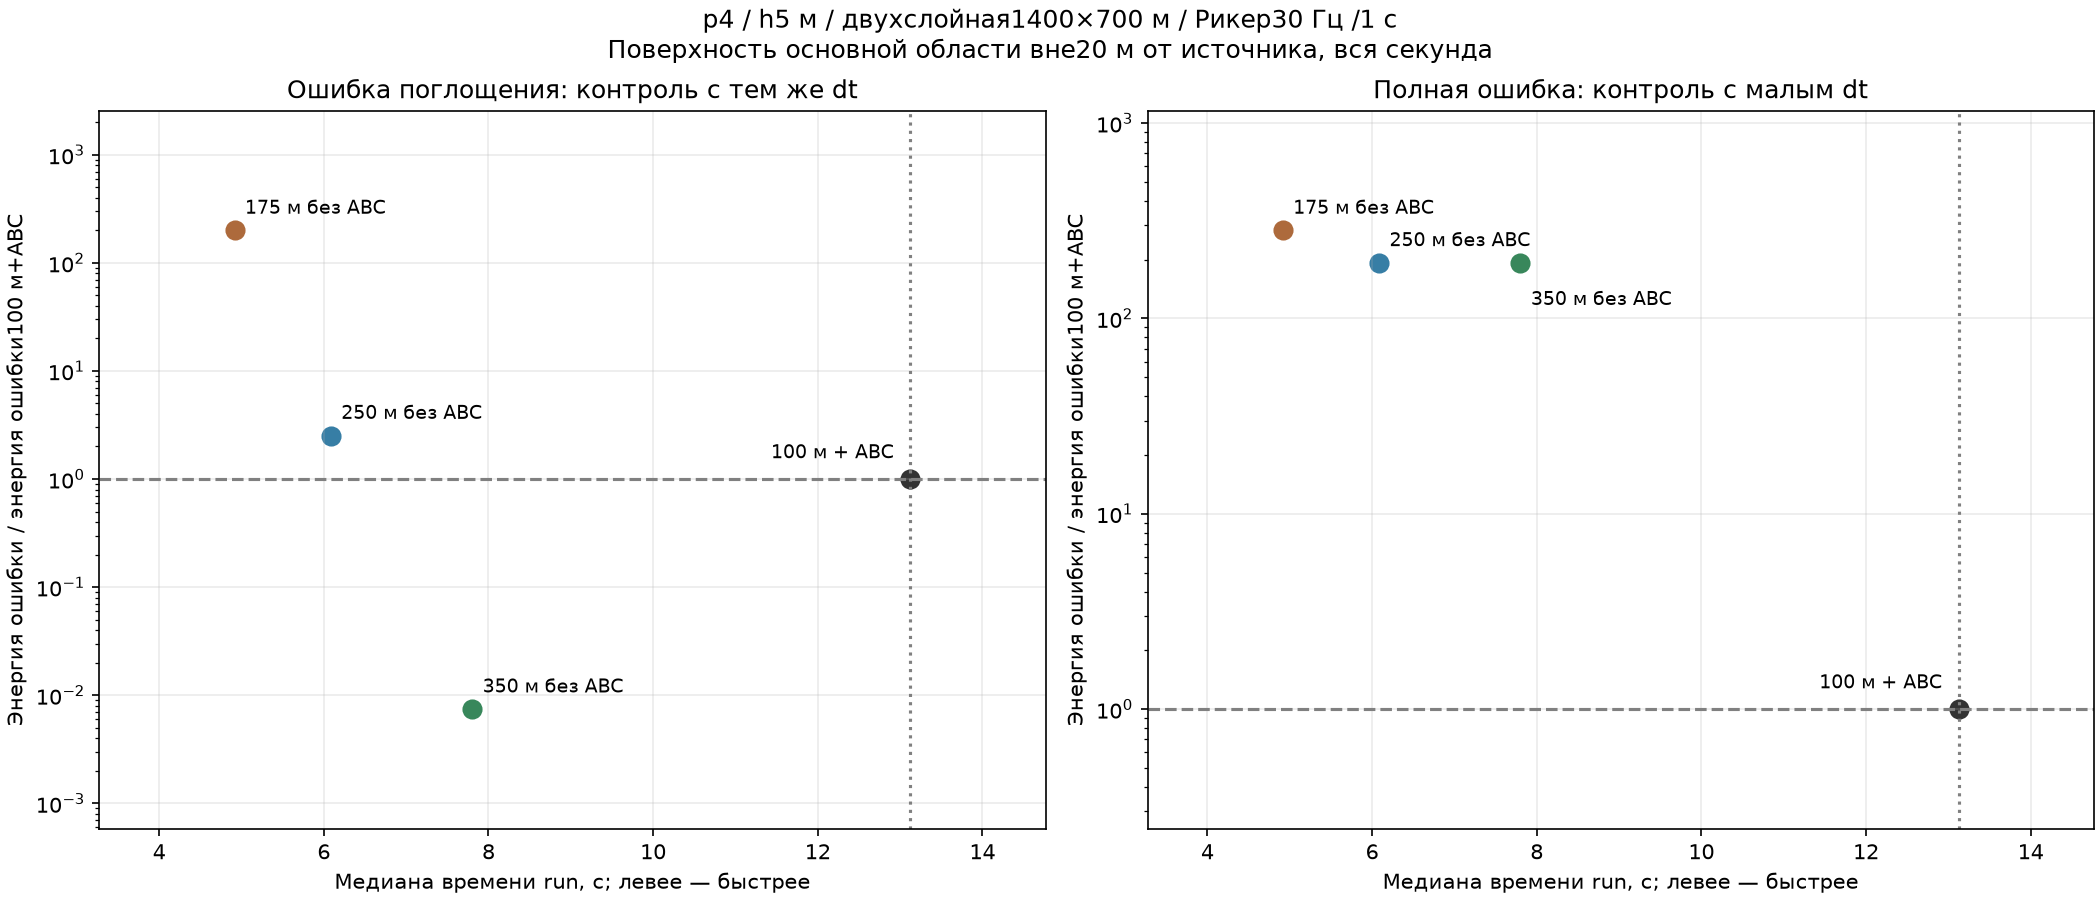

In [16]:
chapter15_trade_root = PROJECT_ROOT / "data/dev_1_5_geometry_frequency/pml_p4_noabc_tradeoff_v1"
chapter15_trade_path = chapter15_trade_root / "analysis/metrics.json"
if chapter15_trade_path.exists():
    chapter15_trade_record = read_json(chapter15_trade_path)
    assert chapter15_trade_record["status"] == "completed"
    for chapter15_trade_label, chapter15_trade_value in mapping(chapter15_trade_record["cases"]).items():
        chapter15_trade_row = mapping(chapter15_trade_value)
        chapter15_trade_native = mapping(mapping(chapter15_trade_row["variants"])["native"])
        print(chapter15_trade_label, "медиана run, с:", chapter15_trade_native["median_run_seconds"], "ускорение:", chapter15_trade_native["speedup_vs_baseline"])
    display(Image(filename=str(PROJECT_ROOT / "img/dev_1_5_geometry_frequency/pml_p4_noabc_tradeoff_v1/tradeoff_reviewed.png"), width=1300))
else:
    print("Сравнение толстого PML без ABC ещё выполняется; итоговый анализ не сохранён локально.")

Серия завершена:25 запусков и100 проверенных SHA массивов. Медианы трёх model.run на A100:100 м+ABC —13,123865 с;175 м без ABC —4,915088 с;250 м —6,085131 с;350 м —7,802513 с. Native CFL0,8 даёт dt=1/34000 с с ABC и1/9000 с без ABC:29,411765 против111,111111 мкс. Все поля конечны; контроли половинного шага выполнены. Более крупный dt объясняет основную часть ускорения.

По качеству поглощения гипотеза подтверждена для350 м без ABC: ускорение1,682 раза; энергия ошибки поглощения0,00743468 от L100 (ниже в134,50 раза), векторный пик0,1392977 (ниже в7,179 раза). Здесь ошибка — разность с расширенной моделью при том же dt, поверхность основной области вне20 м от источника, вся1 с.175 м и250 м без ABC хуже L100: отношения энергий199,6675 и2,52571, пиков20,3229 и2,38423. Метрика энергии — интеграл квадрата скорости с GLL-весами, не механический поток энергии. Маска всех внутренних приёмников даёт тот же качественный вывод.

Однако одинаковая точность всей сейсмограммы при максимальном native dt не получена. Относительная L2 против расширенного p4-контроля с dt=1/68000 с составляет0,0083735% у100 м+ABC и0,1158401% у350 м без ABC. Пиковая разность в диагностическом окне первого PP относительно пика этого окна —0,0051444% против0,0902634%. Потеря связана прежде всего с временной ошибкой сильной прямой волны; это не усиление отражения от внешней границы. В позднем окне0,5–1 с даже полная энергия ошибки350 м ниже L100 в122,87 раза, пик —в7,18 раза. Контроль сохраняет пространственную дискретизацию p4 и не является точным решением PDE.

При общем с L100 шаге350 м без ABC занимает27,000442 с; при половине собственного native шага —14,672883 с. Это одиночные контрольные времена, не медианы. Следовательно,350 м без ABC быстрее и лучше подавляет паразитные возвраты при допустимой временной погрешности около0,1%; если требовать точность всей записи на уровне L100, выигрыш скорости проверенными вариантами не подтверждён. Минимальная подходящая толщина между250 и350 м не определена; производственная конфигурация не изменена.

L100 сохраняет слабый рост пика внутри PML после0,7 с примерно в11,76 раза к1 с при обоих шагах; более толстые варианты без ABC за проверенную1 с такого роста не показывают. Эти наблюдения не доказывают долгосрочную устойчивость PML. Обе GPU после серии свободны; свободно112155340800 байт (104,45 ГиБ). Производственная очередь остаётся остановленной.

Входы: двухслойная EFVB00000, четыре сетки p4/h5 и расширенная контрольная сетка5400×2700 м, снимок docs/runtime_sources/seismic_pml_cfl_v1. Код передан a82e66f/2439c79/a88f068. Выходы: data/dev_1_5_geometry_frequency/pml_p4_noabc_tradeoff_v1/{plan.json,environment.json,baseline_version_check.json,runs_completed.json,analysis/metrics.json,artifact_validation.json,completion.json,runtime_logs}; каталоги L100/P175_noabc/P250_noabc/P350_noabc и R2000 с метаданными. Тяжёлые поля, сейсмограммы и analysis/curves.npz остаются на Saturn. Локальные иллюстрации и отчёт — img/dev_1_5_geometry_frequency/pml_p4_noabc_tradeoff_v1/{reviewed.html,tradeoff_reviewed.png,boundary_seismograms.png,field_checks.png}; исходные index.html/tradeoff.png сохранены, манифесты render.json/review.json. Дневник читает сохранённые свидетельства без SSH и GPU-запуска.

## 16. Фиксированные порядки: PML350 без ABC, родной шаг ##

Пользователь выбрал новую эталонную постановку: двухслойная1400×700 м,30 Гц,1 с, PML350 м без ABC, native CFL0,8. Сохраняются центральная сила Рикера вниз1 Н/м,t0=0,05 с, β=1/27, γ=0,5 и квадратичный профиль PML с максимумом173,088611 с⁻¹. Прямоугольная область со слоем2100×1050 м. Свободные границы остаются естественными условиями задачи; одномерные граничные элементы не создаются вообще, mesh.strata содержит только объёмное пространство1. Верхние приёмники задаются узлами, а сравнение разных порядков использует полиномиальную SEM-интерполяцию на общий набор x=0,1,…,1400 м.

Основные конфигурации p4/p5 при h5 м и p6/p7 при h10 м. Для каждой общий seismic и новый специализированный решатель соответствующего порядка: полный прогрев и три измеряемых повтора последовательно на одной A100. Родные шаги получаются непосредственно из solver.prepare с CFL0,8 полной PML-модели и должны совпадать внутри пары общего/фиксированного решателей. Время синхронного model.run включает1001 поверхностный отсчёт и21 полное поле, исключает сборку, prepare и конечное хеширование. Разный объём полей при разных p/h входит в стоимость полной задачи.

Оценка точности разделяет родные dt и общий малый dt. Для каждого варианта предусмотрены dt/2 и общий шаг, равный половине минимального native dt, включая p9/5 м. Контроли p8/5 м и p9/5 м при общем dt, а также p9/5 м при половинном общем dt оценивают неопределённость контроля; p9 не объявляется точным решением. Сравниваются все внутренние приёмники и отдельно приёмники вне20 м от источника, окна0–1/0,15–1/0,5–1 с, диагностическое окно первого PP. Попарные разности порядков сохраняются отдельно. Слой350 м общий для всех; это оценка согласования порядков в выбранной поглощающей постановке, не новая оценка бесконечной среды.

Подготовлен неизменяемый снимок docs/runtime_sources/seismic_fixed_pml_orders_v1 с текущим общим seismic, специализированной серией p1…p9 и общим кодом, а также scripts/dev_1_5_geometry_frequency/{pml_fixed_orders.py,pml_fixed_report.py,build_fixed_pml_orders.sh}. Из серии будут собраны p4…p9 и общий seismic; p1…p3 не запускаются. План43 полных запуска и9 CFL-probe, отдельная среда .runtime_ch15_fixed_pml_orders_v1, данные data/dev_1_5_geometry_frequency/pml_fixed_orders_v1, иллюстрации img/dev_1_5_geometry_frequency/pml_fixed_orders_v1. Локальная подготовка и CPU-проверки — pml_fixed_orders_cpu_v1. На Saturn перед работой проверены свободные GPU и около104,4 ГиБ свободного места. Минимум20 ГиБ свободно сохраняется, тяжёлые поля не отправляются в Git и не копируются локально. Производственная очередь не возобновляется.

Серия завершена:43 полных запуска и9 CFL-probe. Код передан bb1fdcd/d76cef9/e2760c4 в явно разрешённом scope, все вычисления последовательно на A100GPU0. Проверены172 SHA массивов; общий и фиксированные решатели согласуются по всем полям и сейсмограммам трёх повторов: максимальная относительная L2 компонент1,86430e−12. В каждой паре одинаковые узлы, источник и native dt; одномерных граничных элементов нет.

p4_h5 generic медиана run, с: 7.807120637968183 dt, с: 0.00011111111111111112
p4_h5 fixed медиана run, с: 7.042431735433638 dt, с: 0.00011111111111111112
p5_h5 generic медиана run, с: 15.954724606126547 dt, с: 7.692307692307693e-05
p5_h5 fixed медиана run, с: 14.62237561866641 dt, с: 7.692307692307693e-05
p6_h10 generic медиана run, с: 4.299004310742021 dt, с: 0.00011111111111111112
p6_h10 fixed медиана run, с: 4.092742801643908 dt, с: 0.00011111111111111112
p7_h10 generic медиана run, с: 7.337178700603545 dt, с: 8.333333333333333e-05
p7_h10 fixed медиана run, с: 6.918312914669514 dt, с: 8.333333333333333e-05


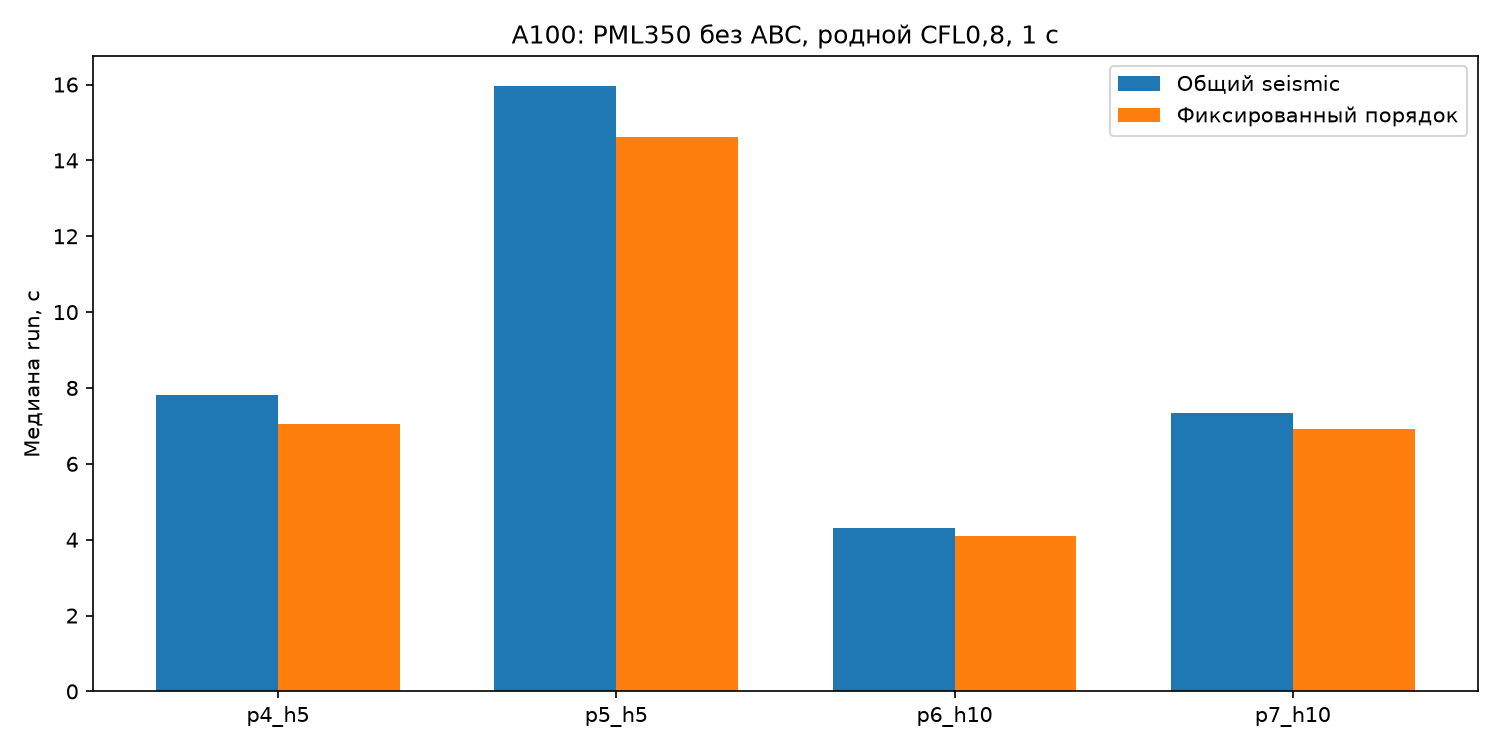

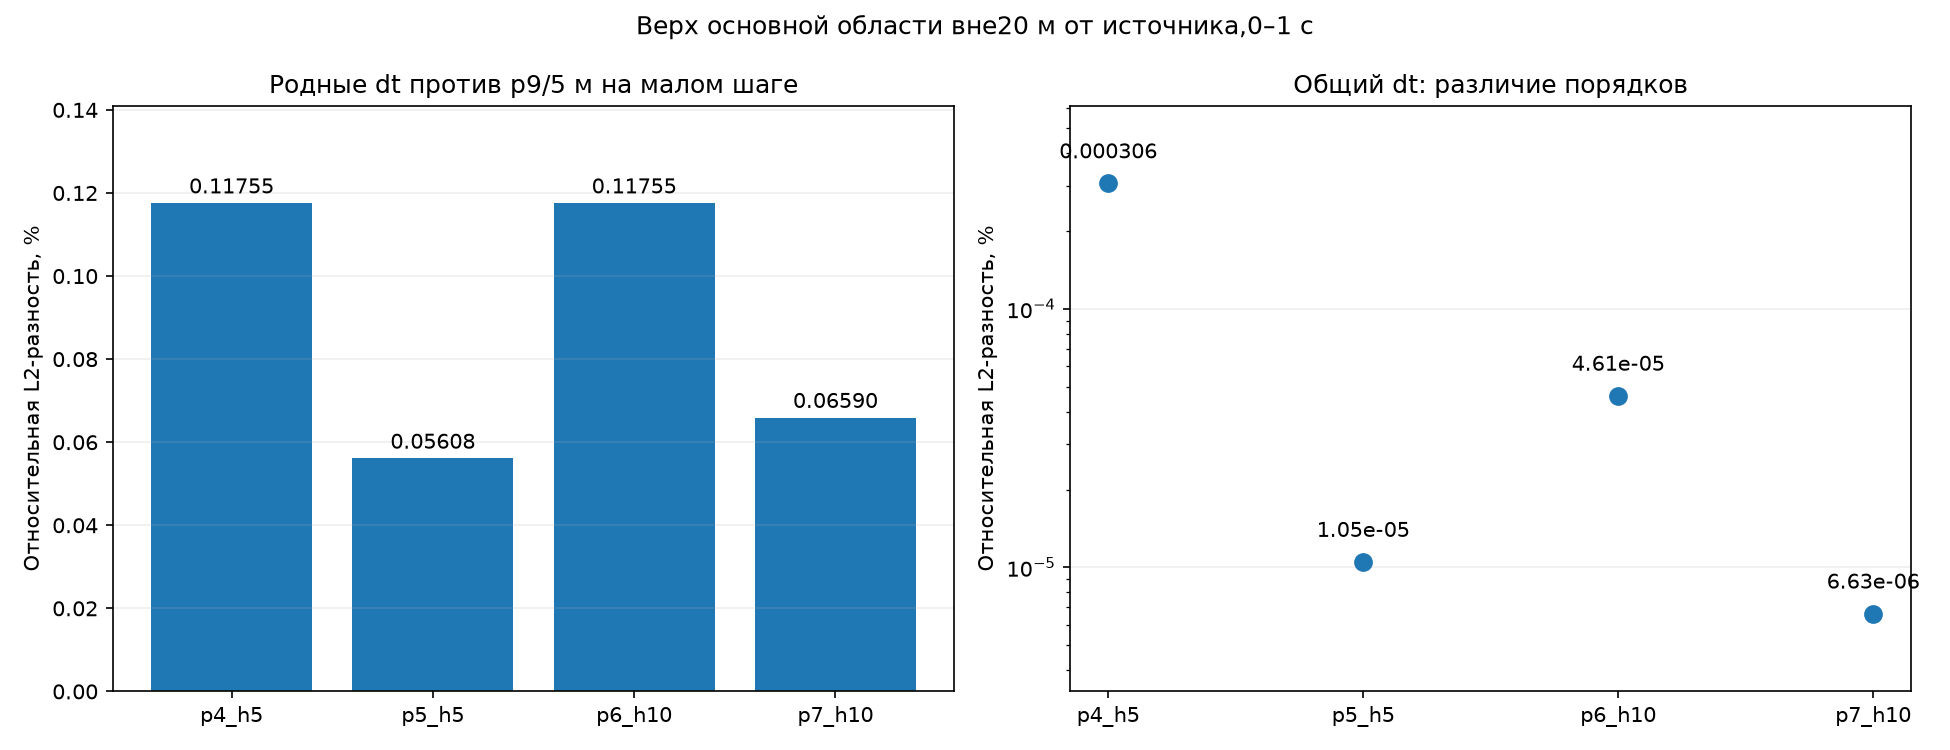

In [17]:
chapter15_fixed_root = PROJECT_ROOT / "data/dev_1_5_geometry_frequency/pml_fixed_orders_v1"
chapter15_fixed_metrics_path = chapter15_fixed_root / "analysis/metrics.json"
if chapter15_fixed_metrics_path.exists():
    chapter15_fixed_metrics = read_json(chapter15_fixed_metrics_path)
    assert chapter15_fixed_metrics["status"] == "completed"
    assert chapter15_fixed_metrics["generic_fixed_agree"] is True
    chapter15_fixed_timings = chapter15_fixed_metrics["timings"]
    assert isinstance(chapter15_fixed_timings, list)
    for chapter15_fixed_timing_value in chapter15_fixed_timings:
        chapter15_fixed_timing = mapping(chapter15_fixed_timing_value)
        print(chapter15_fixed_timing["case"], chapter15_fixed_timing["backend"], "медиана run, с:", chapter15_fixed_timing["median_run_seconds"], "dt, с:", chapter15_fixed_timing["dt_s"])
    display(Image(filename=str(PROJECT_ROOT / "img/dev_1_5_geometry_frequency/pml_fixed_orders_v1/timings.png"), width=1000))
    display(Image(filename=str(PROJECT_ROOT / "img/dev_1_5_geometry_frequency/pml_fixed_orders_v1/accuracy_reviewed.png"), width=1300))
else:
    print("Серия фиксированных порядков ещё выполняется; окончательные метрики локально не сохранены.")

Медианы трёх model.run, общий → фиксированный: p4/5 м7,807121→7,042432 с (ускорение1,10858); p5/5 м15,954725→14,622376 с (1,09112); p6/10 м4,299004→4,092743 с (1,05040); p7/10 м7,337179→6,918313 с (1,06054). Родные шаги соответственно111,111111/76,923077/111,111111/83,333333 мкс. Время включает1001 отсчёт поверхности и21 полное поле; сборка, prepare и конечное хеширование исключены. Различный объём регистрации полей входит в стоимость полной задачи. Контрольные одиночные времена не смешиваются с медианами.

Основная норма — L2 обеих компонент Vx/Vy на одинаковых точках верхней грани x=1,…,1399 м вне20 м от источника, за0–1 с. При родных dt разность с p9/5 м при dt=1/156000 с: p4 —0,1175481%, p5 —0,0560815%, p6 —0,1175487%, p7 —0,0658970%. При общем dt=1/78000 с против p9 на том же шаге:0,000305995%,0,0000105023%,0,0000461445%,0,00000662912%. Общий шаг отделяет пространственную разность от основной временной разности; он не превращает контроль в точное решение PDE.

Пиковая разность первого PP-окна относительно пика контрольного окна, родные dt: p4 —0,0912058%, p5 —0,0434981%, p6 —0,0912240%, p7 —0,0511154%. Это центральная полоса±200 м и окно±0,03 с вокруг0,05+sqrt(700²+(x−700)²)/4087. На общем шаге соответствующие значения0,00111512/0,000913911/0,00232622/0,00261822%; по этому локальному пиковому критерию пространственная сходимость не монотонна. Слабые поздние кратные не использованы как обязательный критерий.

Неопределённость контроля явно сохранена: p8/5 м против p9/5 м при общем dt даёт удалённую L2-разность0,00000235125%; p9 общий dt против dt/2 —0,00117501%. Соответствующие пиковые разности первого PP0,000482494% и0,00160274%. Поэтому наиболее малые пространственные разности трактуются как согласование с контролем, а не как доказанная абсолютная ошибка. Порядок производства для сложных моделей EFVB/ECVB из этого плоскослоистого опыта автоматически не выбирается.

У источника картина иная: при включении всех внутренних приёмников, в том числе самого точечного источника, L2 за всю1 с составляет4,20003/3,10223/4,03583/3,25835% на родных шагах и4,19736/3,10113/4,03308/3,25700% на общем. Даже p8/p9 здесь различаются на0,64576%. Пространственная сходимость непосредственно у источника не установлена; исключение20 м принципиально для приведённых выше малых процентов. За0,15–1 с со всеми внутренними приёмниками разности на родных шагах снижаются до0,13628/0,06502/0,13627/0,07640%.

Для выбранной двухслойной модели p6/10 м быстрее p4/5 м в1,72 раза при почти одинаковой удалённой точности на родном dt. Их попарная L2-разность вне20 м —0,00034043% на родном шаге. p7/10 м занимает почти то же время, что p4/5 м, и снижает разность с малошаговым контролем примерно в1,78 раза. p5/5 м немного точнее p7 на родном dt, но медленнее в2,11 раза. На общем шаге p7/10 м и p5/5 м очень близки к p9. Основная удалённая разность рабочих конфигураций определяется временной дискретизацией; уменьшение native dt вдвое снижает её примерно вчетверо.

Все поля и память PML конечны, поверхность побитово совпадает с полями на21 общем времени. Кинетическая энергия основной области и пик внутри PML к концу записи убывают. Native CFL оценивает обычную упругость и статическое демпфирование; полный спектр связанной памяти PML этим не доказан. Проверка охватывает1 с и сравнение шагов, не является доказательством долгосрочной устойчивости. GPU после серии свободны, производственная очередь остаётся остановленной.

Входы: снимок docs/runtime_sources/seismic_fixed_pml_orders_v1, четыре основные и две контрольные сетки без граничного пространства, материалы двух верхних слоёв EFVB00000, CPU-проверки pml_fixed_orders_cpu_v1/{plan,geometry_equivalence}.json. Выходы: data/dev_1_5_geometry_frequency/pml_fixed_orders_v1/{plan,environment,step_plan,runs_completed,artifact_validation,completion}.json, анализ analysis/metrics.json, runtime_logs, каталоги p4_h5/p5_h5/p6_h10/p7_h10/p8_h5/p9_h5 с метаданными. Поля velocity.npy, nodes.npy, surface.npz и common_surface.npz остаются на Saturn. Иллюстрации img/dev_1_5_geometry_frequency/pml_fixed_orders_v1/{timings.png,accuracy_reviewed.png,reviewed.html}, манифесты render.json/review.json. Исходные index.html/accuracy.png сохранены; reviewed.html явно включает ограничение у источника. Дополнительных GPU-запусков после завершения не требуется.

## 17. Семь независимых источников в одном пакете p6 ##

Пользователь выбрал p6 на сетке10 м и поручил измерить всю серию семи источников в одной модели. Сохраняются двухслойная1400×700 м,30 Гц,1 с, PML350 м без ABC, квадратичный максимум173,088611 с⁻¹, β=1/27, native CFL0,8. Источники x=175,350,525,700,875,1050,1225 м,y=0; крайние x=0/1400 исключены. При p6 есть узлы в серединах элементов, поэтому все источники остаются узловыми силами вниз с пиком1 Н/м.

Один пакет содержит семь несвязанных копий объёмной сетки с одинаковыми координатами и непересекающимися индексами узлов/элементов. Это семь независимых решений, не суперпозиция семи источников в одном физическом поле. В каждой копии собственная память PML и собственный источник. Граничные элементы отсутствуют. Пакет:5569837 узлов,154350 объёмных элементов; его размер меньше уже проверенного p9/5 м. CPU-проверки подтверждают изолированность компонент, точное повторение материалов/PML и попадание всех источников в узлы.

Для честного сравнения одиночные и пакетные расчёты сохраняют одинаковый полезный результат:1001 отсчёт всех узлов верха и21 полное поле Vx/Vy на каждый источник. Вначале отдельные native CFL-probe одной копии и пакета должны дать одинаковый dt; при несовпадении запускатель останавливается до сравнения времени. Затем полный прогрев семи одиночных источников и пакета; три парных круга с чередованием порядка «пакет/одиночные», циклическим порядком источников. Всего32 полных запуска и2 probe, последовательно на A100GPU0. Сравниваются медиана суммы семи измеряемых model.run и медиана пакетного run; отдельно сумма assembly+prepare+run и пакетная стоимость до окончания run. Это не включает запуск Python, постобработку и хеширование. Поля и сейсмограммы каждого источника пакета сравниваются со своим одиночным расчётом в каждом повторе.

Используется уже собранная .runtime_ch15_fixed_pml_orders_v1 и прежний неизменяемый снимок seismic_fixed_pml_orders_v1. Расширены только ранее разрешённые pml_fixed_orders.py/pml_fixed_report.py; новая сборка и новые исходники решателя не нужны. CPU-план data/dev_1_5_geometry_frequency/pml_p6_sources7_cpu_v1/plan.json, оценка массивов16,83 ГиБ. Новая серия data/dev_1_5_geometry_frequency/pml_p6_sources7_v1, отчёт img/dev_1_5_geometry_frequency/pml_p6_sources7_v1. Перед запуском GPU свободны, свободно77,65 ГиБ; резерв20 ГиБ и дополнительный рабочий запас соблюдаются. Производственная очередь не возобновляется. Серия завершена на Saturn:32 полных запуска и2 CFL-probe. Код11bed2b передан через ранее разрешённые два скрипта, без новых снимков и пересборки. Родные шаги одиночной и пакетной модели одинаковы:dt=1/9000 с=111,111111 мкс; оценки λmax205048790,028/205243720,183 округляются к одному K9. Основная очередь не менялась.

Источники x, м: [175.0, 350.0, 525.0, 700.0, 875.0, 1050.0, 1225.0]
Сумма семи одиночных run, с: 28.772195390425622
Пакетный run, с: 26.600856239907444
Ускорение: 1.0816266638538
Эквивалентное время на источник, с: 3.8001223199867775


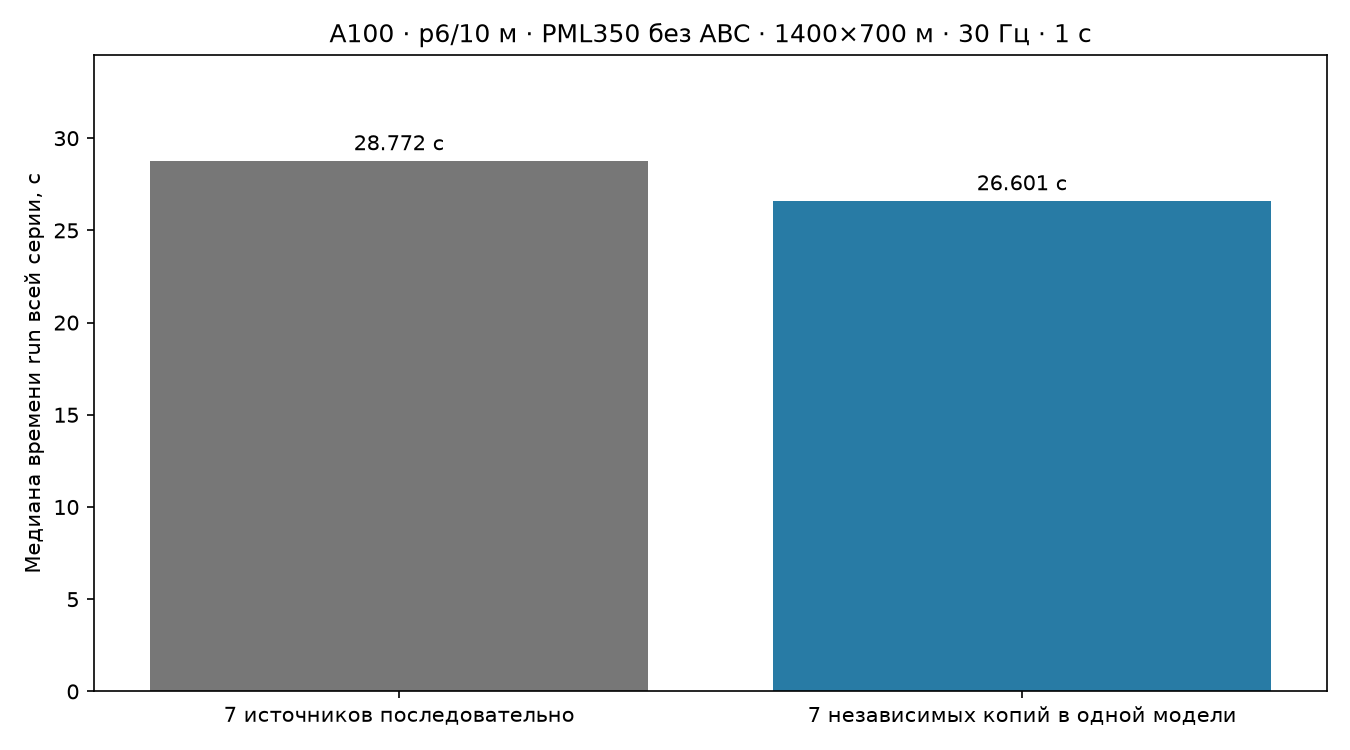

In [18]:
chapter15_sources7_root = PROJECT_ROOT / "data/dev_1_5_geometry_frequency/pml_p6_sources7_v1"
chapter15_sources7_metrics_path = chapter15_sources7_root / "analysis/metrics.json"
if chapter15_sources7_metrics_path.exists():
    chapter15_sources7_metrics = read_json(chapter15_sources7_metrics_path)
    assert chapter15_sources7_metrics["status"] == "completed"
    assert chapter15_sources7_metrics["all_agree"] is True
    print("Источники x, м:", chapter15_sources7_metrics["source_x_m"])
    print("Сумма семи одиночных run, с:", chapter15_sources7_metrics["median_sequential_run_seconds"])
    print("Пакетный run, с:", chapter15_sources7_metrics["median_batch_run_seconds"])
    print("Ускорение:", chapter15_sources7_metrics["run_speedup"])
    print("Эквивалентное время на источник, с:", chapter15_sources7_metrics["equivalent_batch_seconds_per_source"])
    display(Image(filename=str(PROJECT_ROOT / "img/dev_1_5_geometry_frequency/pml_p6_sources7_v1/timings.png"), width=1000))
else:
    print("Проверка пакета семи источников ещё не завершена; итоговые метрики локально не сохранены.")

Все три измеряемые пары «сумма семи одиночных run → пакет»:28,763735→26,504700 с;28,813175→26,655862 с;28,772195→26,600856 с. Медианы28,772195→26,600856 с, ускорение1,081627 раза, экономия7,54666%. Эквивалентное время пакета на источник3,800122 с. Это умеренный воспроизводимый выигрыш; многократного ускорения в этой конфигурации нет.

С учётом построения модели, prepare и run медианы37,185244→33,102422 с, ускорение1,123339 раза, экономия10,97968%. Здесь не учитываются запуск Python, постобработка и хеширование. Физическая запись массивов может пользоваться системным кэшем; это не бенчмарк накопителя. Регистрация одинакова по полезному объёму:1001 отсчёт всего верха и21 полное поле на каждый из семи источников. Эти времена не являются измерением режима с одними редкими сейсмограммами без полей.

Все21 пары «источник×повтор» согласовались по сейсмограммам и полным полям. Максимальная относительная L2 компонент3,39623e−14, максимальная абсолютная разность1,64113e−21 м/с; побитовая идентичность не заявляется. В каждом запуске поверхность побитово совпала с полями на общих временах. Поля и память PML конечны. Проверены128 SHA массивов32 запусков. Изолированность семи копий дополнительно подтверждена CPU-проверкой непересекающихся индексов элементов и источников.

Пакетирование семи источников одной геометрии сохраняет индивидуальные решения и позволяет использовать единый родной dt этой геометрии. Нельзя заменять это семью силами в одной связной сетке: тогда получилось бы суммарное поле. Между будущими пакетами разных геометрий dt может быть индивидуальным; объединение разных геометрий в один пакет с разными dt здесь не проверялось. Принятый пользователем p6/10 м и семь внутренних позиций зафиксированы, производственная очередь не возобновлена.

Входы: прежний снимок docs/runtime_sources/seismic_fixed_pml_orders_v1 и среда .runtime_ch15_fixed_pml_orders_v1, двухслойная EFVB00000, CPU-план pml_p6_sources7_cpu_v1/plan.json. Выходы: data/dev_1_5_geometry_frequency/pml_p6_sources7_v1/{plan,environment,step_plan,runs_completed,artifact_validation,completion}.json, analysis/metrics.json, sources7.log, p6_h10/fixed/{x175…x1225,batch7}_{warmup,repeat0,repeat1,repeat2} с метаданными и двумя CFL-probe. Большие velocity.npy/nodes.npy/surface.npz/common_surface.npz остаются на Saturn. Локальный отчёт img/dev_1_5_geometry_frequency/pml_p6_sources7_v1/index.html, timings.png и render.json. После завершения обе GPU свободны, свободно65289756672 байт (60,80 ГиБ). Повторные GPU-запуски не требуются.

## 18. Пакет семи источников: только сейсмограммы ##

Пользователь поручил повторить измерение семи источников с регистрацией только сейсмограмм. Сохраняются p6/h10 м, двухслойная1400×700 м,30 Гц,1 с, PML350 без ABC, native CFL0,8, β=1/27 и семь источников x175…1225 через175 м. Число приёмников не меняется:1261 GLL-узел всей верхней грани, включая боковые PML,1001 отсчёт Vx/Vy на источник.

Опция --surface-only полностью исключает регистрацию полевого приёмника, выделение velocity.npy и сборку диагностической массы для кадров. Нет выгрузки кадров скорости с GPU и обработки полных кадров; численное поле решателя по-прежнему эволюционирует во всех узлах. Из массивов сохраняется только surface.npz, без nodes.npy и common_surface.npz. После run проверяется конечность памяти PML, но наблюдений поля скорости во всех узлах для новой серии нет. Проверка surface_field_exact для отсутствующих кадров имеет значение null, а не фиктивный успех.

Тот же протокол32 запусков и2 CFL-probe: прогрев семи одиночных и пакета, затем3 парных круга на одной A100. Сравниваются медиана суммы7 одиночных run и пакетный run, а также assembly+prepare+run. Проверяются21 пары пакет/одиночные по сейсмограммам и все32 новые записи против соответствующих сохранённых запусков с кадрами. Сравнение времени с предыдущей серией раздельное, не чередующийся опыт с переключением кадров, поэтому небольшие различия включают вариацию между сериями. Сериализация surface.npz и хеширование не входят в model.run.

Используются прежняя сборка .runtime_ch15_fixed_pml_orders_v1 и снимок seismic_fixed_pml_orders_v1; расширены только ранее разрешённые pml_fixed_orders.py/pml_fixed_report.py. Новая серия data/dev_1_5_geometry_frequency/pml_p6_sources7_surface_v1, CPU-план pml_p6_sources7_surface_cpu_v1, отчёт img/dev_1_5_geometry_frequency/pml_p6_sources7_surface_v1. Оценка массивов1,053 ГиБ против16,831 ГиБ в предыдущем комплекте с кадрами и вспомогательными массивами. Старые результаты не изменяются. Серия завершена на Saturn:32 запуска и2 CFL-probe, код fd4874e в разрешённых двух скриптах. Native single/package по-прежнему K9,dt1/9000 с. Во всех новых результатах frames=0 и field_receiver_registered=false; на сервере отсутствуют velocity.npy, nodes.npy и common_surface.npz этой серии. Производство остановлено.

Последовательно, с: 26.23264867067337
Пакет, с: 23.75763019453734
На источник в пакете, с: 3.393947170648192
Ранее с кадрами: {'median_sequential_run_seconds': 28.772195390425622, 'median_batch_run_seconds': 26.600856239907444, 'median_sequential_solve_wall_seconds': 37.185243893414736, 'median_batch_solve_wall_seconds': 33.10242244228721}


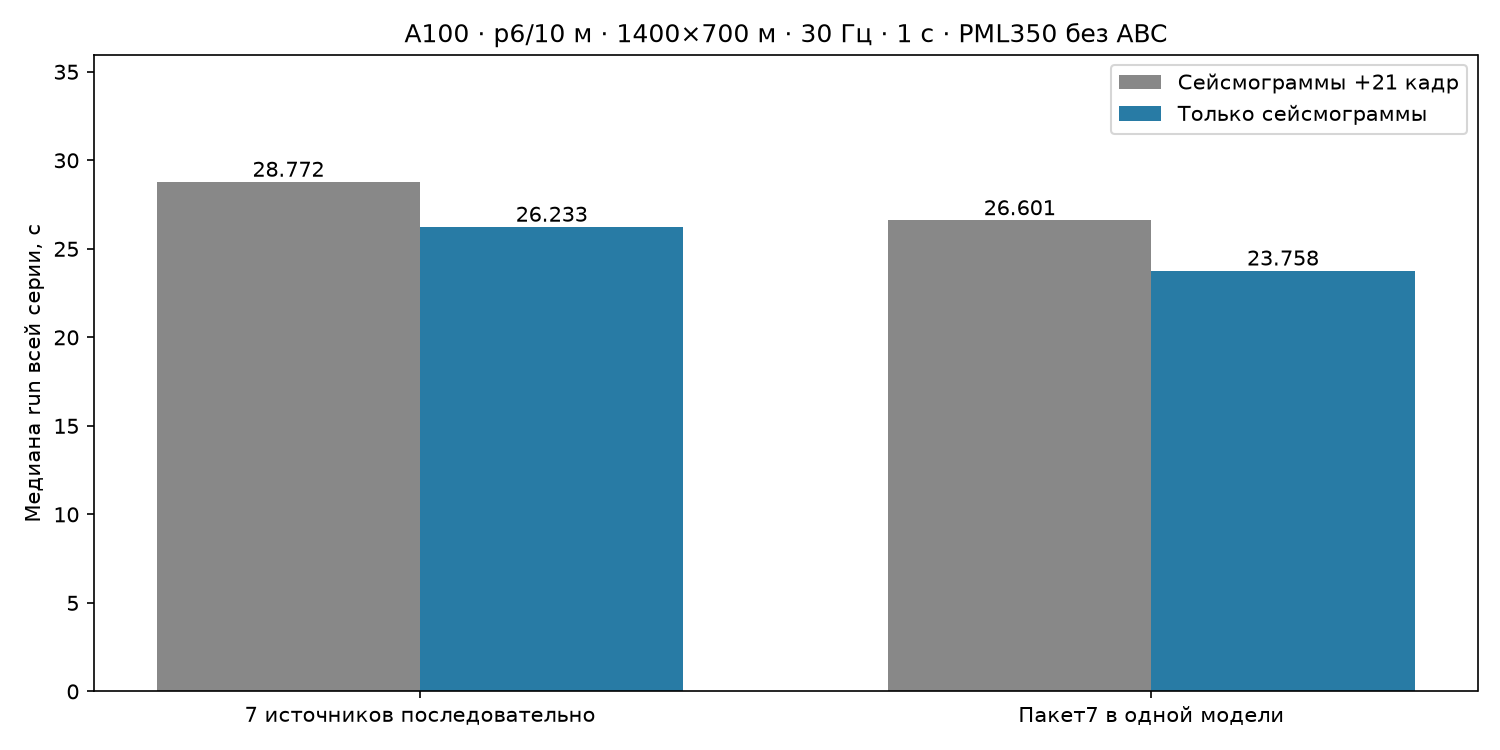

In [19]:
chapter15_surface_only_root = PROJECT_ROOT / "data/dev_1_5_geometry_frequency/pml_p6_sources7_surface_v1"
chapter15_surface_only_metrics_path = chapter15_surface_only_root / "analysis/metrics.json"
if chapter15_surface_only_metrics_path.exists():
    chapter15_surface_only_metrics = read_json(chapter15_surface_only_metrics_path)
    assert chapter15_surface_only_metrics["status"] == "completed"
    assert chapter15_surface_only_metrics["all_agree"] is True
    assert chapter15_surface_only_metrics["field_frames_per_source"] == 0
    print("Последовательно, с:", chapter15_surface_only_metrics["median_sequential_run_seconds"])
    print("Пакет, с:", chapter15_surface_only_metrics["median_batch_run_seconds"])
    print("На источник в пакете, с:", chapter15_surface_only_metrics["equivalent_batch_seconds_per_source"])
    print("Ранее с кадрами:", chapter15_surface_only_metrics["with_fields_baseline"])
    display(Image(filename=str(PROJECT_ROOT / "img/dev_1_5_geometry_frequency/pml_p6_sources7_surface_v1/timings.png"), width=1000))
else:
    print("Итоговые метрики серии без кадров ещё не сохранены локально.")

Три измеряемых пары «сумма семи одиночных run → пакет», только сейсмограммы:26,148482→23,757630 с;26,239199→23,736971 с;26,232649→23,884198 с. Медианы26,232649→23,757630 с, ускорение пакета1,104178 раза, экономия9,43488%. Эквивалентное время на источник в пакете3,393947 с. С построением модели и prepare до завершения run медианы33,930859→29,926533 с, ускорение1,133805 раза.

По сравнению с предыдущей серией с21 полным кадром на источник пакет ускорился26,600856→23,757630 с, экономия10,68848% (2,843226 с). Сумма одиночных ускорилась28,772195→26,232649 с, экономия8,82639%. Это удаление полного полевого приёмника и сопутствующей передачи/регистрации кадров, не только исключение вызова сохранения файла. Времена разных режимов взяты из отдельных серий при одной среде и неизменной физике; точную стоимость дискового ввода-вывода этот эксперимент не отделяет. Сохранение surface.npz, постобработка и хеширование не входят в приведённый model.run.

Число поверхностных приёмников сохранено:1261 узел, включая PML,1001 отсчёт, обе компоненты float64. Уменьшение до производственного числа датчиков здесь не проверялось. Объём32 новых surface.npz составляет1132396928 байт (около1,055 ГиБ); кадры отсутствуют. Более низкая стоимость хранения не означает пропорционального ускорения самого решения: оно по-прежнему рассчитывает поле во всех узлах.

Все21 пары «источник×повтор» нового пакета и одиночных согласовались, максимум относительной L2 компонент2,91135e−14. Все32 новых сейсмограммы совпали с соответствующими прежними запусками с кадрами до2,93081e−14. Проверены32 новых и32 прежних SHA поверхностных файлов. Новые сейсмограммы и конечная память PML конечны; отсутствие новых полных кадров не позволяет заявлять новую проверку конечности поля скорости во всех узлах. Поля предыдущей серии сохранены неизменными.

Входы: pml_p6_sources7_surface_cpu_v1/plan.json, прежние snapshot/runtime fixed_pml_orders_v1 и32 сейсмограммы pml_p6_sources7_v1. Выходы: data/dev_1_5_geometry_frequency/pml_p6_sources7_surface_v1/{plan,environment,step_plan,runs_completed,artifact_validation,completion}.json, analysis/metrics.json, sources7_surface.log и p6_h10/fixed/* с результатами. Surface.npz остаются на Saturn; локально метаданные и отчёт img/dev_1_5_geometry_frequency/pml_p6_sources7_surface_v1/{index.html,timings.png,render.json}. После завершения обе GPU свободны; свободно64137068544 байт (59,73 ГиБ). Производственная очередь остаётся остановленной. Новых GPU-запусков для этого сравнения не требуется.

## 19. Специализированный p6_7s: общая сетка семи источников ##

Пользователь подготовил решатель lin_elast_2d_seismic_newmark_kim_p6_7s_cu и заранее разрешил передачу кода через Git для сравнения на A100. Постановка сохраняет двухслойную1400×700 м, h10/p6, PML350 м с dmax173,0886108476381 с⁻¹, без ABC и граничных элементов, Рикер30Гц вниз1 Н/м,1 с, β=1/27, γ=0,5, native CFL0,8. Семь источников x175…1225 через175 м; сохраняются только Vx/Vy во всех1261 GLL-узлах полного верха с интервалом0,001 с, включая PML. Новая серия p6_7s_comparison_v2 сравнивает замороженный p6 из §18, актуальный p6 и p6_7s. Прогрев каждого варианта и три циклически переставляемых повтора выполняются последовательно на одной A100GPU0; всего12 полных запусков и3 CFL-probe.

В p6_7s хранится одна сетка795691 узел/22050 элементов вместо семи несвязанных копий5569837 узлов/154350 элементов. Координаты, связность, масса и материалы общие, а состояния u/v/a и история PML независимы для каждого источника. На элементах слоя упругий и PML-отклик объединены в одном ядре. Верхний ряд1261 узла должен занимать первые номера, поэтому with_leading_nodes переставляет N и связность без изменения координат локальных узлов элементов. Фактические источники — узлы315,420,525,630,735,840,945. Узловое состояние имеет42 строки, PML-history —28 строк на600250 локальных точек слоя.

Актуальный контракт p6_7s принимает только физики11000/31100: сила встроена и активный объект20200 запрещён. Параметры Рикера и положения источников фиксированы при сборке. Prepare вычисляет аналитический Рикер на фактических внутренних шагах и единожды загружает значения на GPU; прежний p6 использует кубическую интерполяцию таблицы с шагом1 мкс и динамический перенос силы. Поэтому сравнение измеряет совокупный эффект специализации, а не вклад одного ядра. Все сейсмограммы сравниваются по каждому источнику и компоненте, включая окрестность силы и верх PML; допуски relative L2<1e−8 и пик разности/пик эталона<1e−7. Дополнительный эталон — исторический пакет §18. Это проверка эквивалентности реализаций, не пространственной сходимости.

Снимок seismic_p6_7s_v1 содержит текущий рабочий код и SHA256, сборка .runtime_ch15_p6_7s_v1 изолирована от прежнего runtime. Передача разрешена пользователем; коммиты2a9eaa9/bb81271. Первоначальная попытка p6_7s_comparison_v1 остановилась после CFL-probe из-за повторной записи JSON в обёртке; история сохранена, метаданные сравнения теперь пишутся отдельно. Производственная очередь не возобновляется. Далее читаются только сохранённые метрики; дневник не запускает решатель.

Времена трёх реализаций: [{'variant': 'frozen_p6', 'run_seconds': [23.58437338937074, 23.70915485266596, 23.68716062232852], 'assembly_seconds': [4.498839032836258, 4.313141155987978, 4.311903293244541], 'prepare_seconds': [1.9012063909322023, 1.9075106093659997, 1.8703097077086568], 'solve_wall_seconds': [29.985134722664952, 29.93021373450756, 29.869780963286757], 'median_run_seconds': 23.68716062232852, 'median_solve_wall_seconds': 29.93021373450756}, {'variant': 'current_p6', 'run_seconds': [23.668277537450194, 23.669796623289585, 23.638373411260545], 'assembly_seconds': [4.33414339646697, 4.375415152870119, 4.388401361182332], 'prepare_seconds': [1.8932215496897697, 1.9002393037080765, 1.931581748649478], 'solve_wall_seconds': [29.896060386672616, 29.945847714319825, 29.95928223244846], 'median_run_seconds': 23.668277537450194, 'median_solve_wall_seconds': 29.945847714319825}, {'variant': 'p6_7s', 'run_seconds': [23.32481638621539, 23.379265184514225, 23.349675204604864], 'assembly

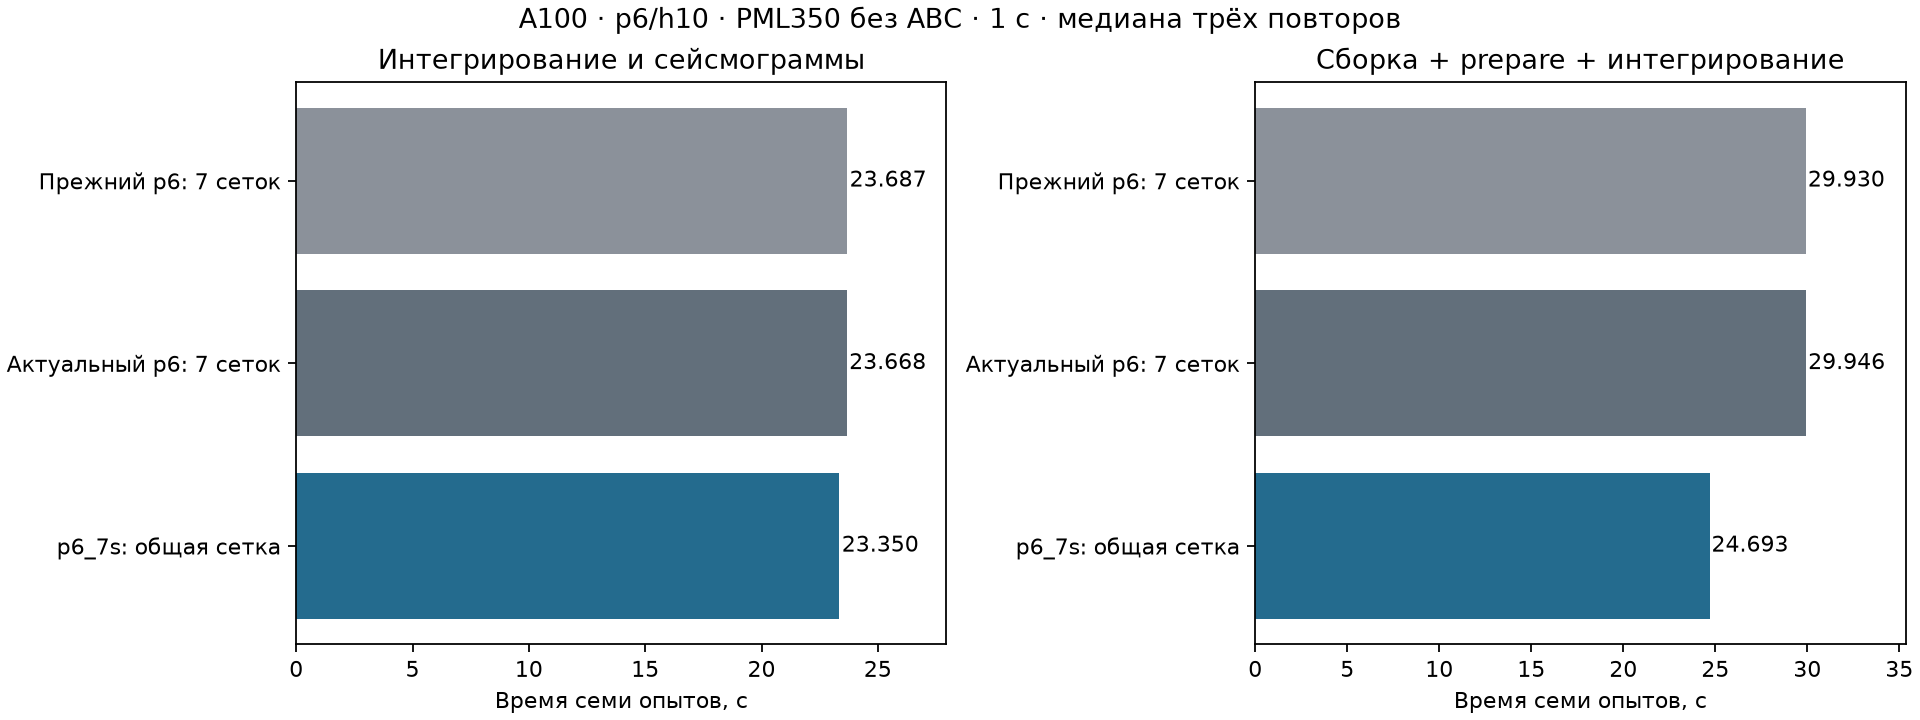

In [20]:
chapter15_p6_7s_root = PROJECT_ROOT / "data/dev_1_5_geometry_frequency/p6_7s_comparison_v2"
chapter15_p6_7s_metrics_path = chapter15_p6_7s_root / "analysis/metrics.json"
if chapter15_p6_7s_metrics_path.exists():
    chapter15_p6_7s_metrics = read_json(chapter15_p6_7s_metrics_path)
    assert chapter15_p6_7s_metrics["status"] == "completed"
    print("Времена трёх реализаций:", chapter15_p6_7s_metrics["timings"])
    print("Максимальная относительная L2:", chapter15_p6_7s_metrics["max_relative_l2"])
    display(Image(filename=str(PROJECT_ROOT / "img/dev_1_5_geometry_frequency/p6_7s_comparison_v2/timing.png"), width=1100))

Входы: docs/runtime_sources/seismic_p6_7s_v1, прежний runtime fixed_pml_orders_v1, CPU-планы p6_7s_comparison_cpu_v1/v2, историческая сейсмограмма pml_p6_sources7_surface_v1/p6_h10/fixed/batch7_repeat0/surface.npz на Saturn. Выходы: p6_7s_comparison_v2/{plan,environment,step_plan,runs_completed}.json, analysis/metrics.json, метаданные и surface.npz для трёх вариантов; локальный отчёт img/dev_1_5_geometry_frequency/p6_7s_comparison_v2/{index.html,timing.png,central_seismograms.png,manifest.json}. Полные новые поверхности остаются на Saturn. Серия завершена; итоговые свидетельства artifact_validation.json/completion.json сохраняются в локальном каталоге серии.

Итог: завершены12 полных запусков и3 probe. Все три реализации выбрали dt=1/9000 с, K9. Медианы run прежнего p6/актуального p6/p6_7s:23,687161/23,668278/23,349675 с. Новый вариант уменьшает время интегрирования на1,42476% относительно прежнего пакета и1,34612% относительно актуального p6; эквивалентно3,335668 с на источник. Существенного ускорения самого run в этом тесте нет. Медианы assembly+prepare+run:29,930214/29,945848/24,693319 с; новый вариант уменьшает эту стоимость на17,4970% относительно прежнего. Основной измеренный выигрыш приходится на подготовку: у p6_7s сборка около1,1 с и prepare около0,25 с вместо4,3–4,5 с и1,9 с у пакетов p6. Это не полное время внешнего процесса с записью NPZ и хешированием.

Проверены84 сравнения по источникам/вариантам/повторам, каждое по Vx/Vy, и13 SHA поверхностей:12 новых плюс исторический пакет. Максимальная компонентная относительная L2 между реализациями2,9372735753e−14; все полные записи согласованы в прежних допусках. Кадры не регистрировались; подтверждена конечность поверхностей и итоговой PML-history, но не выполнен новый полноузловой контроль скорости. Независимая CPU-оценка различия интерполированного и аналитического источника даёт max1,69e−15 Н/м; фактическое сравнение полных сейсмограмм является основным критерием эквивалентности.

Выборочные наблюдения nvidia-smi во время run: p6_7s1004 MiB и актуальный пакет p61650 MiB. Это наблюдаемые выделения памяти процесса, не измеренные максимумы; ранний снимок416 MiB относится к подготовке и не используется для сравнения. Общая геометрия уменьшает постоянные данные, но семь независимых полей и историй PML продолжают обновляться; семикратного уменьшения арифметической работы нет. Разложение стоимости по ядрам в данном опыте не измерялось.

Визуально проверены timing.png и central_seismograms.png; сейсмограммы показаны в линейных знаковых шкалах, разность имеет отдельную шкалу. Три SHA артефактов совпали после переноса, две локальные ссылки HTML исправны. Полные NPZ остаются на Saturn, свободно62406307840 байт; обе GPU освобождены. Основная производственная очередь остаётся остановленной. Расчёты этой завершённой серии повторять не требуется.

## 20. Оптимизированный p67s: приёмник и профили CUDA ##

После переименования p6_7s в p67s пользователь поручил сравнение и профилирование на A100, отдельно спросив о стоимости асинхронной записи. Уточнение пользователя ограничивает опыт существующим приёмником сейсмограмм: SEG-Y не записывается. В предыдущих опытах callback собирал RAM-массив при run(sync=True), а NPZ записывался после окончания таймера. Новая серия сохраняет модель §19: двухслойная1400×700 м, p6/h10,7 источников Рикера30Гц,1 с, PML350 без ABC, beta1/27, gamma0,5, native CFL0,8. Все1261 GLL-узел полного верха,1001 отсчёт Vx/Vy.

Новый p67s вычисляет обратные массы при запуске, переносит матрицу производных p6 в shared memory и объединяет промежуточный корректор с предиктором следующего шага внутри такта. Сравнение использует неизменённый прежний p6_7s и отдельный снимок/сборку seismic_p67s_v1/.runtime_ch15_p67s_v1. Native-исходники не изменялись при подготовке эксперимента. Верх перенумерован первым; источник встроенный, задаются только физики11000/31100.

Пять режимов: старый p6_7s с синхронным приёмником; p67s вообще без приёмника; p67s с синхронным захватом/переносом и проверками без накопления; p67s с прежним синхронным накоплением в RAM; p67s с асинхронным накоплением, frame_buf_size4 и run(sync=False).wait(). Таймер последнего режима заканчивается после опустошения принадлежащей native очереди. Режим без приёмника сохраняет1000 тактов и штатный конечный SAVE; это не полное отключение D2H и синхронизаций. Разность «приём без накопления»/«без приёмника» включает GPU-gather, перенос, очередь и проверки; разность с накоплением оценивает добавку Python-копирования в постоянный массив.

После полного прогрева каждого режима проводятся пять циклически переставляемых раундов на одной A100GPU0, всего30 запусков плюс2 CFL-probe. Отдельно снимаются5 профилей Nsight CUDA/NVTX с этапами semgpu_prepare/semgpu_run/output_npz, без CPU sampling; профилированные времена не входят в медианы. Ядра суммируются по именам с сохранением шаблонных флагов; GPU-интервалы объединяются для оценки фактической занятости. Host CUDA API, GPU и D2H перекрываются и не складываются; остаток вне GPU не отождествляется со стоимостью приёмника.

Сейсмограммы синхронного/асинхронного режимов сравниваются с прежним решателем по всем источникам и узлам; конечный верх проверяется во всех режимах. После таймера из штатного terminal SAVE читается конечное полное состояние, проверяется конечность; полное поле скорости сохраняется для пяти прогревов и сравнивается во всех узлах. Память PML также проверяется на конечность. Это не история полного поля во времени. Допуски остаются1e−8 по компонентной L2 и1e−7 по относительному пику.

Медианное ускорение p67s: 1.3755911260698408
Вклад синхронного приёмника, с: 0.19842938613146544
Вклад асинхронного приёмника, с: 0.03213883098214865


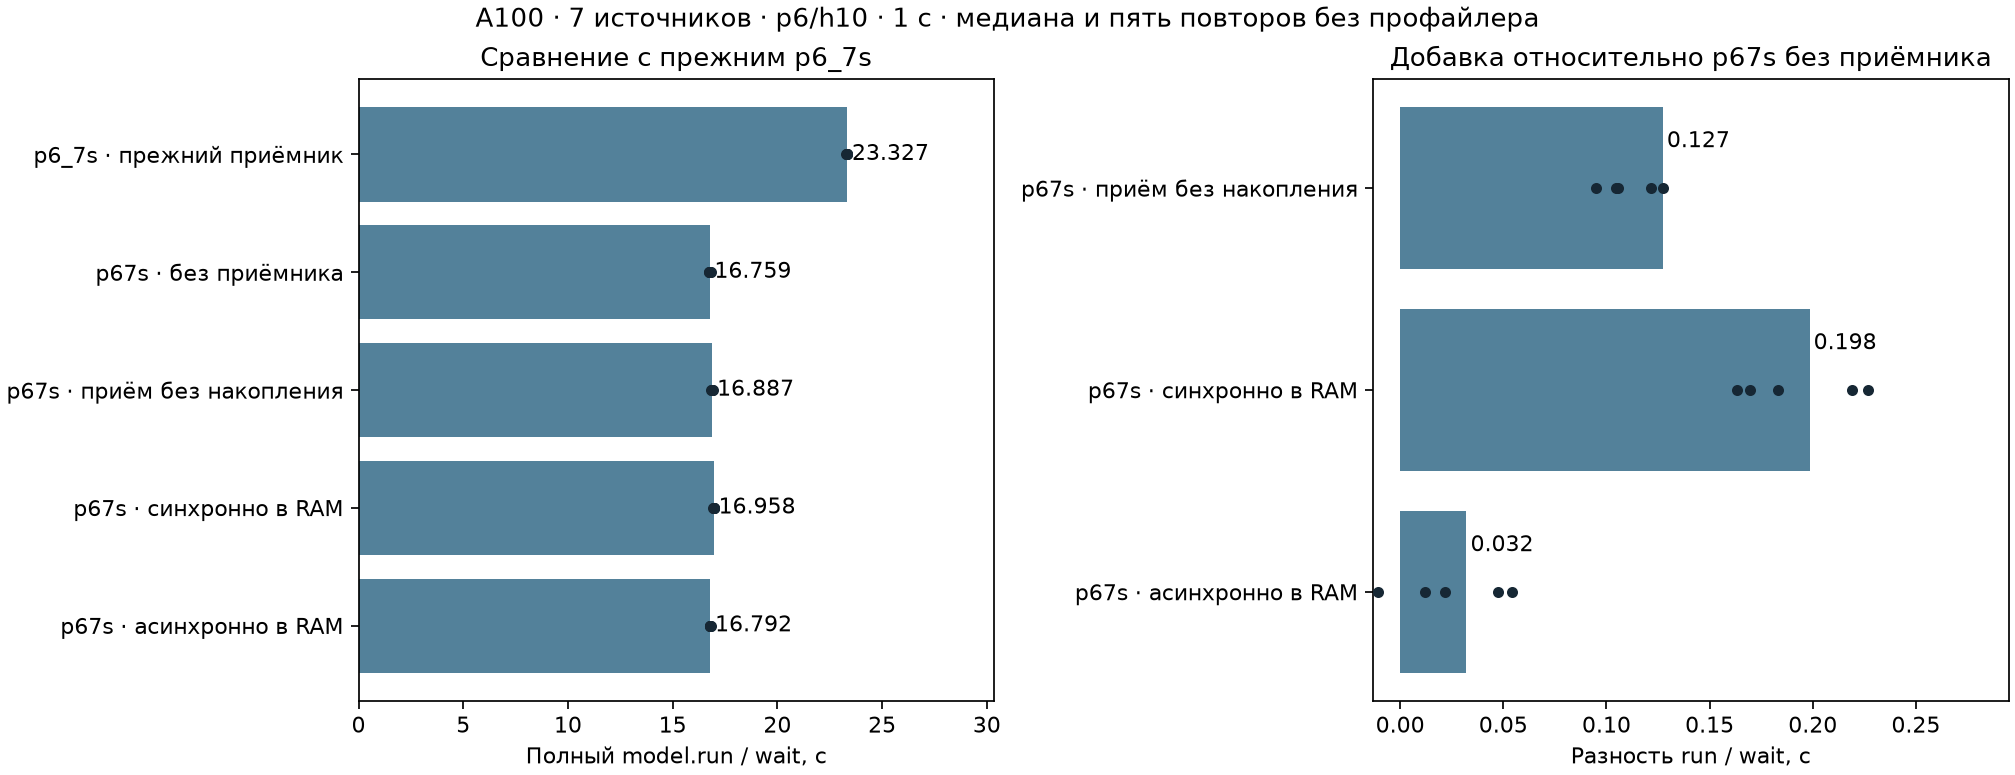

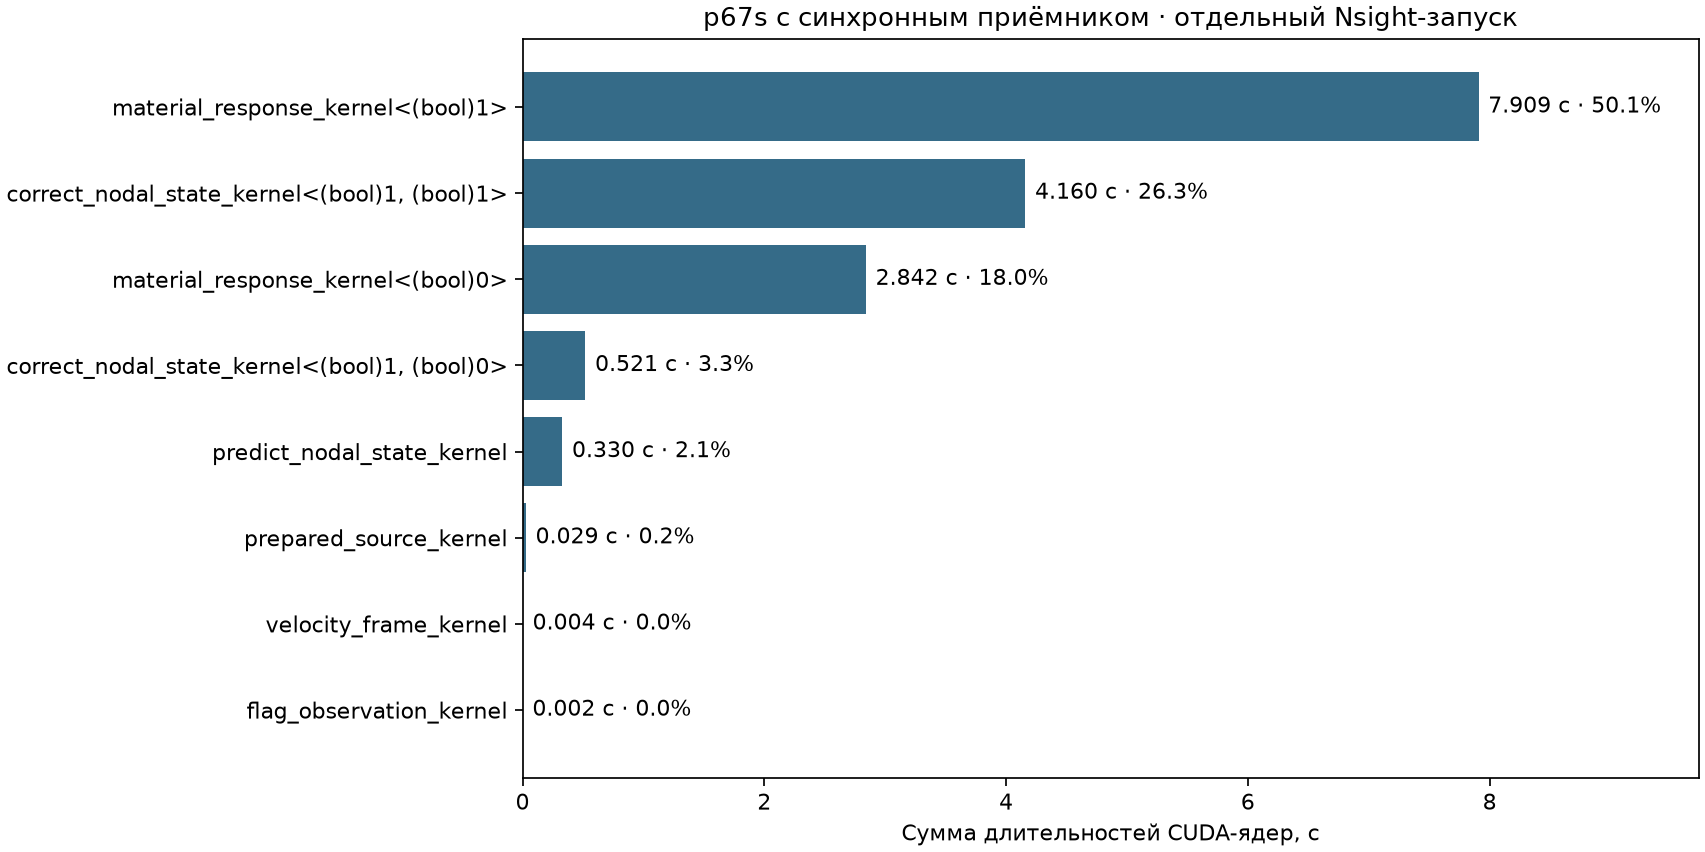

In [21]:
chapter15_p67s_root = PROJECT_ROOT / "data/dev_1_5_geometry_frequency/p67s_receiver_v1"
chapter15_p67s_metrics_path = chapter15_p67s_root / "analysis/metrics.json"
if chapter15_p67s_metrics_path.exists():
    chapter15_p67s_metrics = read_json(chapter15_p67s_metrics_path)
    assert chapter15_p67s_metrics["status"] == "completed"
    print("Медианное ускорение p67s:", chapter15_p67s_metrics["new_vs_old_speedup"])
    print("Вклад синхронного приёмника, с:", chapter15_p67s_metrics["sync_receiver_overhead_seconds"])
    print("Вклад асинхронного приёмника, с:", chapter15_p67s_metrics["async_receiver_overhead_seconds"])
    display(Image(filename=str(PROJECT_ROOT / "img/dev_1_5_geometry_frequency/p67s_receiver_v1/reviewed_v2/timings.png"), width=1150))
    display(Image(filename=str(PROJECT_ROOT / "img/dev_1_5_geometry_frequency/p67s_receiver_v1/reviewed_v2/kernels.png"), width=1100))

Входы: docs/runtime_sources/seismic_p67s_v1, старый runtime .runtime_ch15_p6_7s_v1, CPU-план p67s_receiver_cpu_v1/plan.json. Код scripts/dev_1_5_geometry_frequency/{build_p67s.sh,p67s_run.py,p67s_analyze.py,p67s_report.py} передан через Git. Выходы: data/dev_1_5_geometry_frequency/p67s_receiver_v1/{plan,environment,step_plan,runs_completed}.json, каталоги пяти режимов с result.json/final_top.npy, surface.npz в режимах накопления и final_velocity.npy в прогревах; profiles/<mode>/{trace.nsys-rep,trace.sqlite,profile_summary.json,profile.log,export.log}, analysis/metrics.json. Массивы и полные профили остаются на Saturn. Локальные иллюстрации img/dev_1_5_geometry_frequency/p67s_receiver_v1/{index.html,timings.png,kernels.png,manifest.json}. Основная очередь не изменяется.

Серия завершена:30 непрофилированных запусков,2 CFL-probe и5 дополнительных полных Nsight-запусков, всего35 полных расчётов. Медианы run: прежний p6_7s23,327172 с; p67s без приёмника16,759496 с; p67s без накопления16,886798 с; p67s синхронно в RAM16,957926 с; p67s асинхронно в RAM16,791635 с. При одинаковом синхронном приёмнике ускорение1,375591 раза, сокращение времени27,3040%. Асинхронный вариант даёт2,398805 с на источник. Все используют9000 шагов dt=1/9000 с.

Добавка синхронного приёмника по разности медиан0,198429 с,1,1840% времени без приёмника. Асинхронного —0,032139 с,0,1918%, но парные разности по раундам от−0,010955 до+0,054057 с; такой малый эффект сопоставим с разбросом. Медиана суммы времени самого Python-callback0,169894 с синхронно и0,527318 с асинхронно; последнее перекрывается с GPU и не суммируется с run. Сохранение141 МБ сейсмограмм в NPZ после таймера занимает около0,212–0,217 с; это запись в ОС без измерения fsync, не SEG-Y.

В профиле new_sync сумма длительностей ядер15,796722 с. PML material_response_kernel<(bool)1>:7,909164 с,50,068%; корректор с предиктором8000 вызовов:4,160447 с,26,337%; обычный материал:2,841528 с,17,988%; корректор конца такта1000 вызовов:0,520752 с,3,297%; отдельный предиктор1000 вызовов:0,329940 с,2,089%; источник0,028539 с. Ядра захвата и проверки приёмника занимают0,003888+0,002465 с. По сравнению со старым профилем PML11,275014→7,909164 с, обычный материал3,403203→2,841528 с, отдельный предиктор2,992574→0,329940 с; корректор в сумме остаётся около4,68 с. Это сравнение совокупно изменённой реализации, не отдельные ablation-проверки каждого исправления. Основные расходы остаются в PML и обновлении состояния.

D2H в new_sync занимает0,180152 с на543185412 байт, без приёмника0,163739 с на401808176 байт; добавка около0,0164 с/141377236 байт. Большая часть обязательного D2H — конечный SAVE состояния и памяти PML, а не сейсмограммы. NVTX-run16,986287 с, объединённая GPU-активность16,640754 с; оставшиеся0,345533 с не следует целиком приписывать приёмнику. В async остаток0,143745 с, без приёмника0,114251 с. API-ожидания и GPU-интервалы перекрываются. Во всех5 трассах проверки числа запусков прошли: старый предиктор9000, новый1000, корректор9000, приёмник1001 либо0. Диагностика Nsight информационная, потерь CUDA-событий не обнаружено.

161 численное сравнение и61 SHA массивов прошли. Максимальная компонентная L2 сейсмограмм2,9539119318e−14, max|Δv|1,3864e−21 м/с. Для конечного полного поля L2≤7,91692e−10 и абсолютная разность≤2,39286e−23 м/с; конечный верх L2≤5,99552e−9. Более высокая относительная ошибка конечного состояния связана с малостью остатка к1 с; прежние критерии1e−8/1e−7 сохранены. Совпадение реализаций не является независимым доказательством пространственной сходимости.

Финальный локальный отчёт img/dev_1_5_geometry_frequency/p67s_receiver_v1/reviewed_v2/index.html сохраняет все парные точки, включая небольшую отрицательную разность async; исходные renderer-артефакты остаются рядом. Локально скопированы5 trace.nsys-rep суммарно около14 МБ, их SHA проверены; trace.sqlite и расчётные массивы остаются на Saturn. Первоначальный запуск анализа потребовал устранить зависимость от старого локального profile_analysis.py; профиль и численные расчёты не повторялись. После завершения обе GPU свободны,58569900032 байт диска свободно. Производственная очередь остаётся остановленной.